# LG tests July '26


In [409]:
MAX_LG_POWER = 15 ## REMEASURED AT 1 PM on 10 July

# Initialization

In [37]:
import json
from collections import defaultdict
import os
import subprocess
import sys
import threading
import time
from pathlib import Path
ma = lambda ar, win_size: np.convolve(ar, np.ones(win_size) / win_size, mode="valid")

import numpy as np
import matplotlib.pyplot as plt
import Pyro4
from scipy.optimize import curve_fit
Pyro4.config.SERIALIZER = "pickle"
Pyro4.config.SERIALIZERS_ACCEPTED = {"pickle"}
Pyro4.config.SERVERTYPE = "thread"
Pyro4.config.THREADPOOL_SIZE = 20
Pyro4.config.THREADPOOL_SIZE_MIN = 4

SERVER_URI = "PYRO:PumpProbeAnalysis@127.0.0.1:9112"
SERVER_SCRIPT = Path.cwd() / "PicoHarp_analysis_PP_srv.py"
server_process = None

try:
    stop_logs.set()
except NameError:
    pass


def start_local_server_if_needed(uri=SERVER_URI):
    global server_process
    try:
        probe = Pyro4.Proxy(uri)
        probe.ping()
        return
    except Exception:
        pass

    if server_process is not None and server_process.poll() is None:
        return

    server_process = subprocess.Popen(
        [sys.executable, "-u", str(SERVER_SCRIPT)],
        cwd=str(SERVER_SCRIPT.parent),
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
        text=True,
    )
    deadline = time.time() + 10.0
    last_error = None
    while time.time() < deadline:
        try:
            probe = Pyro4.Proxy(uri)
            probe.ping()
            print(f"Started local pump-probe server from {SERVER_SCRIPT}")
            return
        except Exception as exc:
            last_error = exc
            time.sleep(0.2)
    raise RuntimeError(f"Could not start pump-probe server at {uri}: {last_error}")


def analysis_setup(uri=SERVER_URI):
    global analysis_cmd, stop_logs
    start_local_server_if_needed(uri)
    analysis_cmd = Pyro4.Proxy(uri)
    stop_logs = threading.Event()

    def log_poller():
        analysis_log = Pyro4.Proxy(uri)
        idx = 0
        progress_active = False
        while not stop_logs.is_set():
            try:
                idx, lines = analysis_log.get_logs(idx, timeout=2.0)
                for line in lines:
                    if line.startswith("\r"):
                        sys.stdout.write("\r\033[K")
                        sys.stdout.write(line[1:])
                        sys.stdout.flush()
                        progress_active = True
                    else:
                        if progress_active:
                            sys.stdout.write("\n")
                            sys.stdout.flush()
                            progress_active = False
                        print(line, flush=True)
            except Exception as exc:
                if progress_active:
                    sys.stdout.write("\n")
                    sys.stdout.flush()
                    progress_active = False
                print(f"[log poller] {exc}", flush=True)
                time.sleep(0.5)
            time.sleep(0.2)

    threading.Thread(target=log_poller, daemon=True).start()
    print("------------------ LOG ------------------", flush=True)
    analysis_cmd.ping()
    return analysis_cmd




In [38]:
def find_nearest(ar, val):
    return np.argmin( np.abs( ar - val))


In [39]:
### VOA calibration

VOA_VOLTAGES = np.array(
    [
        0.0,
        0.8,
        1.0,
        1.2,
        1.4,
        1.6,
        1.8,
        2.0,
        2.2,
        2.4,
        2.6,
        2.8,
        3.0,
        3.2,
        3.225,
        3.25,
        3.275,
        3.3,
        3.325,
        3.35,
        3.375,
        3.4,
        3.425,
        3.45,
        3.475,
        3.5,
        3.525,
        3.55,
        3.575,
        3.6,
        3.625,
        3.65,
        3.675,
        3.7,
        3.725,
        3.75,
        3.775,
        3.8,
        3.825,
        3.85,
        3.875,
        3.9,
        3.925,
        3.95,
        3.975,
    ],
    dtype=float,
)

VOA_POWER_FRACTIONS = np.array(
    [
        1.0,
        0.97866687,
        0.95602682,
        0.91982652,
        0.86489718,
        0.78977824,
        0.69225815,
        0.57718614,
        0.45179647,
        0.32998444,
        0.2226647,
        0.13935394,
        0.07988371,
        0.04761197,
        0.04385179,
        0.04042021,
        0.03592319,
        0.03312505,
        0.03054551,
        0.02790377,
        0.02550368,
        0.02304211,
        0.02073726,
        0.01943311,
        0.01782744,
        0.01612749,
        0.01452542,
        0.01298301,
        0.01174557,
        0.01091037,
        0.00988294,
        0.00892775,
        0.0079836,
        0.00729239,
        0.00670662,
        0.00619417,
        0.00558329,
        0.00518218,
        0.00468534,
        0.00431989,
        0.00413461,
        0.00381595,
        0.00345153,
        0.00328222,
        0.00306277,
    ],
    dtype=float,
)
voa_erf_transmission_norm = lambda v: np.interp(v, VOA_VOLTAGES, VOA_POWER_FRACTIONS)


In [40]:
analysis_cmd = analysis_setup()


------------------ LOG ------------------


# Sync-clock pump-probe analysis 
CH1 resets the clock; CH0 photons are folded relative to the most recent CH1 tick.

In [41]:
# Compact overlay helper for CH1-sync-folded pump-probe traces
import json
from pathlib import Path
Vs = np.array([
    0., 0.01, 0.02, 0.03, 0.04, 0.05, 0.052, 0.054, 0.056, 0.058, 0.06, 0.062,0.064, 0.066, 0.068, 0.07, 0.072, 0.074, 0.076, 0.078, 0.08, 0.082, 0.084, 0.086,0.088, 0.09, 0.092, 0.094, 0.096, 0.098, 0.1, 0.102, 0.104, 0.106, 0.108, 0.11,0.112, 0.114, 0.116, 0.118, 0.12, 0.122, 0.124, 0.126, 0.128, 0.13, 0.132, 0.134,0.136, 0.138, 0.14, 0.142, 0.144, 0.146, 0.148, 0.15, 0.152, 0.154, 0.156, 0.158,0.16, 0.162, 0.164, 0.166, 0.168, 0.17, 0.172, 0.174, 0.176, 0.178, 0.18, 0.182,0.184, 0.186, 0.188, 0.19, 0.192, 0.194, 0.196, 0.198, 0.2, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1., 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2., 2.1, 2.2, 2.3, 2.4, 2.5, 2.6, 2.7, 2.8,2.9, 3., 3.1, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, 3.9, 4.,4.1, 4.2, 4.3, 4.4, 4.5, 4.6, 4.7, 4.8, 4.9
])

ctrs = np.array([
	400, 430, 430, 360, 440, 470, 380, 430, 360, 420, 380, 340, 330, 360, 310, 280, 420, 450, 510, 560, 430, 430, 1470, 1480, 2380, 5500, 5740, 6190, 6410, 6650, 6650, 7260, 7490, 7200, 7610, 8090, 8270, 8250, 8840, 8660, 9200, 9520, 10100, 10340, 10740, 10840, 11520, 12150, 11930, 12800, 12850, 13180, 13680, 14170, 13960, 14660, 15410, 15720, 15880, 15690, 16730, 17310, 16970, 17970, 17700, 17990, 18530, 19550, 18710, 19510, 20340, 20070, 20660, 21340, 21040, 21970, 23430, 23330, 23940, 24420, 24760, 50990, 52330, 92990, 136410, 181410, 235490, 286730, 335120, 387630, 429760, 472010, 513920, 540760, 571080, 594410, 620600, 625220, 642430, 662220, 672910, 688610, 691690, 700490, 703110, 712670, 730410, 730350, 741580, 752220, 764430, 767470, 771600, 776950, 778210, 783900, 788720, 788890, 791660, 798350, 788560, 791910, 807100, 799510, 806650, 808940, 811510, 809950, 815130
])
AOM_transmission_norm = lambda V: np.interp(V, Vs, ctrs/np.max(ctrs))
V_from_transmission = lambda T: np.interp(T, ctrs/np.max(ctrs), Vs)

DATA_ROOT = ""
def _as_acq_paths(filenames, data_root=None):
    paths = []
    if data_root is None:
        data_root = DATA_ROOT
    data_root = Path(data_root)
    for item in filenames:
        if isinstance(item, (int, np.integer)):
            index = int(item)
            regular = data_root / f"acq_{index}.b"
            reference = data_root / f"acq_reference_{index}.b"
            existing = []
            for candidate in (regular, reference):
                if candidate.exists() or _metadata_path_for_b_file(candidate).exists():
                    existing.append(candidate)
            if len(existing) > 1:
                raise ValueError(f"Acquisition index {index} matches both {regular.name} and {reference.name}.")
            paths.append(existing[0] if existing else regular)
        else:
            path = Path(item)
            if not path.is_absolute():
                path = data_root / path
            paths.append(path)
    return paths


def _metadata_path_for_b_file(filepath):
    filepath = Path(filepath)
    return filepath.with_name(f"{filepath.stem}_metadata.json")


def _metadata_value(filepath, key):
    metadata_path = _metadata_path_for_b_file(filepath)
    with metadata_path.open("r", encoding="utf-8") as f:
        payload = json.load(f)

    value = payload
    for part in key.split("."):
        value = value[part]
    return value


def _acq_number_from_path(filepath):
    stem = Path(filepath).stem
    if stem.endswith("_metadata"):
        stem = stem[:-len("_metadata")]
    if stem.startswith("acq_reference_"):
        suffix = stem[len("acq_reference_"):]
    elif stem.startswith("acq_"):
        suffix = stem[len("acq_"):]
    else:
        raise ValueError(f"Could not parse acquisition number from {filepath!r}.")
    if not suffix.isdigit():
        raise ValueError(f"Could not parse acquisition number from {filepath!r}.")
    return int(suffix)


def _metadata_is_reference_payload(payload):
    if not isinstance(payload, dict):
        return False
    metadata = payload.get("metadata", {}) if isinstance(payload.get("metadata", {}), dict) else {}
    measurement_type = str(metadata.get("measurement_type", payload.get("measurement_type", ""))).strip().lower()
    is_reference = metadata.get("is_reference_measurement", payload.get("is_reference_measurement", False))
    return measurement_type == "reference" or is_reference is True


def _metadata_is_reference_file(filepath):
    path = Path(filepath)
    if path.stem.startswith("acq_reference_"):
        return True
    try:
        return _metadata_is_reference_payload(_metadata_payload_for_b_file(path))
    except FileNotFoundError:
        return False


def _metadata_acq_index_from_payload_or_path(payload, path):
    for key in (("acq_index",), ("metadata", "acq_index")):
        value = payload
        try:
            for part in key:
                value = value[part]
            return int(value)
        except (KeyError, TypeError, ValueError):
            pass
    return _acq_number_from_path(path)


def _analysis_cache_exists_for_b_file(filepath):
    filepath = Path(filepath)
    folder = filepath.with_name(f"{filepath.stem}_pump_probe_folded")
    return folder.exists() and any(folder.glob("*.npz"))


def _metadata_payload_for_b_file(filepath):
    metadata_path = _metadata_path_for_b_file(filepath)
    with metadata_path.open("r", encoding="utf-8") as f:
        return json.load(f)


def _metadata_value_from_payload(payload, key):
    value = payload
    for part in key.split("."):
        value = value[part]
    return value


_METADATA_FILTER_ALIASES = {
    "b_field": "metadata.B_field",
    "B_field": "metadata.B_field",
    "B": "metadata.B_field",
    "vmu": "metadata.Vmu",
    "Vmu": "metadata.Vmu",
    "ve": "metadata.ve",
    "pump_wl": "metadata.pump wl",
    "pump_wavelength": "metadata.pump wl",
    "amp_x": "metadata.pulse_parameters.amp_x",
    "amp_x_meas": "metadata.pulse_parameters.amp_x_meas",
    "amp_det_meas": "metadata.pulse_parameters.amp_det_meas",
    "t_x": "metadata.pulse_parameters.t_x",
    "t_meas": "metadata.pulse_parameters.t_meas",
    "buffer": "metadata.pulse_parameters.buffer",
}
_ROOT_METADATA_KEYS = {"acq_time_ms", "created_unix_time", "data_filename", "mode"}


def _normalize_metadata_filter_key(key):
    """Return a dotted key usable with _metadata_value_from_payload.

    Short names are interpreted inside the JSON "metadata" object. Use double
    underscores for nested keys in keyword arguments, e.g.
    pulse_parameters__t_x -> metadata.pulse_parameters.t_x. Use root__mode for
    top-level JSON fields outside the "metadata" object.
    """
    key = str(key)
    if key in _METADATA_FILTER_ALIASES:
        return _METADATA_FILTER_ALIASES[key]
    if key.startswith("root__"):
        return key[len("root__"):].replace("__", ".")
    if key.startswith("root."):
        return key[len("root."):]
    if key in _ROOT_METADATA_KEYS:
        return key
    if key.startswith("metadata__"):
        return "metadata." + key[len("metadata__"):].replace("__", ".")
    if key.startswith("metadata."):
        return key
    if "__" in key:
        return "metadata." + key.replace("__", ".")
    if "." in key:
        return "metadata." + key
    return "metadata." + key


def _normalize_metadata_filters(filters=None):
    if filters is None:
        return {}
    return {_normalize_metadata_filter_key(key): criterion for key, criterion in dict(filters).items()}


def _looks_like_metadata_key(text):
    text = str(text)
    return (
        text in _METADATA_FILTER_ALIASES
        or text in _ROOT_METADATA_KEYS
        or text.startswith(("metadata.", "metadata__", "root.", "root__"))
        or "." in text
        or "__" in text
    )


def _metadata_key_display_name(key):
    key = str(key)
    key = key.removeprefix("metadata.").removeprefix("root.")
    key = key.replace("__", ".")
    return key.split(".")[-1].replace("_", " ")


def _format_metadata_legend_value(value, fmt="g"):
    if isinstance(value, (np.integer, int)):
        if fmt in {None, "", "g"}:
            return str(int(value))
        return format(int(value), fmt)
    if isinstance(value, (np.floating, float)):
        return format(float(value), fmt if fmt else "g")
    if isinstance(value, np.ndarray):
        value = value.tolist()
    return str(value)


def _legend_metadata_items(legend_metadata):
    if legend_metadata is None:
        return []
    if isinstance(legend_metadata, (list, tuple)):
        return [(_metadata_key_display_name(key), key, {}) for key in legend_metadata]

    items = []
    for label, spec in dict(legend_metadata).items():
        options = {}
        if isinstance(spec, dict):
            key = spec.get("key", label)
            display = spec.get("label", label)
            options = dict(spec)
        elif spec is None:
            key = label
            display = _metadata_key_display_name(label)
        elif isinstance(spec, str) and _looks_like_metadata_key(spec):
            key = spec
            display = label
        else:
            key = label
            display = _metadata_key_display_name(label)
            options["unit"] = spec
        items.append((display, key, options))
    return items


def _metadata_legend_label(path, legend_metadata=None, *, default=None):
    if legend_metadata is None:
        return default if default is not None else Path(path).stem
    payload = _metadata_payload_for_b_file(path)
    parts = []
    for display, key, options in _legend_metadata_items(legend_metadata):
        normalized_key = _normalize_metadata_filter_key(key)
        try:
            value = _metadata_value_from_payload(payload, normalized_key)
        except KeyError:
            value_text = "?"
        else:
            value_text = _format_metadata_legend_value(value, options.get("fmt", "g"))
        unit = options.get("unit", "")
        if unit is None:
            unit = ""
        unit = str(unit)
        if unit and not unit.startswith((" ", "%", "/")):
            unit = " " + unit
        parts.append(f"{display} = {value_text}{unit}")
    return ", ".join(parts) if parts else (default if default is not None else Path(path).stem)


def _metadata_legend_title(legend_metadata=None, *, default=None):
    return None if legend_metadata is not None else default


def _metadata_values_match(value, candidates, *, atol=1e-9):
    candidates = np.asarray(candidates, dtype=object).ravel()
    if candidates.size == 0:
        return False
    if isinstance(value, (int, float, np.integer, np.floating)):
        numeric_candidates = []
        for candidate in candidates:
            if isinstance(candidate, (int, float, np.integer, np.floating)):
                numeric_candidates.append(float(candidate))
            else:
                try:
                    numeric_candidates.append(float(candidate))
                except (TypeError, ValueError):
                    return False
        return bool(np.any(np.isclose(float(value), np.asarray(numeric_candidates, dtype=float), atol=atol, rtol=0.0)))
    return any(value == candidate for candidate in candidates)


def _metadata_filter_matches(value, criterion, *, atol=1e-9):
    if criterion is None:
        return True
    if isinstance(criterion, dict):
        if "in" in criterion:
            return _metadata_values_match(value, criterion["in"], atol=atol)
        if "values" in criterion:
            return _metadata_values_match(value, criterion["values"], atol=atol)
        lower = criterion.get("min", criterion.get("low", None))
        upper = criterion.get("max", criterion.get("high", None))
    elif isinstance(criterion, tuple) and len(criterion) == 2:
        lower, upper = criterion
    elif isinstance(criterion, (list, np.ndarray, set)):
        return _metadata_values_match(value, criterion, atol=atol)
    else:
        if isinstance(value, (int, float, np.integer, np.floating)) and isinstance(criterion, (int, float, np.integer, np.floating)):
            return bool(np.isclose(float(value), float(criterion), atol=atol, rtol=0.0))
        return value == criterion

    numeric_value = float(value)
    if lower is not None and numeric_value < float(lower) - atol:
        return False
    if upper is not None and numeric_value > float(upper) + atol:
        return False
    return True


def matching_acqs_by_metadata(filters=None, *, data_root=None, acqs=None, require_raw=True, require_analysis=False, include_references=False, atol=1e-9):
    """Return metadata rows matching filter criteria.

    Filters can use full dotted JSON keys, e.g. "metadata.B_field", shorter
    metadata keys like "Vmu" or "pulse_parameters.amp_x", or double-underscore
    keyword-style keys like "pulse_parameters__t_x". Criteria are exact values
    or inclusive (min, max) ranges.
    """
    if data_root is None:
        data_root = DATA_ROOT
    data_root = Path(data_root)
    filters = _normalize_metadata_filters(filters)

    if acqs is None:
        paths = []
        for metadata_path in sorted(data_root.glob("acq_*_metadata.json"), key=_acq_number_from_path):
            base = metadata_path.stem
            if base.endswith("_metadata"):
                base = base[:-len("_metadata")]
            paths.append(metadata_path.with_name(f"{base}.b"))
    else:
        paths = _as_acq_paths(acqs, data_root=data_root)

    matches = []
    for path in paths:
        path = Path(path)
        try:
            payload = _metadata_payload_for_b_file(path)
        except FileNotFoundError:
            continue
        if require_raw and not path.exists():
            continue
        if require_analysis and not _analysis_cache_exists_for_b_file(path):
            continue
        if not include_references and _metadata_is_reference_payload(payload):
            continue

        values = {}
        matched = True
        for key, criterion in filters.items():
            try:
                value = _metadata_value_from_payload(payload, key)
            except KeyError:
                matched = False
                break
            values[key] = value
            if not _metadata_filter_matches(value, criterion, atol=atol):
                matched = False
                break
        if matched:
            matches.append({
                "acq": _acq_number_from_path(path),
                "path": path,
                "metadata_path": _metadata_path_for_b_file(path),
                "values": values,
            })
    matches.sort(key=lambda row: row["acq"])
    return matches


def get_metadata_entries(acqs, keys=None, *, data_root=None, include_acq=True, include_path=False, missing="raise"):
    """Return selected metadata values for acquisition numbers or paths.

    keys may use the same shorthand as metadata filters, e.g. "pump wl", "Vmu",
    "vmu", "pulse_parameters.t_x", or "root.created_unix_time".
    """
    if data_root is None:
        data_root = DATA_ROOT
    if keys is None:
        keys = []
    if isinstance(keys, str):
        keys = [keys]
    key_pairs = [(str(key), _normalize_metadata_filter_key(key)) for key in keys]
    if missing not in {"raise", "none", "skip"}:
        raise ValueError("missing must be 'raise', 'none', or 'skip'.")

    entries = []
    for path in _as_acq_paths(acqs, data_root=data_root):
        payload = _metadata_payload_for_b_file(path)
        entry = {}
        if include_acq:
            entry["acq"] = _metadata_acq_index_from_payload_or_path(payload, path)
        if include_path:
            entry["path"] = Path(path)
            entry["metadata_path"] = _metadata_path_for_b_file(path)
        for display_key, lookup_key in key_pairs:
            try:
                entry[display_key] = _metadata_value_from_payload(payload, lookup_key)
            except KeyError:
                if missing == "raise":
                    raise KeyError(f"Missing metadata key {display_key!r} ({lookup_key}) for {Path(path).name}")
                if missing == "none":
                    entry[display_key] = None
        entries.append(entry)
    return entries


def find_acq_by_metadata(filters=None, *, data_root=None, acqs=None, require_raw=True, require_analysis=False, include_references=False, atol=1e-9):
    """Return exactly one acquisition number matching metadata filters, or raise ValueError."""
    matches = matching_acqs_by_metadata(
        filters,
        data_root=data_root,
        acqs=acqs,
        require_raw=require_raw,
        require_analysis=require_analysis,
        include_references=include_references,
        atol=atol,
    )
    if len(matches) != 1:
        details = ", ".join(
            f"acq_{row['acq']} {row['values']}" for row in matches[:20]
        )
        if len(matches) > 20:
            details += f", ... ({len(matches)} total)"
        raise ValueError(f"Expected exactly one acquisition, found {len(matches)}. Matches: {details}")
    return matches[0]["acq"]


def _parameter_filters(*, b_field=None, vmu=None, amp_x=None, extra_filters=None, metadata_filters=None, **metadata_kwargs):
    filters = {}
    if b_field is not None:
        filters["metadata.B_field"] = b_field
    if vmu is not None:
        filters["metadata.Vmu"] = vmu
    if amp_x is not None:
        filters["metadata.pulse_parameters.amp_x"] = amp_x
    for source in (extra_filters, metadata_filters, metadata_kwargs):
        filters.update(_normalize_metadata_filters(source))
    return filters


def matching_acqs_by_parameters(*, b_field=None, vmu=None, amp_x=None, data_root=None, acqs=None,
                                require_raw=True, require_analysis=False, include_references=False, atol=1e-6,
                                extra_filters=None, metadata_filters=None, return_rows=False,
                                **metadata_kwargs):
    """Return acquisitions matching standard and arbitrary metadata filters.

    Examples:
        matching_acqs_by_parameters(b_field=-0.2, vmu=-3.22, amp_x=(0, 5))
        matching_acqs_by_parameters(t_x=(0.0005, 0.0007), amp_x=5)
        matching_acqs_by_parameters(pulse_parameters__t_x=0.00061)
        matching_acqs_by_parameters(metadata_filters={"voa_stabilization.final_rate_hz": (6e6, 8e6)})
    """
    matches = matching_acqs_by_metadata(
        _parameter_filters(
            b_field=b_field,
            vmu=vmu,
            amp_x=amp_x,
            extra_filters=extra_filters,
            metadata_filters=metadata_filters,
            **metadata_kwargs,
        ),
        data_root=data_root,
        acqs=acqs,
        require_raw=require_raw,
        require_analysis=require_analysis,
        include_references=include_references,
        atol=atol,
    )
    if return_rows:
        return matches
    return [row["acq"] for row in matches]


def find_acq_by_parameters(*, b_field=None, vmu=None, amp_x=None, data_root=None, acqs=None,
                           require_raw=True, require_analysis=False, include_references=False, atol=1e-6,
                           extra_filters=None, metadata_filters=None, **metadata_kwargs):
    """Return exactly one acquisition matching standard and arbitrary metadata filters."""
    return find_acq_by_metadata(
        _parameter_filters(
            b_field=b_field,
            vmu=vmu,
            amp_x=amp_x,
            extra_filters=extra_filters,
            metadata_filters=metadata_filters,
            **metadata_kwargs,
        ),
        data_root=data_root,
        acqs=acqs,
        require_raw=require_raw,
        require_analysis=require_analysis,
        include_references=include_references,
        atol=atol,
    )


def _sorted_by_metadata(filenames, *, key="metadata.B_field", data_root=None):
    rows = []
    for path in _as_acq_paths(filenames, data_root=data_root):
        rows.append((float(_metadata_value(path, key)), path))
    rows.sort(key=lambda row: row[0])
    return rows


def _folded_folder_for_b_file(filepath):
    filepath = Path(filepath)
    return filepath.with_name(f"{filepath.stem}_pump_probe_folded")


def _plot_file_token(paths):
    paths = [Path(path) for path in paths]
    if len(paths) == 1:
        return paths[0].stem
    return f"{paths[0].stem}_to_{paths[-1].stem}_{len(paths)}files"


def _save_plot_figure(fig, paths, plot_kind, *, fig_name=None, dpi=200):
    if not paths:
        return None
    paths = [Path(path) for path in paths]
    if len(paths) == 1:
        out_dir = _folded_folder_for_b_file(paths[0])
    else:
        out_dir = paths[0].parent
    out_dir.mkdir(parents=True, exist_ok=True)
    if fig_name is None:
        fig_name = f"{_plot_file_token(paths)}_{plot_kind}.png"
    fig_path = Path(fig_name)
    if fig_path.suffix == "":
        fig_path = fig_path.with_suffix(".png")
    if not fig_path.is_absolute():
        fig_path = out_dir / fig_path.name
    fig.savefig(fig_path, dpi=dpi, bbox_inches="tight")
    return fig_path


def _time_unit_scale_from_us(unit):
    unit = str(unit).lower()
    if unit == "us":
        return 1.0
    if unit == "ms":
        return 1e-3
    raise ValueError("unit must be 'us' or 'ms'.")


def _time_from_us(time_us, unit):
    return np.asarray(time_us, dtype=float) * _time_unit_scale_from_us(unit)




def _display_indices_for_window(time_us, window_us=None, *, max_points=50_000):
    time_us = np.asarray(time_us)
    n_total = time_us.size
    if n_total == 0:
        return slice(0, 0)
    if window_us is None:
        start, stop = 0, n_total
    else:
        window_us = np.asarray(window_us, dtype=float)
        start = int(np.searchsorted(time_us, window_us[0], side="left"))
        stop = int(np.searchsorted(time_us, window_us[1], side="right"))
        start = max(0, min(start, n_total))
        stop = max(start, min(stop, n_total))
    n = stop - start
    if n <= max_points:
        return slice(start, stop)
    step = int(np.ceil(n / max_points))
    idx = np.arange(start, stop, step, dtype=np.int64)
    if idx.size == 0 or idx[-1] != stop - 1:
        idx = np.append(idx, stop - 1)
    return idx


def _display_xy_for_window(time_us, y, unit, window_us=None, *, max_points=50_000):
    idx = _display_indices_for_window(time_us, window_us, max_points=max_points)
    return _time_from_us(np.asarray(time_us)[idx], unit), np.asarray(y)[idx]

def _window_to_us(window, unit="us"):
    if window is None:
        return None
    window_us = np.asarray(window, dtype=float)
    if window_us.shape != (2,):
        raise ValueError("Windows must be two values: [start, stop].")
    if str(unit).lower() == "ms":
        window_us = window_us * 1e3
    elif str(unit).lower() != "us":
        raise ValueError("unit must be 'us' or 'ms'.")
    return window_us


def _normalize_measurement_ranges(ranges):
    if ranges is None:
        return None
    arr = np.asarray(ranges, dtype=float)
    if arr.size == 0:
        return None
    arr = arr.reshape(-1, 2)
    if np.any(arr[:, 1] <= arr[:, 0]):
        raise ValueError("Measurement ranges must be [start, stop] in seconds with stop > start.")
    return arr


def _ranges_match(cached, requested):
    requested = _normalize_measurement_ranges(requested)
    if cached is None:
        cached = None
    else:
        cached_arr = np.asarray(cached, dtype=float)
        cached = cached_arr.reshape(-1, 2) if cached_arr.size else None
    if requested is None:
        return cached is None
    if cached is None or cached.shape != requested.shape:
        return False
    return np.allclose(cached, requested, rtol=0, atol=1e-12)


def _bins_overlapping_window(time_centers_us, window_us):
    time_centers_us = np.asarray(time_centers_us, dtype=float)
    window_us = np.asarray(window_us, dtype=float)
    if time_centers_us.size == 0:
        return np.zeros(0, dtype=bool)
    if time_centers_us.size == 1:
        return np.ones(1, dtype=bool)

    boundaries = 0.5 * (time_centers_us[:-1] + time_centers_us[1:])
    left = np.empty_like(time_centers_us)
    right = np.empty_like(time_centers_us)
    left[1:] = boundaries
    right[:-1] = boundaries
    left[0] = time_centers_us[0] - 0.5 * (time_centers_us[1] - time_centers_us[0])
    right[-1] = time_centers_us[-1] + 0.5 * (time_centers_us[-1] - time_centers_us[-2])
    return (right >= window_us[0]) & (left <= window_us[1])


def _rebin_trace(time_us, rate_kcps, counts, bin_us=None):
    if bin_us is None:
        return time_us, rate_kcps, counts
    bin_us = float(bin_us)
    if bin_us <= 0:
        raise ValueError("bin_us must be positive.")

    native_bin_us = float(np.median(np.diff(time_us)))
    if bin_us < native_bin_us * 0.999:
        raise ValueError(
            f"bin_us={bin_us:g} us is finer than the native folded bin width "
            f"of {native_bin_us:g} us. Re-run the server fold with finer native bins "
            "if you need sub-us resolution."
        )

    rebin_factor = max(1, int(round(bin_us / native_bin_us)))
    actual_bin_us = rebin_factor * native_bin_us
    if not np.isclose(actual_bin_us, bin_us, rtol=0.20, atol=1e-9):
        raise ValueError(
            f"bin_us={bin_us:g} us is not within 20% of an integer multiple of the native "
            f"{native_bin_us:g} us bins. Use about {actual_bin_us:g} us or another multiple."
        )
    if rebin_factor == 1:
        return time_us, rate_kcps, counts

    n = (len(time_us) // rebin_factor) * rebin_factor
    if n == 0:
        raise ValueError(f"bin_us={bin_us:g} us is too coarse for this trace.")

    time_rebinned = time_us[:n].reshape(-1, rebin_factor).mean(axis=1)
    rate_rebinned = rate_kcps[:n].reshape(-1, rebin_factor).mean(axis=1)
    counts_rebinned = counts[:n].reshape(-1, rebin_factor).sum(axis=1)
    return time_rebinned, rate_rebinned, counts_rebinned


def _sync_signal_part(signal_channels):
    return "ch" + "-".join(str(int(ch)) for ch in signal_channels)


def _sync_fold_folder(filepath):
    filepath = Path(filepath)
    return filepath.with_name(f"{filepath.stem}_pump_probe_folded")


def _cached_sync_fold_path(filepath, *, sync_channel, signal_channels, requested_bin_us, sync_tick_stride=1,
                           measurement_include_ranges_s=None, measurement_exclude_ranges_s=None,
                           measurement_filter_label=None):
    folder = _sync_fold_folder(filepath)
    if not folder.exists():
        return None

    base = Path(filepath).stem
    signal_part = _sync_signal_part(signal_channels)
    pattern = f"{base}_syncfold_syncch{int(sync_channel)}_{signal_part}_ch1bounded*_bin*us.npz"
    prefer_excluded_cache = measurement_include_ranges_s is None and measurement_exclude_ranges_s is None
    candidates = []
    for path in folder.glob(pattern):
        try:
            with np.load(path, allow_pickle=False) as z:
                native_bin_us = float(z["phase_bin_us"])
                cached_stride = int(z["sync_tick_stride"]) if "sync_tick_stride" in z.files else 1
                cached_include = z["measurement_include_ranges_s"] if "measurement_include_ranges_s" in z.files else None
                cached_exclude = z["measurement_exclude_ranges_s"] if "measurement_exclude_ranges_s" in z.files else None
                cached_label = str(z["measurement_filter_label"]) if "measurement_filter_label" in z.files else None
                if "_include" not in path.name and "_exclude" not in path.name and cached_label is None:
                    cached_include = None
                    cached_exclude = None
        except Exception:
            continue

        factor = requested_bin_us / native_bin_us
        if cached_stride != int(sync_tick_stride):
            continue
        if factor < 0.999 or not np.isclose(factor, round(factor), rtol=0.20, atol=1e-9):
            continue
        if factor > 1000 and Path(filepath).exists():
            # A very fine cache can be hundreds of MB. If raw data is available,
            # let the server create a small coarse-bin cache instead of loading
            # and rebinnning the huge fine-bin cache in the notebook.
            continue

        if measurement_filter_label is not None and cached_label != str(measurement_filter_label):
            continue

        if prefer_excluded_cache:
            has_exclude_token = "_exclude" in path.name
            has_cached_exclude = cached_exclude is not None and np.asarray(cached_exclude).size > 0
            has_cached_include = cached_include is not None and np.asarray(cached_include).size > 0
            if has_cached_exclude and not has_cached_include:
                candidates.append((0, native_bin_us, path))
            elif not has_exclude_token and "_include" not in path.name:
                candidates.append((1, native_bin_us, path))
        elif _ranges_match(cached_include, measurement_include_ranges_s) and _ranges_match(cached_exclude, measurement_exclude_ranges_s):
            candidates.append((0, native_bin_us, path))

    if not candidates:
        return None
    # Prefer the coarsest compatible cache. For coarse requested bins, this avoids
    # loading a huge fine-bin cache when a small coarse cache already exists.
    return min(candidates, key=lambda item: (item[0], -item[1]))[2]


def _rebinned_sync_fold_path(folded_path, requested_bin_us):
    folded_path = Path(folded_path)
    name = folded_path.name
    if "_bin" in name and name.endswith("us.npz"):
        prefix = name.rsplit("_bin", 1)[0]
        return folded_path.with_name(f"{prefix}_bin{float(requested_bin_us):.9g}us.npz")
    return folded_path.with_name(f"{folded_path.stem}_rebinned_bin{float(requested_bin_us):.9g}us.npz")


def _centers_to_edges_s(centers_us, fallback_bin_us):
    centers_us = np.asarray(centers_us, dtype=float)
    if centers_us.size == 0:
        return np.array([], dtype=float)
    if centers_us.size == 1:
        half_width = 0.5 * float(fallback_bin_us)
        return np.array([centers_us[0] - half_width, centers_us[0] + half_width], dtype=float) * 1e-6
    boundaries = 0.5 * (centers_us[:-1] + centers_us[1:])
    left = centers_us[0] - 0.5 * (centers_us[1] - centers_us[0])
    right = centers_us[-1] + 0.5 * (centers_us[-1] - centers_us[-2])
    return np.r_[left, boundaries, right] * 1e-6


def _save_rebinned_sync_fold_cache(source_payload, target_path, *, phase_centers_us, phase_rate_kcps,
                                  phase_counts, requested_bin_us, source_path):
    target_path = Path(target_path)
    target_path.parent.mkdir(parents=True, exist_ok=True)
    payload = {key: np.array(value, copy=True) for key, value in source_payload.items()}
    payload["phase_centers_s"] = np.asarray(phase_centers_us, dtype=np.float64) * 1e-6
    payload["phase_edges_s"] = _centers_to_edges_s(phase_centers_us, requested_bin_us).astype(np.float64)
    payload["phase_counts"] = np.asarray(np.rint(phase_counts), dtype=np.uint64)
    payload["phase_rate_hz"] = np.asarray(phase_rate_kcps, dtype=np.float64) * 1e3
    payload["phase_bin_us"] = np.array(float(requested_bin_us), dtype=np.float64)
    payload["counts_by_block"] = np.zeros((0, len(phase_counts)), dtype=np.uint64)
    payload["derived_from_cache"] = np.array(str(source_path))
    np.savez_compressed(target_path, **payload)


def _circular_moving_average(values, window):
    values = np.asarray(values, dtype=float)
    window = int(max(1, window))
    if window <= 1 or values.size == 0:
        return values.copy()
    if window % 2 == 0:
        window += 1
    half = window // 2
    smoothed = np.zeros_like(values, dtype=float)
    for shift in range(-half, half + 1):
        smoothed += np.roll(values, shift)
    return smoothed / window


def _last_low_t0_us(phase_centers_us, phase_counts, *, threshold_fraction=0.1, smooth_fraction=0.005):
    phase_centers_us = np.asarray(phase_centers_us, dtype=float)
    counts = np.asarray(phase_counts, dtype=float)
    finite = np.isfinite(phase_centers_us) & np.isfinite(counts)
    if np.count_nonzero(finite) < 3:
        idx = int(np.nanargmin(counts))
        return float(phase_centers_us[idx]), float(counts[idx]), idx

    filled = counts.copy()
    fill_value = float(np.nanmedian(filled[finite]))
    filled[~np.isfinite(filled)] = fill_value
    smooth_window = max(1, min(51, int(round(filled.size * smooth_fraction))))
    smoothed = _circular_moving_average(filled, smooth_window)

    mean_counts = float(np.nanmean(smoothed[finite]))
    threshold = threshold_fraction * mean_counts
    low_mask = smoothed <= threshold
    if not np.any(low_mask):
        idx = int(np.nanargmin(smoothed))
        return float(phase_centers_us[idx]), float(smoothed[idx]), idx

    high_mask = ~low_mask
    high_run = max(2, min(10, smoothed.size // 100))
    for start in range(smoothed.size):
        run_idx = (start + np.arange(high_run)) % smoothed.size
        if np.all(high_mask[run_idx]):
            idx = (start - 1) % smoothed.size
            search_count = 0
            while not low_mask[idx] and search_count < smoothed.size:
                idx = (idx - 1) % smoothed.size
                search_count += 1
            return float(phase_centers_us[idx]), float(smoothed[idx]), int(idx)

    low_indices = np.flatnonzero(low_mask)
    idx = int(low_indices[-1])
    return float(phase_centers_us[idx]), float(smoothed[idx]), idx


def _first_high_t0_us(phase_centers_us, phase_counts, *, close_fraction=0.05, smooth_fraction=0.005):
    phase_centers_us = np.asarray(phase_centers_us, dtype=float)
    counts = np.asarray(phase_counts, dtype=float)
    finite = np.isfinite(phase_centers_us) & np.isfinite(counts)
    if np.count_nonzero(finite) < 3:
        idx = int(np.nanargmax(counts))
        return float(phase_centers_us[idx]), float(counts[idx]), idx

    filled = counts.copy()
    fill_value = float(np.nanmedian(filled[finite]))
    filled[~np.isfinite(filled)] = fill_value
    smooth_window = max(1, min(51, int(round(filled.size * smooth_fraction))))
    smoothed = _circular_moving_average(filled, smooth_window)

    finite_smoothed = smoothed[finite]
    max_counts = float(np.nanmax(finite_smoothed))
    min_counts = float(np.nanmin(finite_smoothed))
    threshold = max_counts - float(close_fraction) * (max_counts - min_counts)
    high_mask = smoothed > threshold
    if not np.any(high_mask):
        idx = int(np.nanargmax(smoothed))
        return float(phase_centers_us[idx]), float(smoothed[idx]), idx

    high_run = max(2, min(10, smoothed.size // 100))
    for start in range(smoothed.size):
        run_idx = (start + np.arange(high_run)) % smoothed.size
        if np.all(high_mask[run_idx]):
            return float(phase_centers_us[start]), float(smoothed[start]), int(start)

    high_indices = np.flatnonzero(high_mask)
    idx = int(high_indices[0])
    return float(phase_centers_us[idx]), float(smoothed[idx]), idx


def _pulse_window_t0_us(phase_centers_us, phase_counts, metadata_payload, period_us, *, variance_fraction=0.25, smooth_fraction=0.005):
    phase_centers_us = np.asarray(phase_centers_us, dtype=float)
    counts = np.asarray(phase_counts, dtype=float)
    finite = np.isfinite(phase_centers_us) & np.isfinite(counts)
    if np.count_nonzero(finite) < 3:
        idx = int(np.nanargmax(counts))
        return float(phase_centers_us[idx]), float(counts[idx]), idx

    metadata = metadata_payload.get("metadata", {}) if isinstance(metadata_payload, dict) else {}
    pulse_metadata = metadata.get("pulse_metadata", {}) if isinstance(metadata, dict) else {}
    if not isinstance(pulse_metadata, dict):
        raise ValueError("metadata_windows t0_method requires metadata.pulse_metadata.")

    def window_us(start_key, end_key):
        start = pulse_metadata.get(start_key)
        end = pulse_metadata.get(end_key)
        if start is None or end is None:
            return None
        start_us = float(start) * 1e6
        end_us = float(end) * 1e6
        if end_us <= start_us:
            return None
        return start_us, end_us

    flat_windows = []
    detection = window_us("detection_start", "detection_end")
    if detection is not None:
        flat_windows.append((detection[0], detection[1], 1.0))
    for start_key, end_key in (("r1_excitation_start", "r1_excitation_end"), ("r2_excitation_start", "r2_excitation_end")):
        win = window_us(start_key, end_key)
        if win is not None:
            flat_windows.append((win[0], win[1], 0.35))
    if not flat_windows:
        raise ValueError("metadata_windows t0_method found no usable pulse windows in metadata.pulse_metadata.")

    filled = counts.copy()
    fill_value = float(np.nanmedian(filled[finite]))
    filled[~np.isfinite(filled)] = fill_value
    smooth_window = max(1, min(101, int(round(filled.size * smooth_fraction))))
    smoothed = _circular_moving_average(filled, smooth_window)

    n = smoothed.size
    if n < 3:
        idx = int(np.nanargmax(smoothed))
        return float(phase_centers_us[idx]), float(smoothed[idx]), idx
    bin_us = float(np.nanmedian(np.diff(phase_centers_us))) if n > 1 else float(period_us)
    if not np.isfinite(bin_us) or bin_us <= 0:
        bin_us = float(period_us) / max(n, 1)

    dynamic = float(np.nanpercentile(smoothed[finite], 95) - np.nanpercentile(smoothed[finite], 5))
    if not np.isfinite(dynamic) or dynamic <= 0:
        dynamic = float(np.nanstd(smoothed[finite]))
    if not np.isfinite(dynamic) or dynamic <= 0:
        dynamic = 1.0
    variance_scale = (float(variance_fraction) * dynamic) ** 2
    variance_scale = variance_scale if variance_scale > 0 else 1.0

    doubled = np.concatenate([smoothed, smoothed])
    prefix = np.concatenate([[0.0], np.cumsum(doubled)])
    prefix2 = np.concatenate([[0.0], np.cumsum(doubled * doubled)])

    def circular_mean_var(width_bins):
        width_bins = int(max(1, min(n, width_bins)))
        starts = np.arange(n)
        sums = prefix[starts + width_bins] - prefix[starts]
        sums2 = prefix2[starts + width_bins] - prefix2[starts]
        mean = sums / width_bins
        var = np.maximum(sums2 / width_bins - mean * mean, 0.0)
        return mean, var

    scores = np.zeros(n, dtype=float)
    for start_us, end_us, weight in flat_windows:
        duration_us = end_us - start_us
        trim_us = 0.1 * duration_us
        start_bin = int(round(((start_us + trim_us) % period_us) / bin_us))
        width_bins = int(round(max(bin_us, duration_us - 2 * trim_us) / bin_us))
        _, var = circular_mean_var(width_bins)
        scores += float(weight) * np.roll(var / variance_scale, -start_bin)

    gradients = np.abs(np.roll(smoothed, -1) - np.roll(smoothed, 1)) / (2.0 * dynamic)
    edge_score = np.zeros(n, dtype=float)
    edge_count = 0
    for key in ("r1_excitation_start", "r1_excitation_end", "r2_excitation_start", "r2_excitation_end"):
        value = pulse_metadata.get(key)
        if value is None:
            continue
        edge_bin = int(round(((float(value) * 1e6) % period_us) / bin_us))
        edge_score += np.roll(gradients, -edge_bin)
        edge_count += 1
    if edge_count:
        scores -= 0.5 * edge_score / edge_count

    idx = int(np.nanargmin(scores))
    return float(phase_centers_us[idx]), float(smoothed[idx]), idx


def _t0_method_label(t0_method):
    if t0_method is None or str(t0_method).lower() in {"none", "unshifted", "raw"}:
        return "folded phase"
    if t0_method == "argmin":
        return "count minimum"
    if t0_method == "argmax":
        return "count maximum"
    if t0_method == "first_high":
        return "first high-count bin"
    if t0_method in {"metadata_windows", "pulse_windows"}:
        return "metadata pulse windows"
    if t0_method in {"last_low", "low_threshold", "threshold"}:
        return "last low-count bin"
    return str(t0_method)


def load_shifted_sync_trace(filepath, *, sync_channel=1, signal_channels=(0,), bin_us=1.0, sync_tick_stride=1,
                            measurement_include_ranges_s=None, measurement_exclude_ranges_s=None,
                            measurement_filter_label=None,
                            force_recompute=False, show_progress=False, t0_method="argmin"):
    filepath = Path(filepath)
    requested_bin_us = float(bin_us)
    signal_channels = tuple(int(ch) for ch in signal_channels)
    cached_path = None if force_recompute else _cached_sync_fold_path(
        filepath,
        sync_channel=sync_channel,
        signal_channels=signal_channels,
        requested_bin_us=requested_bin_us,
        sync_tick_stride=sync_tick_stride,
        measurement_include_ranges_s=measurement_include_ranges_s,
        measurement_exclude_ranges_s=measurement_exclude_ranges_s,
        measurement_filter_label=measurement_filter_label,
    )
    if cached_path is None:
        summary = analysis_cmd.fold_b_file_by_sync(
            filepath=str(filepath),
            sync_channel=sync_channel,
            bin_us=requested_bin_us,
            sync_tick_stride=sync_tick_stride,
            signal_channels=list(signal_channels),
            measurement_include_ranges_s=None if measurement_include_ranges_s is None else _normalize_measurement_ranges(measurement_include_ranges_s).tolist(),
            measurement_exclude_ranges_s=None if measurement_exclude_ranges_s is None else _normalize_measurement_ranges(measurement_exclude_ranges_s).tolist(),
            measurement_filter_label=measurement_filter_label,
            force_recompute=force_recompute,
            show_progress=show_progress,
        )
        folded_path = Path(summary["path"])
    else:
        folded_path = cached_path
        summary = {"path": str(folded_path), "loaded_from_cache": True}

    with np.load(folded_path, allow_pickle=False) as z:
        cache_payload = {key: z[key].copy() for key in z.files}
        phase_centers_us = z["phase_centers_s"] * 1e6
        phase_counts = z["phase_counts"].astype(float)
        phase_rate_kcps = z["phase_rate_hz"] / 1e3
        period_us = float(z["sync_interval_median_s"]) * 1e6
        sync_tick_count = int(z["sync_tick_count"])
        folded_sync_tick_stride = int(z["sync_tick_stride"]) if "sync_tick_stride" in z.files else 1
        native_bin_us = float(z["phase_bin_us"])
        folded_include_ranges_s = z["measurement_include_ranges_s"].copy() if "measurement_include_ranges_s" in z.files else np.zeros((0, 2))
        folded_exclude_ranges_s = z["measurement_exclude_ranges_s"].copy() if "measurement_exclude_ranges_s" in z.files else np.zeros((0, 2))
        folded_filter_label = str(z["measurement_filter_label"]) if "measurement_filter_label" in z.files else None

    if requested_bin_us > native_bin_us * 1.001:
        rebinned_path = _rebinned_sync_fold_path(folded_path, requested_bin_us)
        rebinned_centers_us, rebinned_rate_kcps, rebinned_counts = _rebin_trace(
            phase_centers_us,
            phase_rate_kcps,
            phase_counts,
            bin_us=requested_bin_us,
        )
        if not rebinned_path.exists():
            _save_rebinned_sync_fold_cache(
                cache_payload,
                rebinned_path,
                phase_centers_us=rebinned_centers_us,
                phase_rate_kcps=rebinned_rate_kcps,
                phase_counts=rebinned_counts,
                requested_bin_us=requested_bin_us,
                source_path=folded_path,
            )
        summary = {**summary, "path": str(rebinned_path), "rebinned_from_cache": str(folded_path)}
        folded_path = rebinned_path
        phase_centers_us = rebinned_centers_us
        phase_rate_kcps = rebinned_rate_kcps
        phase_counts = rebinned_counts
        native_bin_us = requested_bin_us

    if t0_method is None or str(t0_method).lower() in {"none", "unshifted", "raw"}:
        t0_index = 0
        t0_us = 0.0
        t0_counts = float(phase_counts[0]) if phase_counts.size else np.nan
        t0_method = "none"
    elif t0_method not in {"argmin", "argmax", "first_high", "metadata_windows", "pulse_windows", "last_low", "low_threshold", "threshold"}:
        raise ValueError("t0_method must be None, 'argmin', 'argmax', 'first_high', 'metadata_windows', or 'last_low'.")
    elif t0_method == "argmin":
        t0_index = int(np.nanargmin(phase_counts))
        t0_us = float(phase_centers_us[t0_index])
        t0_counts = float(phase_counts[t0_index])
    elif t0_method == "argmax":
        t0_index = int(np.nanargmax(phase_counts))
        t0_us = float(phase_centers_us[t0_index])
        t0_counts = float(phase_counts[t0_index])
    elif t0_method == "first_high":
        t0_us, t0_counts, t0_index = _first_high_t0_us(phase_centers_us, phase_counts)
    elif t0_method in {"metadata_windows", "pulse_windows"}:
        metadata_payload = _metadata_payload_for_b_file(filepath)
        t0_us, t0_counts, t0_index = _pulse_window_t0_us(phase_centers_us, phase_counts, metadata_payload, period_us)
        t0_method = "metadata_windows"
    else:
        t0_us, t0_counts, t0_index = _last_low_t0_us(phase_centers_us, phase_counts)
    shifted_us = (phase_centers_us - t0_us) % period_us
    order = np.argsort(shifted_us)
    shifted_us, phase_rate_kcps, phase_counts = _rebin_trace(
        shifted_us[order],
        phase_rate_kcps[order],
        phase_counts[order],
        bin_us=requested_bin_us,
    )

    return {
        "filepath": filepath,
        "summary": summary,
        "folded_path": folded_path,
        "time_us": shifted_us,
        "rate_kcps": phase_rate_kcps,
        "counts": phase_counts,
        "period_us": period_us,
        "sync_tick_count": sync_tick_count,
        "sync_tick_stride": folded_sync_tick_stride,
        "native_bin_us": native_bin_us,
        "bin_us": requested_bin_us,
        "t0_us": t0_us,
        "t0_counts": t0_counts,
        "t0_mode": t0_method,
        "measurement_include_ranges_s": folded_include_ranges_s,
        "measurement_exclude_ranges_s": folded_exclude_ranges_s,
        "measurement_filter_label": folded_filter_label,
    }


def plot_raw_sync_traces(
    filenames,
    lims=None,
    *,
    data_root=None,
    sync_channel=1,
    sync_tick_stride=1,
    signal_channels=(0,),
    measurement_include_ranges_s=None,
    measurement_exclude_ranges_s=None,
    measurement_filter_label=None,
    bin_us=1.0,
    unit="us",
    t0_method="argmin",
    fit_model=None,
    fit_lims=None,
    plot_fit=True,
    force_recompute=False,
    show_progress=False,
    save_fig=True,
    save_dpi=200,
    fig_name=None,
    legend_metadata=None,
    ax=None,
):
    """Plot unnormalized CH0 count-rate traces folded by CH1 ticks."""
    paths = _as_acq_paths(filenames, data_root=data_root)
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 4))
    else:
        fig = ax.figure

    traces = []
    for path in paths:
        trace = load_shifted_sync_trace(
            path,
            sync_channel=sync_channel,
            sync_tick_stride=sync_tick_stride,
            signal_channels=signal_channels,
            measurement_include_ranges_s=measurement_include_ranges_s,
            measurement_exclude_ranges_s=measurement_exclude_ranges_s,
            measurement_filter_label=measurement_filter_label,
            bin_us=bin_us,
            force_recompute=force_recompute,
            show_progress=show_progress,
            t0_method=t0_method,
        )
        x = trace["time_us"]
        y = trace["rate_kcps"]
        lims_us = _window_to_us(lims, unit)

        label = _metadata_legend_label(path, legend_metadata, default=path.stem)
        x_display, y_display = _display_xy_for_window(x, y, unit, lims_us)
        ax.step(x_display, y_display, where="mid", lw=1.2, label=label)
        traces.append(trace)

    ax.set_xlabel(f"Time since {_t0_method_label(t0_method)} ({unit})")
    ax.set_ylabel("Folded CH0 count rate (kcps)")
    if lims is None:
        ax.set_xlim(0, max(trace["period_us"] for trace in traces) * _time_unit_scale_from_us(unit))
    else:
        ax.set_xlim(*np.asarray(lims, dtype=float))
    ax.set_title(f"Raw CH0 folded on CH1 sync clock ({float(bin_us):g} us bins)")
    ax.grid(alpha=0.25)
    ax.legend(frameon=False, loc="upper right")
    fig.tight_layout()
    figure_path = _save_plot_figure(fig, paths, "raw_sync", fig_name=fig_name, dpi=save_dpi) if save_fig else None
    for trace in traces:
        trace["figure_path"] = figure_path
    return fig, ax, traces


def _measurement_deviation_ranges(time_s, rate_kcps, *, desired_count_rate_kcps, tolerance=0.25, merge_gap_s=None):
    """Return measurement-time ranges where rate is outside target +/- tolerance."""
    time_s = np.asarray(time_s, dtype=float)
    rate_kcps = np.asarray(rate_kcps, dtype=float)
    finite = np.isfinite(time_s) & np.isfinite(rate_kcps)
    if not np.any(finite):
        return np.zeros((0, 2), dtype=float)

    order = np.argsort(time_s[finite])
    t = time_s[finite][order]
    r = rate_kcps[finite][order]
    if t.size > 1:
        bin_s = float(np.nanmedian(np.diff(t)))
    else:
        bin_s = 0.1
    if merge_gap_s is None:
        merge_gap_s = 1.5 * bin_s

    target = float(desired_count_rate_kcps)
    lower = target * (1.0 - float(tolerance))
    upper = target * (1.0 + float(tolerance))
    bad = (r < lower) | (r > upper)

    ranges = []
    start = None
    last = None
    for center, is_bad in zip(t, bad):
        if is_bad:
            if start is None:
                start = float(center - 0.5 * bin_s)
            elif last is not None and float(center) - last > merge_gap_s:
                ranges.append([start, float(last + 0.5 * bin_s)])
                start = float(center - 0.5 * bin_s)
            last = float(center)
        elif start is not None and last is not None:
            ranges.append([start, float(last + 0.5 * bin_s)])
            start = None
            last = None
    if start is not None and last is not None:
        ranges.append([start, float(last + 0.5 * bin_s)])

    if not ranges:
        return np.zeros((0, 2), dtype=float)
    arr = np.asarray(ranges, dtype=float)
    arr[:, 0] = np.maximum(arr[:, 0], 0.0)
    return arr


def _count_rate_filter_label(desired_count_rate_kcps, tolerance):
    if desired_count_rate_kcps is None:
        return "no_count_filter"
    target = float(desired_count_rate_kcps)
    tol_pct = 100.0 * float(tolerance)
    target_part = f"{target:g}".replace(".", "p")
    tol_part = f"{tol_pct:g}".replace(".", "p")
    return f"rate{target_part}kcps_tol{tol_part}pct"


def analyze_new_timetrace(
    filenames,
    *,
    desired_count_rate_kcps=None,
    tolerance=0.25,
    data_root=None,
    count_rate_bin_s=0.1,
    count_rate_channels=(0, 1),
    sync_tick_stride=10,
    raw_bin_us=0.1,
    raw_lims=[0, 10e3],
    normalized_bin_us=1.0,
    normalized_lims=[1.03, 2],
    ref_range=[8.5, 8.8],
    unit="ms",
    t0_method="threshold",
    legend_metadata=None,
    use_previous_reference=True,
    force_recompute_count_rate=False,
    force_recompute_fold=False,
    show_progress=False,
    save_fig=True,
):
    """Analyze newly acquired acq numbers and produce count-rate, raw, normalized, and reference-corrected plots."""
    paths = _as_acq_paths(filenames, data_root=data_root)
    has_count_rate_target = desired_count_rate_kcps is not None
    filter_label = _count_rate_filter_label(desired_count_rate_kcps, tolerance)
    results = {}

    for path in paths:
        is_reference_measurement = _metadata_is_reference_file(path)
        fig_rate, ax_rate, rate_data = plot_count_rate_over_time(
            [path],
            data_root=data_root,
            bin_s=count_rate_bin_s,
            channels=count_rate_channels,
            force_recompute=force_recompute_count_rate,
            show_progress=show_progress,
            save_fig=False,
            legend_metadata=legend_metadata,
        )

        if has_count_rate_target:
            exclude_ranges = _measurement_deviation_ranges(
                rate_data["time_s"],
                rate_data["rate_kcps"],
                desired_count_rate_kcps=desired_count_rate_kcps,
                tolerance=tolerance,
            )
        else:
            exclude_ranges = np.zeros((0, 2), dtype=float)
        exclude_arg = exclude_ranges.tolist() if exclude_ranges.size else None
        fold_label = filter_label if exclude_ranges.size else None

        lower = upper = None
        if has_count_rate_target:
            lower = float(desired_count_rate_kcps) * (1.0 - float(tolerance))
            upper = float(desired_count_rate_kcps) * (1.0 + float(tolerance))
            ax_rate.axhline(lower, color="0.5", lw=0.8, ls="--")
            ax_rate.axhline(upper, color="0.5", lw=0.8, ls="--")
            for start, stop in exclude_ranges:
                ax_rate.axvspan(start, stop, color="black", alpha=0.12, lw=0)
        fig_rate.tight_layout()
        rate_figure_path = _save_plot_figure(fig_rate, [path], "count_rate", fig_name=f"{path.stem}_count_rate_{filter_label}.png") if save_fig else None
        rate_data["figure_path"] = rate_figure_path

        fig_raw, ax_raw, raw_traces = plot_sync_traces(
            [path],
            ref_range=None,
            lims=raw_lims,
            data_root=data_root,
            sync_tick_stride=sync_tick_stride,
            bin_us=raw_bin_us,
            unit=unit,
            measurement_exclude_ranges_s=exclude_arg,
            measurement_filter_label=fold_label,
            t0_method="none",
            force_recompute=force_recompute_fold,
            show_progress=show_progress,
            save_fig=save_fig,
            legend_metadata=legend_metadata,
            include_references=True,
            fig_name=f"{path.stem}_raw_unshifted_sync_{filter_label}.png",
            title="Folded counts before t0 shift",
            plot_kind="raw_unshifted_sync",
        )

        fig_norm, ax_norm, norm_traces = plot_sync_traces(
            [path],
            ref_range=ref_range,
            lims=normalized_lims,
            data_root=data_root,
            sync_tick_stride=sync_tick_stride,
            bin_us=normalized_bin_us,
            unit=unit,
            measurement_exclude_ranges_s=exclude_arg,
            measurement_filter_label=fold_label,
            t0_method=t0_method,
            force_recompute=force_recompute_fold,
            show_progress=show_progress,
            save_fig=save_fig,
            legend_metadata=legend_metadata,
            include_references=True,
            fig_name=f"{path.stem}_normalized_sync_{filter_label}.png",
            title="Self-normalized folded counts",
            plot_kind="normalized_sync",
        )

        fig_ref = ax_ref = refnorm_traces = None
        if use_previous_reference and not is_reference_measurement:
            fig_ref, ax_ref, refnorm_traces = plot_sync_traces(
                [path],
                ref_range=ref_range,
                lims=normalized_lims,
                data_root=data_root,
                sync_tick_stride=sync_tick_stride,
                bin_us=raw_bin_us,
                unit=unit,
                measurement_exclude_ranges_s=exclude_arg,
                measurement_filter_label=fold_label,
                t0_method=t0_method,
                force_recompute=force_recompute_fold,
                show_progress=show_progress,
                save_fig=save_fig,
                legend_metadata=legend_metadata,
                include_references=True,
                y_mode="reference_corrected",
                fig_name=f"{path.stem}_reference_corrected_sync_{filter_label}.png",
                title="Reference-measurement corrected folded counts",
                plot_kind="reference_corrected_sync",
            )
            ax_ref.set_ylim(-0.1,1)

        results[path.stem] = {
            "filepath": path,
            "filter_label": filter_label,
            "desired_count_rate_kcps": None if desired_count_rate_kcps is None else float(desired_count_rate_kcps),
            "tolerance": None if desired_count_rate_kcps is None else float(tolerance),
            "acceptable_range_kcps": None if desired_count_rate_kcps is None else [lower, upper],
            "measurement_exclude_ranges_s": exclude_ranges,
            "count_rate": rate_data,
            "count_rate_figure": (fig_rate, ax_rate),
            "raw_unshifted": raw_traces,
            "raw_unshifted_figure": (fig_raw, ax_raw),
            "normalized": norm_traces,
            "normalized_figure": (fig_norm, ax_norm),
            "reference_normalized": refnorm_traces,
            "reference_normalized_figure": None if fig_ref is None else (fig_ref, ax_ref),
        }

    return results

def plot_count_rate_over_time(
    filenames,
    *,
    data_root=None,
    bin_s=0.1,
    channels=(0,),
    force_recompute=False,
    show_progress=True,
    save_fig=True,
    save_dpi=200,
    fig_name=None,
    legend_metadata=None,
    ax=None,
):
    """Compute and plot lab-time count rates for drift diagnostics."""
    paths = _as_acq_paths(filenames, data_root=data_root)
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 4))
    else:
        fig = ax.figure

    datasets = []
    for path in paths:
        summary = analysis_cmd.count_rate_over_time(
            filepath=str(path),
            bin_s=bin_s,
            channels=list(channels) if channels is not None else None,
            force_recompute=force_recompute,
            show_progress=show_progress,
        )
        with np.load(summary["path"], allow_pickle=False) as z:
            time_s = z["time_centers_s"].copy()
            counts = z["counts"].copy()
            rate_hz = z["rate_hz"].copy()
            channel_ids = z["channel_ids"].copy()
            counts_by_channel = z["counts_by_channel"].copy()
            rate_by_channel_hz = z["rate_by_channel_hz"].copy()

        data = {
            "filepath": path,
            "summary": summary,
            "time_s": time_s,
            "counts": counts,
            "rate_hz": rate_hz,
            "rate_kcps": rate_hz / 1e3,
            "channel_ids": channel_ids,
            "counts_by_channel": counts_by_channel,
            "rate_by_channel_hz": rate_by_channel_hz,
            "rate_by_channel_kcps": rate_by_channel_hz / 1e3,
        }
        datasets.append(data)
        label = _metadata_legend_label(path, legend_metadata, default=path.stem)
        if time_s.size > 50_000:
            display_idx = _display_indices_for_window(time_s, None, max_points=50_000)
            ax.plot(time_s[display_idx], data["rate_kcps"][display_idx], lw=1.1, label=label)
        else:
            ax.plot(time_s, data["rate_kcps"], lw=1.1, label=label)

    ax.set_xlabel("Measurement time (s)")
    ax.set_ylabel("Count rate (kcps)")
    ax.set_title(f"Count-rate drift diagnostic ({float(bin_s):g} s bins)")
    ax.grid(alpha=0.25)
    ax.legend(frameon=False, loc="upper right")
    fig.tight_layout()
    figure_path = _save_plot_figure(fig, paths, "count_rate", fig_name=fig_name, dpi=save_dpi) if save_fig else None
    for data in datasets:
        data["figure_path"] = figure_path
    if len(datasets) == 1:
        return fig, ax, datasets[0]
    return fig, ax, datasets


def _single_exp_us(t_us, offset, amp, tau_us):
    return offset + amp * np.exp(-(t_us - t_us[0]) / tau_us)


def _double_exp_us(t_us, offset, amp1, tau1_us, amp2, tau2_us):
    return (offset + 
            amp1 * np.exp(-(t_us - t_us[0]) / tau1_us) 
            + amp2 * np.exp(-(t_us - t_us[0]) / tau2_us))


def _triple_exp_us(t_us, offset, amp1, tau1_us, amp2, tau2_us, amp3, tau3_us):
    return (
        offset
        + amp1 * np.exp(-(t_us - t_us[0]) / tau1_us)
        + amp2 * np.exp(-(t_us - t_us[0]) / tau2_us)
        + amp3 * np.exp(-(t_us - t_us[0]) / tau3_us)
    )


def _fit_decay_us(x_us, y, *, model="single"):
    from scipy.optimize import curve_fit

    x_us = np.asarray(x_us, dtype=float)
    y = np.asarray(y, dtype=float)
    finite = np.isfinite(x_us) & np.isfinite(y)
    x_us = x_us[finite]
    y = y[finite]
    if len(x_us) < 4:
        raise ValueError("Not enough finite points for exponential fit.")

    span_us = max(float(x_us[-1] - x_us[0]), np.finfo(float).eps)
    offset0 = float(np.nanmedian(y[-max(3, len(y) // 10):]))
    amp0 = float(y[0] - offset0)

    if model == "single":
        p0 = [offset0, amp0, span_us / 3]
        bounds = ([-np.inf, -np.inf, np.finfo(float).eps], [np.inf, np.inf, np.inf])
        popt, pcov = curve_fit(_single_exp_us, x_us, y, p0=p0, bounds=bounds, maxfev=20000)
        y_fit = _single_exp_us(x_us, *popt)
        names = ["offset", "amp", "tau_us"]
    elif model == "double":
        p0 = [offset0, 0.6 * amp0, span_us / 10, 0.4 * amp0, span_us / 2]
        bounds = ([-np.inf, -np.inf, np.finfo(float).eps, -np.inf, np.finfo(float).eps], [np.inf, np.inf, np.inf, np.inf, np.inf])
        popt, pcov = curve_fit(_double_exp_us, x_us, y, p0=p0, bounds=bounds, maxfev=40000)
        if popt[2] > popt[4]:
            popt = np.array([popt[0], popt[3], popt[4], popt[1], popt[2]], dtype=float)
            pcov = pcov[np.ix_([0, 3, 4, 1, 2], [0, 3, 4, 1, 2])]
        y_fit = _double_exp_us(x_us, *popt)
        names = ["offset", "amp_fast", "tau_fast_us", "amp_slow", "tau_slow_us"]
    elif model == "triple":
        if len(x_us) < 7:
            raise ValueError("Not enough finite points for triple-exponential fit.")
        p0 = [offset0, 0.5 * amp0, span_us / 20, 0.3 * amp0, span_us / 5, 0.2 * amp0, span_us]
        bounds = (
            [-np.inf, -np.inf, np.finfo(float).eps, -np.inf, np.finfo(float).eps, -np.inf, np.finfo(float).eps],
            [np.inf, np.inf, np.inf, np.inf, np.inf, np.inf, np.inf],
        )
        popt, pcov = curve_fit(_triple_exp_us, x_us, y, p0=p0, bounds=bounds, maxfev=80000)
        order = np.argsort([popt[2], popt[4], popt[6]])
        param_order = [0]
        for idx in order:
            param_order.extend([1 + 2 * idx, 2 + 2 * idx])
        popt = np.asarray(popt, dtype=float)[param_order]
        pcov = pcov[np.ix_(param_order, param_order)]
        y_fit = _triple_exp_us(x_us, *popt)
        names = ["offset", "amp_fast", "tau_fast_us", "amp_mid", "tau_mid_us", "amp_slow", "tau_slow_us"]
    else:
        raise ValueError("fit_model must be None, 'single', 'double', or 'triple'.")

    residual = y - y_fit
    ss_res = float(np.sum(residual**2))
    ss_tot = float(np.sum((y - np.mean(y))**2))
    params = {name: float(value) for name, value in zip(names, popt)}
    errors = {name + "_err": float(err) for name, err in zip(names, np.sqrt(np.diag(pcov)))}
    return {
        "model": model,
        "params": params,
        "errors": errors,
        "r2": np.nan if ss_tot == 0 else 1 - ss_res / ss_tot,
        "x_fit_us": x_us,
        "y_fit": y_fit,
        "residual": residual,
    }


def _paths_sorted_by_acq_index(filenames, *, data_root=None, include_references=False):
    rows = []
    for path in _as_acq_paths(filenames, data_root=data_root):
        try:
            payload = _metadata_payload_for_b_file(path)
        except FileNotFoundError:
            print(f"Warning: file does not exist: {_metadata_path_for_b_file(path)}")
            continue
        if not include_references and _metadata_is_reference_payload(payload):
            continue
        rows.append((_metadata_acq_index_from_payload_or_path(payload, path), Path(path)))
    rows.sort(key=lambda row: row[0])
    return rows


def _reference_path_before(path, *, data_root=None):
    path = Path(path)
    data_root = Path(data_root) if data_root is not None else path.parent
    try:
        current_payload = _metadata_payload_for_b_file(path)
        current_index = _metadata_acq_index_from_payload_or_path(current_payload, path)
    except FileNotFoundError:
        current_index = _acq_number_from_path(path)

    candidates = []
    for metadata_path in data_root.glob("acq*_metadata.json"):
        base = metadata_path.stem
        if not base.endswith("_metadata"):
            continue
        data_stem = base[:-len("_metadata")]
        data_path = metadata_path.with_name(f"{data_stem}.b")
        try:
            payload = _metadata_payload_for_b_file(data_path)
        except FileNotFoundError:
            continue
        if not (data_stem.startswith("acq_reference_") or _metadata_is_reference_payload(payload)):
            continue
        index = _metadata_acq_index_from_payload_or_path(payload, data_path)
        if index < current_index:
            candidates.append((index, data_path))
    if not candidates:
        return None
    return max(candidates, key=lambda row: row[0])[1]


def _trace_ratio_to_ref_window(trace, ref_range, unit):
    x = np.asarray(trace["time_us"], dtype=float)
    counts = np.asarray(trace["counts"], dtype=float)
    ref_range_us = _window_to_us(ref_range, unit)
    ref_mask = _bins_overlapping_window(x, ref_range_us)
    if not np.any(ref_mask):
        raise ValueError(f"No reference bins for {Path(trace['filepath']).name} in {ref_range_us} us.")
    ref_counts = float(np.nanmean(counts[ref_mask]))
    if not np.isfinite(ref_counts) or ref_counts == 0:
        raise ValueError(f"Invalid reference counts for {Path(trace['filepath']).name}: {ref_counts}.")
    return counts / ref_counts, ref_counts


def _reference_corrected_trace(trace, reference_trace, ref_range, unit):
    sample_ratio, sample_ref_counts = _trace_ratio_to_ref_window(trace, ref_range, unit)
    reference_ratio, reference_ref_counts = _trace_ratio_to_ref_window(reference_trace, ref_range, unit)
    x = np.asarray(trace["time_us"], dtype=float)
    ref_x = np.asarray(reference_trace["time_us"], dtype=float)
    if x.size != ref_x.size or not np.allclose(x, ref_x, rtol=0, atol=1e-9):
        reference_ratio = np.interp(x, ref_x, reference_ratio, left=np.nan, right=np.nan)
    corrected = sample_ratio / reference_ratio - 1.0
    return corrected, sample_ref_counts, reference_ref_counts


def plot_sync_traces(
    filenames,
    ref_range=None,
    lims=None,
    *,
    data_root=None,
    sync_channel=1,
    sync_tick_stride=10,
    signal_channels=(0,),
    measurement_include_ranges_s=None,
    measurement_exclude_ranges_s=None,
    measurement_filter_label=None,
    bin_us=1.0,
    unit="us",
    t0_method="argmin",
    force_recompute=False,
    show_progress=False,
    fit_model=None,
    plot_fit=False,
    fit_lims=None,
    y_mode="auto",
    reference_traces=None,
    include_references=False,
    legend_metadata=None,
    save_fig=True,
    save_dpi=200,
    fig_name=None,
    title=None,
    plot_kind="sync",
    ax=None,
):
    """Generic CH1-sync folded trace plotter sorted by acquisition index."""
    if fit_model is not None and fit_model not in {"single", "double", "triple"}:
        raise ValueError("fit_model must be None, 'single', 'double', or 'triple'.")
    if y_mode == "auto":
        y_mode = "raw" if ref_range is None else "self_normalized"
    if y_mode in {"self", "normalized"}:
        y_mode = "self_normalized"
    if y_mode in {"reference", "reference_normalized"}:
        y_mode = "reference_corrected"
    if y_mode not in {"raw", "self_normalized", "reference_corrected"}:
        raise ValueError("y_mode must be 'raw', 'self_normalized', or 'reference_corrected'.")

    rows = _paths_sorted_by_acq_index(filenames, data_root=data_root, include_references=include_references)
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 4))
    else:
        fig = ax.figure

    if isinstance(reference_traces, dict):
        reference_by_stem = reference_traces
    elif reference_traces is None:
        reference_by_stem = {}
    else:
        reference_by_stem = {Path(trace["filepath"]).stem: trace for trace in reference_traces}

    traces = []
    fit_results = []
    ylabel = "Folded CH0 count rate (kcps)"
    for _, path in rows:
        try:
            trace = load_shifted_sync_trace(
                path,
                sync_channel=sync_channel,
                sync_tick_stride=sync_tick_stride,
                signal_channels=signal_channels,
                measurement_include_ranges_s=measurement_include_ranges_s,
                measurement_exclude_ranges_s=measurement_exclude_ranges_s,
                measurement_filter_label=measurement_filter_label,
                bin_us=bin_us,
                force_recompute=force_recompute,
                show_progress=show_progress,
                t0_method=t0_method,
            )
        except FileNotFoundError as exc:
            missing_file = Path(exc.filename) if exc.filename else path
            print(f"Warning: analysis file does not exist: {missing_file}")
            continue

        x = trace["time_us"]
        y = trace["rate_kcps"]
        trace_y_mode = y_mode
        if _metadata_is_reference_file(path):
            trace_y_mode = "self_normalized" if ref_range is not None else "raw"
        trace["y_mode"] = trace_y_mode
        if trace_y_mode == "raw":
            y_plot_all = y
            ylabel = "Folded CH0 count rate (kcps)"
        elif trace_y_mode == "self_normalized":
            ratio, ref_counts = _trace_ratio_to_ref_window(trace, ref_range, unit)
            y_plot_all = ratio - 1.0
            trace["ref_counts"] = ref_counts
            ylabel = "(counts - ref) / ref"
        else:
            reference_trace = reference_by_stem.get(path.stem)
            if reference_trace is None:
                reference_path = _reference_path_before(path, data_root=Path(path).parent if data_root is None else data_root)
                if reference_path is None:
                    print(f"Warning: no previous reference measurement for {path.name}")
                    continue
                reference_trace = load_shifted_sync_trace(
                    reference_path,
                    sync_channel=sync_channel,
                    sync_tick_stride=sync_tick_stride,
                    signal_channels=signal_channels,
                    measurement_include_ranges_s=measurement_include_ranges_s,
                    measurement_exclude_ranges_s=measurement_exclude_ranges_s,
                    measurement_filter_label=measurement_filter_label,
                    bin_us=bin_us,
                    force_recompute=force_recompute,
                    show_progress=show_progress,
                    t0_method=t0_method,
                )
            y_plot_all, sample_ref_counts, reference_ref_counts = _reference_corrected_trace(trace, reference_trace, ref_range, unit)
            trace["reference_trace"] = reference_trace
            trace["reference_filepath"] = reference_trace["filepath"]
            trace["ref_counts"] = sample_ref_counts
            trace["reference_ref_counts"] = reference_ref_counts
            ylabel = "sample/reference - 1"

        lims_us = _window_to_us(lims, unit)
        label = _metadata_legend_label(path, legend_metadata, default=path.stem)
        x_display, y_display = _display_xy_for_window(x, y_plot_all, unit, lims_us)
        ax.step(x_display, y_display, where="mid", lw=1.2, label=label)

        if fit_model is not None:
            fit_window_us = _window_to_us(fit_lims, unit) if fit_lims is not None else lims_us
            fit_mask = np.ones_like(x, dtype=bool) if fit_window_us is None else (x >= fit_window_us[0]) & (x <= fit_window_us[1])
            fit = _fit_decay_us(x[fit_mask], y_plot_all[fit_mask], model=fit_model)
            fit["filepath"] = path
            fit_results.append(fit)
            trace["fit"] = fit
            if plot_fit:
                ax.plot(_time_from_us(fit["x_fit_us"], unit), fit["y_fit"], "--", color="black", lw=1, alpha=0.85)

        trace["plot_y"] = y_plot_all
        traces.append(trace)

    ax.set_xlabel(f"Time since {_t0_method_label(t0_method)} ({unit})")
    ax.set_ylabel(ylabel)
    if traces:
        if lims is None:
            ax.set_xlim(0, max(trace["period_us"] for trace in traces) * _time_unit_scale_from_us(unit))
        else:
            ax.set_xlim(*np.asarray(lims, dtype=float))
    ax.set_title(title or f"CH0 folded on CH1 sync clock ({float(bin_us):g} us bins)")
    ax.grid(alpha=0.25)
    ax.legend(frameon=True, loc="upper right", framealpha=0.8)
    fig.tight_layout()
    figure_path = _save_plot_figure(fig, [path for _, path in rows], plot_kind, fig_name=fig_name, dpi=save_dpi) if save_fig else None
    for trace in traces:
        trace["figure_path"] = figure_path
    if fit_model is None:
        return fig, ax, traces
    return fig, ax, traces, fit_results

def plot_vmu_sync_traces(
    filenames,
    ref_range=None,
    lims=None,
    *,
    data_root=None,
    vmu_key="metadata.Vmu",
    vmu_unit="V",
    b_key="metadata.B_field",
    b_unit="T",
    exc_key="metadata.pulse_parameters.amp_x",
    exc_unit="",
    sync_channel=1,
    sync_tick_stride=10,
    signal_channels=(0,),
    measurement_include_ranges_s=None,
    measurement_exclude_ranges_s=None,
    measurement_filter_label=None,
    bin_us=1.0,
    unit="us",
    t0_method="argmin",
    force_recompute=False,
    show_progress=False,
    fit_model=None,
    plot_fit=False,
    fit_lims=None,
    save_fig=True,
    save_dpi=200,
    fig_name=None,
    legend_metadata=None,
    ax=None,
):
    """Compatibility wrapper around generic plot_sync_traces."""
    if legend_metadata is None:
        legend_metadata = {
            "Vmu": {"key": vmu_key, "unit": vmu_unit},
            "B": {"key": b_key, "unit": b_unit},
            "X": {"key": exc_key, "unit": exc_unit},
        }
    return plot_sync_traces(
        filenames,
        ref_range=ref_range,
        lims=lims,
        data_root=data_root,
        sync_channel=sync_channel,
        sync_tick_stride=sync_tick_stride,
        signal_channels=signal_channels,
        measurement_include_ranges_s=measurement_include_ranges_s,
        measurement_exclude_ranges_s=measurement_exclude_ranges_s,
        measurement_filter_label=measurement_filter_label,
        bin_us=bin_us,
        unit=unit,
        t0_method=t0_method,
        force_recompute=force_recompute,
        show_progress=show_progress,
        fit_model=fit_model,
        plot_fit=plot_fit,
        fit_lims=fit_lims,
        legend_metadata=legend_metadata,
        save_fig=save_fig,
        save_dpi=save_dpi,
        fig_name=fig_name,
        title="Time dependence of reflection",
        plot_kind="vmu_sync",
        ax=ax,
    )

def plot_normalized_sync_traces(
    filenames,
    ref_range,
    lims=None,
    *,
    data_root=None,
    sync_channel=1,
    sync_tick_stride=1,
    signal_channels=(0,),
    measurement_include_ranges_s=None,
    measurement_exclude_ranges_s=None,
    measurement_filter_label=None,
    bin_us=None,
    unit="us",
    t0_method="argmin",
    force_recompute=False,
    show_progress=False,
    save_fig=True,
    save_dpi=200,
    fig_name=None,
    legend_metadata=None,
    ax=None,
):
    """Plot CH0 traces folded by CH1 ticks, shifted to the max, and normalized by a reference window.

    ref_range and lims use the selected unit, which must be "us" or "ms".
    bin_us is the native sync-folding bin width requested from the analysis server.
    filenames can be acquisition numbers, filenames relative to data_root, or absolute paths.
    """
    paths = _as_acq_paths(filenames, data_root=data_root)
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 4))
    else:
        fig = ax.figure

    traces = []
    for path in paths:
        trace = load_shifted_sync_trace(
            path,
            sync_channel=sync_channel,
            sync_tick_stride=sync_tick_stride,
            signal_channels=signal_channels,
            measurement_include_ranges_s=measurement_include_ranges_s,
            measurement_exclude_ranges_s=measurement_exclude_ranges_s,
            measurement_filter_label=measurement_filter_label,
            bin_us=1.0 if bin_us is None else bin_us,
            force_recompute=force_recompute,
            show_progress=show_progress,
            t0_method=t0_method,
        )
        x = trace["time_us"]
        y = trace["rate_kcps"]
        counts = trace["counts"]
        ref_range_us = _window_to_us(ref_range, unit)
        lims_us = _window_to_us(lims, unit)

        ref_mask = _bins_overlapping_window(x, ref_range_us)
        if not np.any(ref_mask):
            raise ValueError(f"No reference bins for {path.name} in {ref_range_us} us.")
        ref_kcps = float(np.nanmean(y[ref_mask]))
        if not np.isfinite(ref_kcps) or ref_kcps == 0:
            raise ValueError(f"Invalid reference value for {path.name}: {ref_kcps} kcps.")

        y_norm = (y - ref_kcps) / ref_kcps

        label = _metadata_legend_label(path, legend_metadata, default=path.stem)
        x_display, y_display = _display_xy_for_window(x, y_norm, unit, lims_us)
        ax.step(x_display, y_display, where="mid", lw=1.2, label=label)
        trace["ref_kcps"] = ref_kcps
        trace["time_us_rebinned"] = x
        trace["rate_kcps_rebinned"] = y
        trace["counts_rebinned"] = counts
        trace["normalized_rate"] = y_norm
        traces.append(trace)

    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_xlabel(f"Time since {_t0_method_label(t0_method)} ({unit})")
    ax.set_ylabel("(rate - ref) / ref")
    if lims is None:
        ax.set_xlim(0, max(trace["period_us"] for trace in traces) * _time_unit_scale_from_us(unit))
    else:
        ax.set_xlim(*np.asarray(lims, dtype=float))
    title = "CH0 folded on CH1 sync clock"
    if bin_us is not None:
        title += f" ({float(bin_us):g} us bins)"
    ax.set_title(title)
    ax.grid(alpha=0.25)
    ax.legend(frameon=False, loc = 'upper right')
    fig.tight_layout()
    figure_path = _save_plot_figure(fig, paths, "normalized_sync", fig_name=fig_name, dpi=save_dpi) if save_fig else None
    for trace in traces:
        trace["figure_path"] = figure_path
    return fig, ax, traces

def plot_exc_amp_sync_traces(
    filenames,
    ref_range=None,
    lims=None,
    *,
    data_root=None,
    exc_key="metadata.pulse_parameters.amp_x",
    exc_unit="",
    b_key="metadata.B_field",
    b_unit="T",
    sync_channel=1,
    sync_tick_stride=1,
    signal_channels=(0,),
    measurement_include_ranges_s=None,
    measurement_exclude_ranges_s=None,
    bin_us=1.0,
    unit="us",
    t0_method="argmin",
    force_recompute=False,
    show_progress=False,
    fit_model=None,
    plot_fit=False,
    fit_lims=None,
    save_fig=True,
    save_dpi=200,
    fig_name=None,
    legend_metadata=None,
    ax=None,
):
    """Plot traces sorted by excitation amplitude from metadata.

    Pass ref_range for normalized data, or None for raw kcps.
    fit_model can be None, "single", "double", or "triple". lims, ref_range, and fit_lims use the selected unit.
    """
    if fit_model is not None and fit_model not in {"single", "double", "triple"}:
        raise ValueError("fit_model must be None, 'single', 'double', or 'triple'.")
    rows = _sorted_by_metadata(filenames, key=exc_key, data_root=data_root)
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 4))
    else:
        fig = ax.figure

    traces = []
    fit_results = []
    c_id = 0
    for exc_amp, path in rows:

        color = [c_id/len(filenames),0,0]
        c_id +=1
        trace = load_shifted_sync_trace(
            path,
            sync_channel=sync_channel,
            sync_tick_stride=sync_tick_stride,
            signal_channels=signal_channels,
            measurement_include_ranges_s=measurement_include_ranges_s,
            measurement_exclude_ranges_s=measurement_exclude_ranges_s,
            bin_us=bin_us,
            force_recompute=force_recompute,
            show_progress=show_progress,
            t0_method=t0_method,
        )
        x = trace["time_us"]
        y = trace["rate_kcps"]
        lims_us = _window_to_us(lims, unit)

        if ref_range is None:
            y_plot_all = y
            ylabel = "Folded CH0 count rate (kcps)"
        else:
            ref_range_us = _window_to_us(ref_range, unit)
            ref_mask = _bins_overlapping_window(x, ref_range_us)
            if not np.any(ref_mask):
                raise ValueError(f"No reference bins for {path.name} in {ref_range_us} us.")
            ref_kcps = float(np.nanmean(y[ref_mask]))
            if not np.isfinite(ref_kcps) or ref_kcps == 0:
                raise ValueError(f"Invalid reference value for {path.name}: {ref_kcps} kcps.")
            y_plot_all = (y - ref_kcps) / ref_kcps
            trace["ref_kcps"] = ref_kcps
            ylabel = "(rate - ref) / ref"


        b_value = float(_metadata_value(path, b_key))
        default_label = f"X = {exc_amp:g}{(' ' + exc_unit) if exc_unit else ''}, B = {b_value:g} {b_unit}"
        label = _metadata_legend_label(path, legend_metadata, default=default_label)
        x_display, y_display = _display_xy_for_window(x, y_plot_all, unit, lims_us)
        (line,) = ax.step(x_display, y_display, where="mid", lw=0.8, label=label, color = color)
        if fit_model is not None:
            fit_window_us = _window_to_us(fit_lims, unit) if fit_lims is not None else lims_us
            if fit_window_us is None:
                fit_mask = np.ones_like(x, dtype=bool)
            else:
                fit_mask = (x >= fit_window_us[0]) & (x <= fit_window_us[1])
            fit = _fit_decay_us(x[fit_mask], y_plot_all[fit_mask], model=fit_model)
            fit["exc_amp"] = float(exc_amp)
            fit["B_field"] = b_value
            fit["filepath"] = path
            fit_results.append(fit)
            trace["fit"] = fit
            if plot_fit:
                ax.plot(_time_from_us(fit["x_fit_us"], unit), fit["y_fit"], "--", color='black', lw=1, alpha=0.85)

        trace["exc_amp"] = float(exc_amp)
        trace["B_field"] = b_value
        trace["plot_y"] = y_plot_all
        traces.append(trace)

    ax.set_xlabel(f"Time since pump ({unit})")
    ax.set_ylabel(ylabel)
    if lims is None:
        ax.set_xlim(0, max(trace["period_us"] for trace in traces) * _time_unit_scale_from_us(unit))
    else:
        ax.set_xlim(*np.asarray(lims, dtype=float))
    title = "Time dependence of reflection, sorted by excitation amplitude"
    if bin_us is not None:
        title += f" ({float(bin_us):g} us bins)"
    ax.set_title(title)
    ax.grid(alpha=0.25)
    ax.legend(frameon=True, loc="upper right", title=_metadata_legend_title(legend_metadata, default=exc_key.split(".")[-1]),framealpha = 0.8)
    fig.tight_layout()
    figure_path = _save_plot_figure(fig, [path for _, path in rows], "exc_amp_sync", fig_name=fig_name, dpi=save_dpi) if save_fig else None
    for trace in traces:
        trace["figure_path"] = figure_path
    if fit_model is None:
        return fig, ax, traces
    return fig, ax, traces, fit_results







In [42]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt


try:
    analysis_cmd.ping()
except Exception:
    analysis_cmd = analysis_setup()



# Plot helpers

In [43]:
def exp_decay(t, y0, A, tau):
    t0 = np.nanmin(t)
    return y0 + A * np.exp(-(t - t0) / tau)


def _plot_fits_vs(fits, x_key, x_label):
    fits = list(fits)
    if not fits:
        raise ValueError("fits must not be empty.")

    x = np.array([fit[x_key] for fit in fits], dtype=float)
    order = np.argsort(x)

    def _values(param_key, err_key=None):
        values = np.array([fit["params"].get(param_key, np.nan) for fit in fits], dtype=float)
        if err_key is None:
            errors = np.full(len(fits), np.nan, dtype=float)
        else:
            errors = np.array([fit.get("errors", {}).get(err_key, np.nan) for fit in fits], dtype=float)
        return values, errors

    has_single = np.array(["tau_us" in fit["params"] and "amp" in fit["params"] for fit in fits], dtype=bool)
    has_double = np.array([
        "tau_fast_us" in fit["params"] and "tau_slow_us" in fit["params"]
        and "amp_fast" in fit["params"] and "amp_slow" in fit["params"]
        and "amp_mid" not in fit["params"]
        for fit in fits
    ], dtype=bool)
    has_triple = np.array([
        "tau_fast_us" in fit["params"] and "tau_mid_us" in fit["params"] and "tau_slow_us" in fit["params"]
        and "amp_fast" in fit["params"] and "amp_mid" in fit["params"] and "amp_slow" in fit["params"]
        for fit in fits
    ], dtype=bool)
    has_multi = has_double | has_triple
    if not np.any(has_single | has_multi):
        raise ValueError("Could not identify any single-, double-, or triple-exponential fits.")

    fig, ax = plt.subplots(1, 2, figsize=(7, 3))
    tau, tau_err = _values("tau_us", "tau_us_err")
    amp, amp_err = _values("amp", "amp_err")
    tau_fast, tau_fast_err = _values("tau_fast_us", "tau_fast_us_err")
    tau_mid, tau_mid_err = _values("tau_mid_us", "tau_mid_us_err")
    tau_slow, tau_slow_err = _values("tau_slow_us", "tau_slow_us_err")
    amp_fast, amp_fast_err = _values("amp_fast", "amp_fast_err")
    amp_mid, amp_mid_err = _values("amp_mid", "amp_mid_err")
    amp_slow, amp_slow_err = _values("amp_slow", "amp_slow_err")
    amp_sum = np.where(has_triple, amp_fast + amp_mid + amp_slow, amp_fast + amp_slow)
    amp_sum_err = np.where(
        has_triple,
        np.sqrt(amp_fast_err**2 + amp_mid_err**2 + amp_slow_err**2),
        np.sqrt(amp_fast_err**2 + amp_slow_err**2),
    )

    def _plot_masked_errorbar(axis, mask, y, yerr, *, label, **kwargs):
        mask = mask & np.isfinite(y)
        if not np.any(mask):
            return
        idx = order[np.isin(order, np.flatnonzero(mask))]
        err = yerr[idx] if np.all(np.isfinite(yerr[idx])) else None
        axis.errorbar(x[idx], y[idx], yerr=err, marker="o", capsize=3, label=label, linestyle="", **kwargs)

    _plot_masked_errorbar(ax[0], has_single, tau, tau_err, label="single")
    _plot_masked_errorbar(ax[0], has_multi, tau_fast, tau_fast_err, label="fast")
    _plot_masked_errorbar(ax[0], has_triple, tau_mid, tau_mid_err, label="mid")
    _plot_masked_errorbar(ax[0], has_multi, tau_slow, tau_slow_err, label="slow")
    _plot_masked_errorbar(ax[1], has_single, amp, amp_err, label="single")
    _plot_masked_errorbar(ax[1], has_multi, amp_fast, amp_fast_err, label="fast", alpha=0.3)
    _plot_masked_errorbar(ax[1], has_triple, amp_mid, amp_mid_err, label="mid", alpha=0.3)
    _plot_masked_errorbar(ax[1], has_multi, amp_slow, amp_slow_err, label="slow", alpha=0.3)
    _plot_masked_errorbar(ax[1], has_multi, amp_sum, amp_sum_err, label="sum")

    ax[0].set_xlabel(x_label)
    ax[0].set_ylabel("Decay time (us)")
    ax[0].set_yscale("log")
    ax[0].grid(alpha=0.25)
    # ax[0].legend(frameon=False)
    ax[1].axhline(0, color="0.5", lw=0.8)
    ax[1].set_xlabel(x_label)
    ax[1].set_ylabel("Amplitude")
    ax[1].grid(alpha=0.25)
    # ax[1].legend(frameon=True)
    fig.tight_layout()
    return fig, ax


def plot_fits_B(fits):
    return _plot_fits_vs(fits, "B_field", "B field (T)")


def plot_fits_exc_amp(fits):
    return _plot_fits_vs(fits, "exc_amp", "Excitation amplitude")


def plot_fits_Vmu(fits):
    return _plot_fits_vs(fits, "Vmu", "Vmu (V)")


In [44]:

def plot_exc_amp_sync_traces_custom(
    filenames,
    ref_range=None,
    lims=None,
    *,
    data_root=None,
    exc_key="metadata.pulse_parameters.amp_x",
    exc_unit="",
    b_key="metadata.B_field",
    b_unit="T",
    sync_channel=1,
    sync_tick_stride=1,
    signal_channels=(0,),
    measurement_include_ranges_s=None,
    measurement_exclude_ranges_s=None,
    bin_us=1.0,
    unit="us",
    t0_method="argmin",
    force_recompute=False,
    show_progress=False,
    fit_model=None,
    plot_fit=False,
    fit_lims=None,
    save_fig=True,
    save_dpi=200,
    fig_name=None,
    ax=None,
):
    """Plot traces sorted by excitation amplitude from metadata.

    Pass ref_range for normalized data, or None for raw kcps.
    fit_model can be None, "single", "double", or "triple". lims, ref_range, and fit_lims use the selected unit.
    """
    if fit_model is not None and fit_model not in {"single", "double", "triple"}:
        raise ValueError("fit_model must be None, 'single', 'double', or 'triple'.")
    rows = _sorted_by_metadata(filenames, key=exc_key, data_root=data_root)
    if ax is None:
        fig, ax = plt.subplots(figsize=(3.7, 2.))
    else:
        fig = ax.figure

    traces = []
    fit_results = []
    cmap = plt.colormaps["viridis"] 
    c_id = 0
    for i, (exc_amp, path) in enumerate(rows):

        color = cmap(i / (len(rows) - 1)) if len(rows) > 1 else cmap(0.0)
        c_id +=1
        trace = load_shifted_sync_trace(
            path,
            sync_channel=sync_channel,
            sync_tick_stride=sync_tick_stride,
            signal_channels=signal_channels,
            measurement_include_ranges_s=measurement_include_ranges_s,
            measurement_exclude_ranges_s=measurement_exclude_ranges_s,
            bin_us=bin_us,
            force_recompute=force_recompute,
            show_progress=show_progress,
            t0_method=t0_method,
        )
        x = trace["time_us"]
        y = trace["rate_kcps"]
        lims_us = _window_to_us(lims, unit)

        if ref_range is None:
            y_plot_all = y
            ylabel = "Folded CH0 count rate (kcps)"
        else:
            ref_range_us = _window_to_us(ref_range, unit)
            ref_mask = _bins_overlapping_window(x, ref_range_us)
            if not np.any(ref_mask):
                raise ValueError(f"No reference bins for {path.name} in {ref_range_us} us.")
            ref_kcps = float(np.nanmean(y[ref_mask]))
            if not np.isfinite(ref_kcps) or ref_kcps == 0:
                raise ValueError(f"Invalid reference value for {path.name}: {ref_kcps} kcps.")
            y_plot_all = (y - ref_kcps) / ref_kcps
            trace["ref_kcps"] = ref_kcps
            ylabel = r"$\Delta R/R_0$"

        b_value = float(_metadata_value(path, b_key))
        label = f"{int(b_value*1e3)} mT"
        x_display, y_display = _display_xy_for_window(x, y_plot_all, unit, lims_us)
        (line,) = ax.plot(x_display, y_display, lw=1.2, label=label, color = color)
        if fit_model is not None:
            fit_window_us = _window_to_us(fit_lims, unit) if fit_lims is not None else lims_us
            if fit_window_us is None:
                fit_mask = np.ones_like(x, dtype=bool)
            else:
                fit_mask = (x >= fit_window_us[0]) & (x <= fit_window_us[1])
            fit = _fit_decay_us(x[fit_mask], y_plot_all[fit_mask], model=fit_model)
            fit["exc_amp"] = float(exc_amp)
            fit["B_field"] = b_value
            fit["filepath"] = path
            fit_results.append(fit)
            trace["fit"] = fit
            if plot_fit:
                ax.plot(_time_from_us(fit["x_fit_us"], unit), fit["y_fit"], "--", color='black', lw=1, alpha=0.85)

        trace["exc_amp"] = float(exc_amp)
        trace["B_field"] = b_value
        trace["plot_y"] = y_plot_all
        traces.append(trace)

    ax.set_xlabel(f"Time delay ({unit})")
    ax.set_ylabel(ylabel)
    if lims is None:
        ax.set_xlim(0, max(trace["period_us"] for trace in traces) * _time_unit_scale_from_us(unit))
    else:
        ax.set_xlim(*np.asarray(lims, dtype=float))

    ax.legend(frameon=True, loc="upper right", framealpha = 1, prop={'size': 8},  labelspacing=0.4,handletextpad=0.6,handlelength=1.5)
    fig.tight_layout()
    return fig, ax



In [45]:

def plot_vmu_traces_custom(
    filenames,
    ref_range=None,
    lims=None,
    *,
    data_root=None,
    exc_key="metadata.pulse_parameters.amp_x",
    sync_channel=1,
    sync_tick_stride=10,
    signal_channels=(0,),
    measurement_include_ranges_s=None,
    measurement_exclude_ranges_s=None,
    bin_us=1.0,
    unit="us",
    t0_method="argmin",
    force_recompute=False,
    show_progress=False,
    fit_model=None,
    plot_fit=False,
    fit_lims=None,
    save_fig=True,
    save_dpi=200,
    fig_name=None,
    ax=None,
):
    """Plot traces sorted by excitation amplitude from metadata.

    Pass ref_range for normalized data, or None for raw kcps.
    fit_model can be None, "single", "double", or "triple". lims, ref_range, and fit_lims use the selected unit.
    """
    if fit_model is not None and fit_model not in {"single", "double", "triple"}:
        raise ValueError("fit_model must be None, 'single', 'double', or 'triple'.")
    rows = _sorted_by_metadata(filenames, key=exc_key, data_root=data_root)
    if ax is None:
        fig, ax = plt.subplots(figsize=(2.5, 1.5))
    else:
        fig = ax.figure

    traces = []
    fit_results = []
    # cmap = plt.colormaps["viridis"] 
    c_id = 0
    for i, (exc_amp, path) in enumerate(rows):

        color = [i/len(filenames),0,0]
        c_id +=1
        trace = load_shifted_sync_trace(
            path,
            sync_channel=sync_channel,
            sync_tick_stride=sync_tick_stride,
            signal_channels=signal_channels,
            measurement_include_ranges_s=measurement_include_ranges_s,
            measurement_exclude_ranges_s=measurement_exclude_ranges_s,
            bin_us=bin_us,
            force_recompute=force_recompute,
            show_progress=show_progress,
            t0_method=t0_method,
        )
        x = trace["time_us"]
        y = trace["rate_kcps"]
        lims_us = _window_to_us(lims, unit)

        if ref_range is None:
            y_plot_all = y
            ylabel = "Folded CH0 count rate (kcps)"
        else:
            ref_range_us = _window_to_us(ref_range, unit)
            ref_mask = _bins_overlapping_window(x, ref_range_us)
            if not np.any(ref_mask):
                raise ValueError(f"No reference bins for {path.name} in {ref_range_us} us.")
            ref_kcps = float(np.nanmean(y[ref_mask]))
            if not np.isfinite(ref_kcps) or ref_kcps == 0:
                raise ValueError(f"Invalid reference value for {path.name}: {ref_kcps} kcps.")
            y_plot_all = (y - ref_kcps) / ref_kcps
            trace["ref_kcps"] = ref_kcps
            ylabel = r"$\Delta R/R_0$"

        vmu_value = float(_metadata_value(path, "metadata.Vmu"))
        label = f"{np.round(vmu_value,3)} V"
        x_display, y_display = _display_xy_for_window(x, y_plot_all, unit, lims_us)
        (line,) = ax.plot(x_display, y_display, lw=1.2, label=label, color = color)
        if fit_model is not None:
            fit_window_us = _window_to_us(fit_lims, unit) if fit_lims is not None else lims_us
            if fit_window_us is None:
                fit_mask = np.ones_like(x, dtype=bool)
            else:
                fit_mask = (x >= fit_window_us[0]) & (x <= fit_window_us[1])
            fit = _fit_decay_us(x[fit_mask], y_plot_all[fit_mask], model=fit_model)
            fit["exc_amp"] = float(exc_amp)
            fit["filepath"] = path
            fit_results.append(fit)
            trace["fit"] = fit
            if plot_fit:
                ax.plot(_time_from_us(fit["x_fit_us"], unit), fit["y_fit"], "--", color='black', lw=1, alpha=0.85)

        trace["exc_amp"] = float(exc_amp)
        trace["plot_y"] = y_plot_all
        traces.append(trace)

    ax.set_xlabel(f"Time delay ({unit})")
    ax.set_ylabel(ylabel)
    if lims is None:
        ax.set_xlim(0, max(trace["period_us"] for trace in traces) * _time_unit_scale_from_us(unit))
    else:
        ax.set_xlim(*np.asarray(lims, dtype=float))
    ax.grid(alpha =1)
    ax.legend(frameon=True, loc="upper right", framealpha = 1, prop={'size': 8},  labelspacing=0.4,handletextpad=0.6,handlelength=1.5)
    fig.tight_layout()
    return fig, ax



In [46]:
def vertical_gradient_band(ax, x1, x2, *, color="black", alpha_center=0.3, n=120):
        """
        Vertical band from x1 to x2.
        Alpha is strongest at the center and fades to zero at both x edges.
        """
        y_min, y_max = ax.get_ylim()

        for i in range(n):
            f0 = i / n
            f1 = (i + 1) / n

            xa = x1 + f0 * (x2 - x1)
            xb = x1 + f1 * (x2 - x1)

            f_mid = 0.5 * (f0 + f1)
            alpha = alpha_center * (1 - 2 * abs(f_mid - 0.5))

            ax.axvspan(xa, xb, color=color, alpha=alpha, linewidth=0,zorder = 1)

        ax.set_ylim(y_min, y_max)
def plot_fits_B_custom(fits):
    
    MAX_RC_AP = 1
    


    x_key = "B_field"
    x_label = "B (mT)"
    fits = list(fits)
    if not fits:
        raise ValueError("fits must not be empty.")

    x = np.array([fit[x_key] for fit in fits], dtype=float)*1e3 # mT
    order = np.argsort(x)
    def _values(param_key, err_key=None):
        values = np.array([fit["params"].get(param_key, np.nan) for fit in fits], dtype=float)
        if err_key is None:
            errors = np.full(len(fits), np.nan, dtype=float)
        else:
            errors = np.array([fit.get("errors", {}).get(err_key, np.nan) for fit in fits], dtype=float)
        return values, errors

    has_single = np.array(["tau_us" in fit["params"] and "amp" in fit["params"] for fit in fits], dtype=bool)
    has_double = np.array([
        "tau_fast_us" in fit["params"] and "tau_slow_us" in fit["params"]
        and "amp_fast" in fit["params"] and "amp_slow" in fit["params"]
        and "amp_mid" not in fit["params"]
        for fit in fits
    ], dtype=bool)
    has_triple = np.array([
        "tau_fast_us" in fit["params"] and "tau_mid_us" in fit["params"] and "tau_slow_us" in fit["params"]
        and "amp_fast" in fit["params"] and "amp_mid" in fit["params"] and "amp_slow" in fit["params"]
        for fit in fits
    ], dtype=bool)
    has_multi = has_double | has_triple
    if not np.any(has_single | has_multi):
        raise ValueError("Could not identify any single-, double-, or triple-exponential fits.")

    fig, ax = plt.subplots(1, 2, figsize=(7, 3))

    tau, tau_err = _values("tau_us", "tau_us_err")
    amp, amp_err = _values("amp", "amp_err")
    tau_fast, tau_fast_err = _values("tau_fast_us", "tau_fast_us_err")
    tau_mid, tau_mid_err = _values("tau_mid_us", "tau_mid_us_err")
    tau_slow, tau_slow_err = _values("tau_slow_us", "tau_slow_us_err")
    amp_fast, amp_fast_err = _values("amp_fast", "amp_fast_err")
    amp_mid, amp_mid_err = _values("amp_mid", "amp_mid_err")
    amp_slow, amp_slow_err = _values("amp_slow", "amp_slow_err")
    amp_sum = np.where(has_triple, amp_fast + amp_mid + amp_slow, amp_fast + amp_slow)
    amp_sum_err = np.where(
        has_triple,
        np.sqrt(amp_fast_err**2 + amp_mid_err**2 + amp_slow_err**2),
        np.sqrt(amp_fast_err**2 + amp_slow_err**2),
    )

    def _plot_masked_errorbar(axis, mask, y, yerr, *, label, scale_y=1.0, scale_err=1.0, **kwargs):
        mask = mask & np.isfinite(y)
        if not np.any(mask):
            return
        idx = order[np.isin(order, np.flatnonzero(mask))]
        err = yerr[idx] * scale_err if np.all(np.isfinite(yerr[idx])) else None
        axis.errorbar(x[idx], y[idx] * scale_y, yerr=err, marker="o", capsize=3, label=label, linestyle="", **kwargs)

    
    _plot_masked_errorbar(ax[0], has_single, tau, tau_err, label="single", color = "#1f77b4ff")
    _plot_masked_errorbar(ax[0], has_multi, tau_fast, tau_fast_err,  color = "#1f77b4ff",label = None)
    _plot_masked_errorbar(ax[0], has_triple, tau_mid, tau_mid_err, label="mid", color='#ff7f0eff')
    _plot_masked_errorbar(ax[0], has_multi, tau_slow, tau_slow_err, label="slow",color='#2ca02cff')
    _plot_masked_errorbar(ax[1], has_single, amp, amp_err, label="single", color = "#1f77b4ff")
    _plot_masked_errorbar(ax[1], has_multi, amp_fast, amp_fast_err, color = "#1f77b4ff",label = None)
    _plot_masked_errorbar(ax[1], has_triple, amp_mid, amp_mid_err, label="mid", color='#ff7f0eff')
    _plot_masked_errorbar(ax[1], has_multi, amp_slow, amp_slow_err, label="slow",color='#2ca02cff')
    _plot_masked_errorbar(ax[1], has_multi, amp_sum, amp_sum_err, label="sum", color = 'grey')
    vertical_gradient_band(ax[1], -75, -40, alpha_center=0.3)
    vertical_gradient_band(ax[0], -75, -40, alpha_center=0.3)

    ax[0].set_xlabel(x_label)
    ax[0].set_ylabel("Decay time (s)")
    ax[0].set_yscale("log")
    ax[0].grid(alpha=0.15)
    ax[0].legend(frameon=True)
    ax[1].axhline(0, color="0.5", lw=0.8)
    ax[1].set_xlabel(x_label)
    ax[1].set_ylabel("Amplitude")
    # ax[1].grid(alpha=0.15)
    # ax[1].legend(frameon=True)
    fig.tight_layout()
    return fig, ax


In [47]:
def _plot_fits_vs_custom(fits, x_key, x_label):
    fits = list(fits)
    if not fits:
        raise ValueError("fits must not be empty.")

    x = np.array([fit[x_key] for fit in fits], dtype=float)
    order = np.argsort(x)

    def _values(param_key, err_key=None):
        values = np.array([fit["params"].get(param_key, np.nan) for fit in fits], dtype=float)
        if err_key is None:
            errors = np.full(len(fits), np.nan, dtype=float)
        else:
            errors = np.array([fit.get("errors", {}).get(err_key, np.nan) for fit in fits], dtype=float)
        return values, errors

    has_single = np.array(["tau_us" in fit["params"] and "amp" in fit["params"] for fit in fits], dtype=bool)
    has_double = np.array([
        "tau_fast_us" in fit["params"] and "tau_slow_us" in fit["params"]
        and "amp_fast" in fit["params"] and "amp_slow" in fit["params"]
        and "amp_mid" not in fit["params"]
        for fit in fits
    ], dtype=bool)
    has_triple = np.array([
        "tau_fast_us" in fit["params"] and "tau_mid_us" in fit["params"] and "tau_slow_us" in fit["params"]
        and "amp_fast" in fit["params"] and "amp_mid" in fit["params"] and "amp_slow" in fit["params"]
        for fit in fits
    ], dtype=bool)
    has_multi = has_double | has_triple
    if not np.any(has_single | has_multi):
        raise ValueError("Could not identify any single-, double-, or triple-exponential fits.")

    fig, ax = plt.subplots(1, 2, figsize=(5, 2.6))
    tau, tau_err = _values("tau_us", "tau_us_err")
    amp, amp_err = _values("amp", "amp_err")
    tau_fast, tau_fast_err = _values("tau_fast_us", "tau_fast_us_err")
    tau_mid, tau_mid_err = _values("tau_mid_us", "tau_mid_us_err")
    tau_slow, tau_slow_err = _values("tau_slow_us", "tau_slow_us_err")
    amp_fast, amp_fast_err = _values("amp_fast", "amp_fast_err")
    amp_mid, amp_mid_err = _values("amp_mid", "amp_mid_err")
    amp_slow, amp_slow_err = _values("amp_slow", "amp_slow_err")
    amp_sum = np.where(has_triple, amp_fast + amp_mid + amp_slow, amp_fast + amp_slow)
    amp_sum_err = np.where(
        has_triple,
        np.sqrt(amp_fast_err**2 + amp_mid_err**2 + amp_slow_err**2),
        np.sqrt(amp_fast_err**2 + amp_slow_err**2),
    )

    def _plot_masked_errorbar(axis, mask, y, yerr, *, label,  **kwargs):
        mask = mask & np.isfinite(y)
        if not np.any(mask):
            return
        idx = order[np.isin(order, np.flatnonzero(mask))]
        err = yerr[idx] if np.all(np.isfinite(yerr[idx])) else None
        axis.errorbar(x[idx], y[idx], yerr=err, marker="o", capsize=3, markersize = 3,label=label, linestyle="", **kwargs)

    _plot_masked_errorbar(ax[0], has_single, tau, tau_err, label="fast", color = "#1f77b4ff")
    _plot_masked_errorbar(ax[0], has_multi, tau_fast, tau_fast_err,  color = "#1f77b4ff",label = None)
    _plot_masked_errorbar(ax[0], has_triple, tau_mid, tau_mid_err, label="mid", color='#ff7f0eff')
    _plot_masked_errorbar(ax[0], has_multi, tau_slow, tau_slow_err, label="slow",color='#2ca02cff')
    _plot_masked_errorbar(ax[1], has_single, amp, amp_err, label="fast", color = "#1f77b4ff")
    _plot_masked_errorbar(ax[1], has_multi, amp_fast, amp_fast_err, color = "#1f77b4ff",label = None)
    _plot_masked_errorbar(ax[1], has_triple, amp_mid, amp_mid_err, label="mid", color='#ff7f0eff')
    _plot_masked_errorbar(ax[1], has_multi, amp_slow, amp_slow_err, label="slow",color='#2ca02cff')
    _plot_masked_errorbar(ax[1], has_multi, amp_sum, amp_sum_err, label="sum", color = 'grey')
    vertical_gradient_band(ax[1], -2.98,-2.9, alpha_center=0.3)
    vertical_gradient_band(ax[0], -2.98,-2.9,alpha_center=0.3)
    vmu_1, coord_1 = -3.22, -1.0
    vmu_2, coord_2 = -2.40, -2.0 / 3.0
    slope = (coord_2 - coord_1) / (vmu_2 - vmu_1)

    def vmu_to_coord(vmu):
        return coord_1 + slope * (np.asarray(vmu) - vmu_1)

    def coord_to_vmu(coord):
        return vmu_1 + (np.asarray(coord) - coord_1) / slope

    for axis in ax:
        secax = axis.secondary_xaxis("top", functions=(vmu_to_coord, coord_to_vmu))
        secax.set_xlabel(r"Filling factor $\nu$")
        secax.set_xticks([-1, -0.9, -0.7, -2/3])
        secax.set_xticklabels([r"$-1$", r"$-0.9$",r"-0.7", r"$-2/3$"])
        
    ax[0].set_xlabel(x_label)
    ax[0].set_ylabel("Decay time (us)")
    ax[0].set_yscale("log")
    ax[0].grid(alpha=0.25)
    ax[0].legend(frameon=True, loc =(0.6,0.3), framealpha = 1, prop={'size': 8},  labelspacing=0.4,handletextpad=0.6,handlelength=1.5)
    ax[1].axhline(0, color="0.5", lw=0.8)
    ax[1].set_xlabel(x_label)
    ax[1].set_ylabel("Amplitude")
    ax[1].grid(alpha=0.25)
    ax[1].legend(frameon=True, loc = (0.02,0.2), framealpha = 1, prop={'size': 8},  labelspacing=0.4,handletextpad=0.6,handlelength=1.5)
    fig.tight_layout()
    return fig, ax


def plot_vmu_contrast_with_0V_ref(
    pump_wl,
    voa_voltage,
    t_x_r1,
    B_field=0.0,
    data_root=DATA_ROOT,
    sync_tick_stride=100,
    bin_us=0.5,
    ref_range=None,  
    lims=None,       
    unit="ms",
    t0_method="last_low",
    plot_baseline=False, 
    ax=None,
    with_legend=True,
):
    """
    Plots the contrast of measurements taken with identical parameters, 
    using the Vmu = 0V measurement as the reference baseline.
    If ref_range is provided, both traces are self-normalized to that window first.
    Use plot_baseline=False to hide the 0V baseline reference from the plot.
    """
    # 1. Define the shared parameters for our metadata filter
    shared_params = {
        "pump wl": pump_wl,
        "voa_requested_initial_voltage": voa_voltage,
        "pulse_parameters.t_x_r1": t_x_r1,
        "B_field": B_field
    }

    # 2. Find the reference acquisition (where Vmu == 0)
    ref_acqs = matching_acqs_by_parameters(
        vmu=0.0, 
        metadata_filters=shared_params,
        data_root=data_root,
        require_raw=False,
        require_analysis=True,
    )
    
    if not ref_acqs:
        raise ValueError(f"No reference measurement found at Vmu=0V for parameters: {shared_params}")
    
    # We assume the first match is our reference
    ref_acq = ref_acqs[0]  
    ref_path = _as_acq_paths([ref_acq], data_root=data_root)[0]

    # Load the reference trace arrays
    ref_trace = load_shifted_sync_trace(
        ref_path,
        sync_tick_stride=sync_tick_stride,
        bin_us=bin_us,
        t0_method=t0_method
    )

    # 3. Find all signal acquisitions matching the parameters
    sig_acqs = matching_acqs_by_parameters(
        metadata_filters=shared_params,
        data_root=data_root,
        require_raw=False,
        require_analysis=True,
    )

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 4))
    else:
        fig = ax.figure

    # Convert lims to microseconds for display cropping
    lims_us = _window_to_us(lims, unit)

    # 4. Loop through the signal traces, compute contrast, and plot
    for acq in sig_acqs:
        
        # Skip plotting the 0V reference against itself if the user toggles it off
        if acq == ref_acq and not plot_baseline:
            continue  

        sig_path = _as_acq_paths([acq], data_root=data_root)[0]
        sig_trace = load_shifted_sync_trace(
            sig_path,
            sync_tick_stride=sync_tick_stride,
            bin_us=bin_us,
            t0_method=t0_method
        )

        sig_time = sig_trace['time_us']

        # Determine how to normalize based on whether ref_range is provided
        if ref_range is not None:
            sample_ratio, _ = _trace_ratio_to_ref_window(sig_trace, ref_range, unit)
            reference_ratio, _ = _trace_ratio_to_ref_window(ref_trace, ref_range, unit)
            
            min_len = min(len(sample_ratio), len(reference_ratio))
            corr = sample_ratio[:min_len] / reference_ratio[:min_len]
            plot_y = corr - 1.0  # Calculate Delta R / R0
            ylabel = r"$\Delta R/R_0$ (Self-Normalized)"
        else:
            sig_counts = sig_trace['counts'] + 1
            ref_counts = ref_trace['counts'] + 1
            
            min_len = min(len(sig_counts), len(ref_counts))
            corr = sig_counts[:min_len] / ref_counts[:min_len]
            plot_y = corr - 1.0
            ylabel = "Contrast (Raw Signal/Ref - 1)"

        x_display, y_display = _display_xy_for_window(sig_time[:min_len], plot_y, unit, lims_us)

        # Retrieve the specific Vmu value for the legend
        vmu_val = _metadata_value(sig_path, "metadata.Vmu")
        
        # Add a special label for the exact baseline file
        if acq == ref_acq:
            label = rf"$V_\mu$ = {vmu_val:g} V (Baseline Ref)"
            linewidth = 0.3  # Make the baseline slightly thicker so it stands out
            zorder = 10      # Bring it to the front
        else:
            label = rf"$V_\mu$ = {vmu_val:g} V"
            linewidth = 1.2
            zorder = 1

        ax.step(x_display, y_display, where="mid", lw=linewidth, label=label, zorder=zorder)

    # 5. Apply standard formatting
    ax.set_xlabel(f"Time since pump ({unit})")
    ax.set_ylabel(ylabel)
    ax.set_title(rf"Contrast vs 0V Ref ($\lambda$={pump_wl} nm, VOA={voa_voltage} V, B={B_field} T)")
    
    if lims is not None:
        ax.set_xlim(*lims)
        
    ax.grid(alpha=0.25)
    if with_legend:
        ax.legend(frameon=True, loc="upper right")
    fig.tight_layout()

    return fig, ax

def flatten_dict(d, parent_key='', sep='.'):
    """
    Recursively flattens a nested dictionary.
    Example: {'a': {'b': 1}} becomes {'a.b': 1}
    """
    items = []
    for k, v in d.items():
        new_key = f"{parent_key}{sep}{k}" if parent_key else k
        if isinstance(v, dict):
            items.extend(flatten_dict(v, new_key, sep=sep).items())
        else:
            # Convert lists to tuples so they can be added to a set (hashable)
            if isinstance(v, list):
                v = tuple(v)
            items.append((new_key, v))
    return dict(items)

def summarize_swept_parameters(folder_path, output_filename="swept_parameters_summary.txt"):
    """
    Reads all JSON metadata files in a folder, identifies parameters that 
    change across files, and writes a summary to a text file.
    Filters out system/bookkeeping keys.
    """
    dir_path = Path(folder_path)
    
    if not dir_path.exists():
        print(f"Error: The directory {dir_path} does not exist.")
        return

    param_values = defaultdict(set)
    file_count = 0

    print(f"Scanning JSON files in {dir_path}...")
    
    # Iterate through all JSON files in the directory
    for json_file in dir_path.glob("*_metadata.json"): 
        try:
            with open(json_file, 'r', encoding='utf-8') as f:
                data = json.load(f)
                
            flat_data = flatten_dict(data)
            
            for key, value in flat_data.items():
                param_values[key].add(value)
                
            file_count += 1
            
        except Exception as e:
            print(f"Could not read {json_file.name}: {e}")

    if file_count == 0:
        print("No metadata JSON files found in the specified directory.")
        return

    # Keywords to exclude from the final output
    ignore_keywords = ['acq_index', 'filename', 'created_unix_time', 'acq_time', 'voa_start_voltage', 'voa_stabilization.final_voltage']

    swept_params = {}
    for key, values in param_values.items():
        # A parameter is "swept" if it has more than 1 unique value
        if len(values) > 1:
            # Skip the key if it contains any of our ignore_keywords
            if not any(ignored in key for ignored in ignore_keywords):
                swept_params[key] = list(values)
                
    out_path = dir_path / output_filename

    # Write the results to a text file
    with open(out_path, 'w', encoding='utf-8') as f:
        f.write(f"Metadata Sweep Summary\n")
        f.write(f"Folder: {dir_path}\n")
        f.write(f"Files Analyzed: {file_count}\n")
        f.write("="*60 + "\n\n")
        
        if not swept_params:
            f.write("No experimental parameters were swept. All metadata values are identical.\n")
        else:
            f.write("SWEPT PARAMETERS:\n")
            f.write("-" * 60 + "\n")
            
            for key in sorted(swept_params.keys()):
                # Attempt to sort the values numerically/alphabetically
                try:
                    sorted_vals = sorted(swept_params[key])
                except TypeError:
                    sorted_vals = sorted(swept_params[key], key=str)
                
                f.write(f"{key}:\n")
                f.write(f"  -> {sorted_vals}\n\n")
                
    print(f"Done! Cleaned summary written to: {out_path}")



In [ ]:
def plot_single_vmu(fits_results, x, y, data_root=None, save_fig=True):
    """Your exact original Plot for len(vmus) == 1, with save_fig support"""
    # Extract the single Vmu key
    vmu_val = list(fits_results.keys())[0]
    fit_rows = fits_results[vmu_val]
    
    # Exact variables from your old script
    voa = np.array([d["voa"] for d in fit_rows])
    tau = np.array([d["tau"] for d in fit_rows])
    tau_err = np.array([d["tau_err"] for d in fit_rows])
    amp = np.array([d["A"] for d in fit_rows])
    amp_err = np.array([d["A_err"] for d in fit_rows])
    y0 = np.array([d["y0"] for d in fit_rows])
    y0_err = np.array([d["y0_err"] for d in fit_rows])

    fig, axes = plt.subplots(1, 3, figsize=(8, 3.2))
    colors = []

    for i in range(len(voa)):
        err = axes[0].errorbar(
            voa_erf_transmission_norm(voa[i])*MAX_LG_POWER, 
            # voa[i], 
            tau[i],
            yerr=tau_err[i],
            fmt="o",
            lw = 0.5,
            capsize=3,
            color = 'grey',
        )
        color = err[0].get_color()
        colors.append(color)
        
        axes[1].errorbar(
            voa_erf_transmission_norm(voa[i])*MAX_LG_POWER, 
            # voa[i], 
            amp[i],
            yerr=amp_err[i],
            fmt="o",
            lw = 0.5,
            capsize=3,
            color='grey'#color,
        )

    for i in range(len(voa)):
        color = colors[i]

        axes[2].errorbar(
            voa_erf_transmission_norm(voa[i])*MAX_LG_POWER,
            # voa[i],
            y0[i] + amp[i],
            yerr=np.sqrt(y0_err[i]**2 + amp_err[i]**2),
            fmt="o",
            lw = 0.5,
            capsize=3,
            color='navy',#color,
            label=r"$R_0 + A$" if i == 0 else None,
        )

        axes[2].errorbar(
            voa_erf_transmission_norm(voa[i])*MAX_LG_POWER,
            # voa[i],
            y0[i],
            lw = 0.5,
            yerr=y0_err[i],
            fmt="x",
            capsize=3,
            color='darkred',#color,
            label=r"$R_0$" if i == 0 else None,
        )

    # axes[0].set_xlabel("VOA voltage (V)")
    axes[0].set_xlabel("LG power (uW)")
    axes[0].set_ylabel(r"Decay time $\tau$ (ms)")
    axes[0].set_ylim(0., 15)
    axes[0].grid(alpha=0.3)
    
    # axes[1].set_xlabel("VOA voltage (V)")
    axes[1].set_xlabel("LG power (uW)")
    axes[1].set_ylabel("Amplitude A")
    axes[1].grid(alpha=0.3)
    # axes[1].set_ylim(-0.05,0.05)

    
    # axes[2].set_xlabel("VOA voltage (V)")
    axes[2].set_xlabel("LG power (uW)")
    axes[2].set_ylabel("Amplitude A + Offset")
    axes[2].legend(loc='best')
    axes[2].grid(alpha=0.3)
    # axes[2].set_ylim(-0.07,0.02)

    plt.suptitle(f"Fit Results (Vmu = {vmu_val:.2f}V): (x,y) = ({x:.1f}, {y:.1f})")
    plt.tight_layout()
    
    if save_fig and data_root is not None:
        filename = data_root / f"Summary_Single_Vmu_{vmu_val:.2f}V_xs_{x:.1f}_ys_{y:.1f}.png"
        plt.savefig(filename, dpi=600, facecolor='w')
        
    return fig, axes


def plot_multi_vmu(fits_results, x, y, data_root=None, save_fig=True):
    """Plots Tau vs Vmu and Amp vs Vmu grouped by VOA with save_fig support"""
    # Find all unique VOA values used across all Vmu runs
    all_voas = set()
    for rows in fits_results.values():
        for d in rows:
            all_voas.add(d["voa"])
            
    # Sort them so the legend and plotting order are sequential
    sorted_voas = sorted(list(all_voas))

    fig, axes = plt.subplots(1, 2, figsize=(10, 4)) # Changed to 1x2 subplots

    # Iterate through each unique VOA value
    for voa_val in sorted_voas:
        vmu_list = []
        tau_list = []
        tau_err_list = []
        amp_list = []
        amp_err_list = []
        
        # Extract the corresponding tau and amplitude for this VOA across all Vmu sets
        for vmu_val, rows in fits_results.items():
            # Use np.isclose to safely compare float values
            match = next((d for d in rows if np.isclose(d["voa"], voa_val, atol=1e-4)), None)
            
            if match is not None:
                vmu_list.append(vmu_val)
                tau_list.append(match["tau"])
                tau_err_list.append(match["tau_err"])
                amp_list.append(match["A"])
                amp_err_list.append(match["A_err"])
                
        # Skip if no data was found for this VOA
        if not vmu_list:
            continue
            
        # Sort by Vmu so the line plots sequentially from left to right
        sorted_data = sorted(zip(vmu_list, tau_list, tau_err_list, amp_list, amp_err_list))
        vmu_arr = np.array([p[0] for p in sorted_data])
        tau_arr = np.array([p[1] for p in sorted_data])
        tau_err_arr = np.array([p[2] for p in sorted_data])
        amp_arr = np.array([p[3] for p in sorted_data])
        amp_err_arr = np.array([p[4] for p in sorted_data])
        
        label_str = f"VOA = {voa_val:.2f} V"
        
        # Plot Tau
        axes[0].errorbar(vmu_arr, tau_arr, yerr=tau_err_arr, fmt="o-", capsize=3, label=label_str)
        # Plot Amplitude
        axes[1].errorbar(vmu_arr, -amp_arr, yerr=amp_err_arr, fmt="o-", capsize=3, label=label_str)

    # Formatting Subplot 1 (Tau)
    axes[0].set_xlabel(r"$V_\mu$ (V)")
    axes[0].set_ylabel(r"Decay time $\tau$ (ms)")
    axes[0].grid(alpha=0.3)
    # axes[0].set_ylim(0.2, 6) 

    # Formatting Subplot 2 (Amplitude)
    axes[1].set_xlabel(r"$V_\mu$ (V)")
    axes[1].set_ylabel("Amplitude -A")
    axes[1].grid(alpha=0.3)
    # axes[1].set_ylim(0, 0.02) 

    # Place legend outside the second plot
    axes[1].legend(fontsize=8, loc="center left", bbox_to_anchor=(1.05, 0.5))

    plt.suptitle(f"Decay Dynamics vs Vmu: (x,y) = ({x:.1f}, {y:.1f})")
    plt.tight_layout()
    
    if save_fig and data_root is not None:
        filename = data_root / f"Summary_Multi_Vmu_xs_{x:.1f}_ys_{y:.1f}.png"
        plt.savefig(filename, dpi=600, facecolor='w')
        
    return fig, axes

# Raw data analysis

In [13]:
DATA_ROOT = Path( r"Q:\MoTe2_PP_local\20260625_switch_back_vmu x wavelength")
import gc

for i in range(637,2601):
    try:
        results = analyze_new_timetrace(
            [i],
            desired_count_rate_kcps=None,
            tolerance=0.25,
            data_root=DATA_ROOT,
            count_rate_bin_s=0.1,
            count_rate_channels=(0, 1),
            sync_tick_stride=10,
            raw_bin_us=0.1,
            raw_lims=[0, 500],
            normalized_bin_us=100,
            normalized_lims=[0.0,440],
            ref_range=[430,440],
            t0_method="last_low",  
            unit="ms",
            use_previous_reference=False,
            force_recompute_count_rate=False,
            force_recompute_fold=False,
        )
        print(f"Analysis of acq_{i} successful.")
    except Exception as exc:
        print(f"Analysis of acq_{i} failed: {exc}")
    finally:
        plt.close("all")
        if "results" in locals():
            del results
        gc.collect()



Analysis of acq_637 failed: [Errno 2] The system cannot find the file specified: 'Q:\\MoTe2_PP_local\\20260625_switch_back_vmu x wavelength\\acq_637.b'
Analysis of acq_638 failed: [Errno 2] The system cannot find the file specified: 'Q:\\MoTe2_PP_local\\20260625_switch_back_vmu x wavelength\\acq_638.b'
Analysis of acq_639 failed: [Errno 2] The system cannot find the file specified: 'Q:\\MoTe2_PP_local\\20260625_switch_back_vmu x wavelength\\acq_639.b'
Analysis of acq_640 failed: [Errno 2] The system cannot find the file specified: 'Q:\\MoTe2_PP_local\\20260625_switch_back_vmu x wavelength\\acq_640.b'
Analysis of acq_641 failed: [Errno 2] The system cannot find the file specified: 'Q:\\MoTe2_PP_local\\20260625_switch_back_vmu x wavelength\\acq_641.b'
Analysis of acq_642 failed: [Errno 2] The system cannot find the file specified: 'Q:\\MoTe2_PP_local\\20260625_switch_back_vmu x wavelength\\acq_642.b'
Analysis of acq_643 failed: [Errno 2] The system cannot find the file specified: 'Q:\\Mo

KeyboardInterrupt: 

# 1 July: Power x Wavelength scan -- first LG test

In [303]:
DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260701_vortex_two_excitation_sample_test")
DATA_ROOT = Path( r"Q:\MoTe2_PP_local\20260701_vortex_two_excitation_sample_test2")

# target_wls = np.arange(1102,1109,0.2)
# exc_amplitudes = [5,2,1,0.8,0.5,0.1]

# for X in [0.1,5]:
# acqs = matching_acqs_by_parameters(
#     metadata_filters={
#         # "pulse_parameters.t_x": 100e-6,
#         "vmu": -3,
#         # "B_field": -0.08,
#         # "pulse_parameters.amp_x_r1" : 5,
#         # "pulse_parameters.amp_x_r2" : 5,
#         # "pulse_parameters.buffer" : 10e-6
#         "pulse_parameters.t_x_r1" : 1e-5
#         #      
#         # 'pump wl': 1102
#         # "voa_requested_initial_voltage": (0,3)
#     },
#     data_root=DATA_ROOT,
#     require_raw=False,
#     require_analysis=True,
# )



acqs = np.array([121,122])+2*1
entries = get_metadata_entries(
    acqs,
    keys=["pump wl", "Vmu","voa_requested_initial_voltage" ],
    data_root=DATA_ROOT,
)

print("Plotting acqs", acqs)

fig, ax, traces = plot_sync_traces(
    acqs,
    sync_tick_stride=100,
    bin_us=0.5,
    lims=[-0.1,3],
    ref_range=[0.45,0.5],
    t0_method="last_low",  
    unit="ms",
    data_root=DATA_ROOT,
    y_mode="self_normalized",
    save_fig=False,
    legend_metadata={
    #     "X_LG": "pulse_parameters.amp_x_r1",
    #     # "t_x": {"key": "pulse_parameters.t_x", "unit": "s", "fmt": ".3g"},
    #     # "buffer": {"key": "pulse_parameters.buffer", "unit": "s", "fmt": ".1e"},
    #     # "B":"B_field"
    #     # r"$\lambda$":{"key": "pump wl", "unit": "nm", "fmt": ".2f"},
        r"$V_\mu$" : {"key": "metadata.Vmu", "unit": "V", "fmt": ".2f"},
        # "VOA": "metadata.voa_requested_initial_voltage"
    },
)
# ax.set_ylim(-0.15,0.04)
ax.set_xlim(-0.1,.5)

FileNotFoundError: [Errno 2] No such file or directory: 'Q:\\MoTe2_PP_local\\20260701_vortex_two_excitation_sample_test2\\acq_123_metadata.json'

Plotting acqs [1 2 3 4 5]
Plotting acqs [ 6  7  8  9 10]
Plotting acqs [11 12 13 14 15]
Plotting acqs [16 17 18 19 20]
Plotting acqs [21 22 23 24 25]
Plotting acqs [26 27 28 29 30]


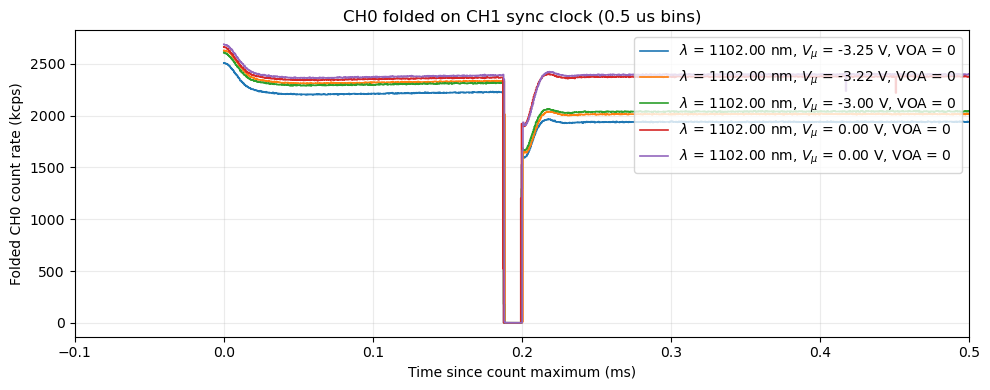

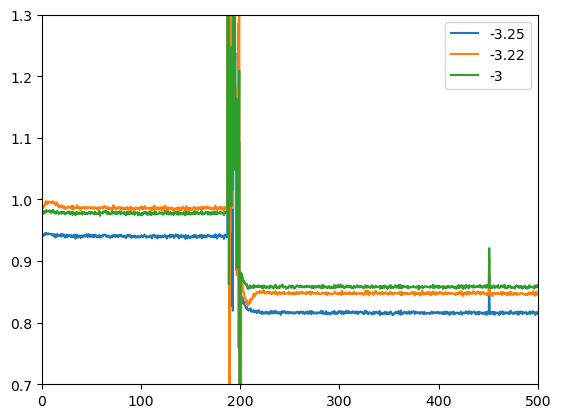

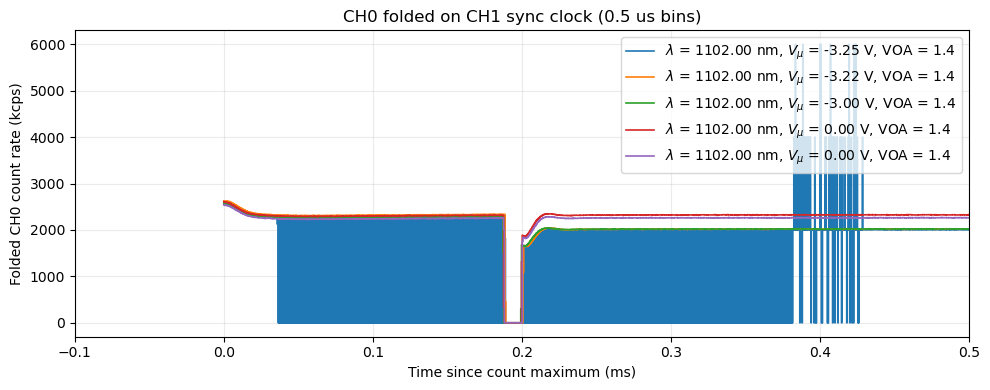

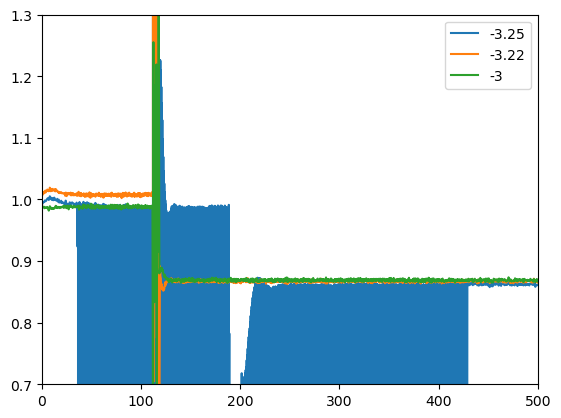

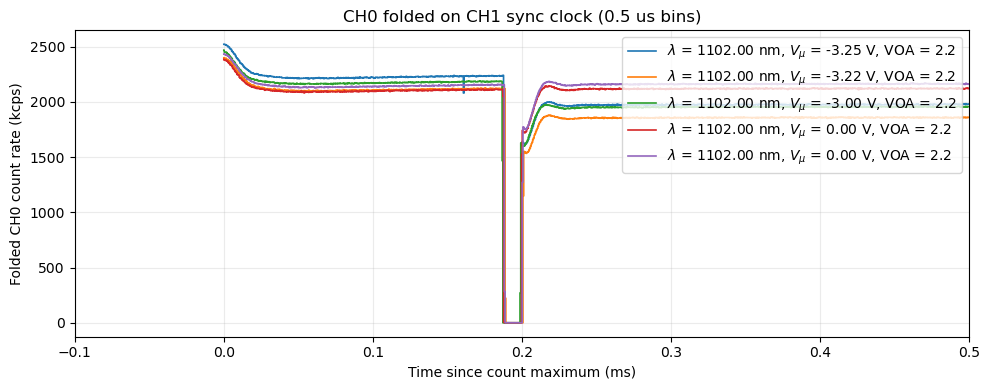

...

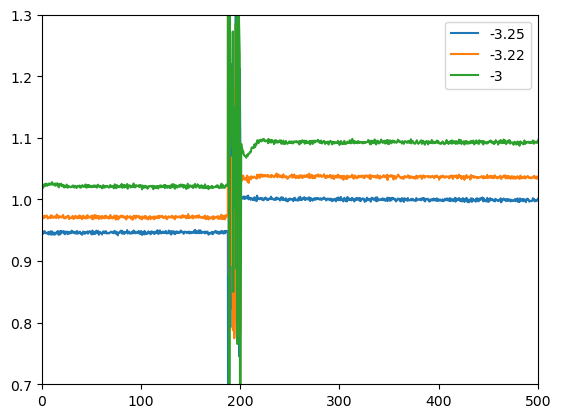

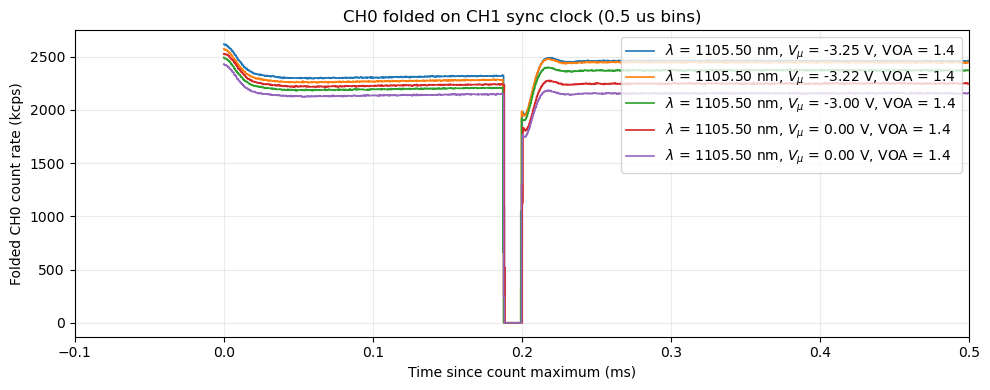

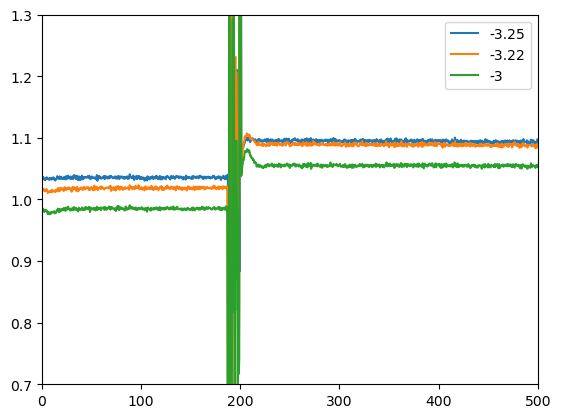

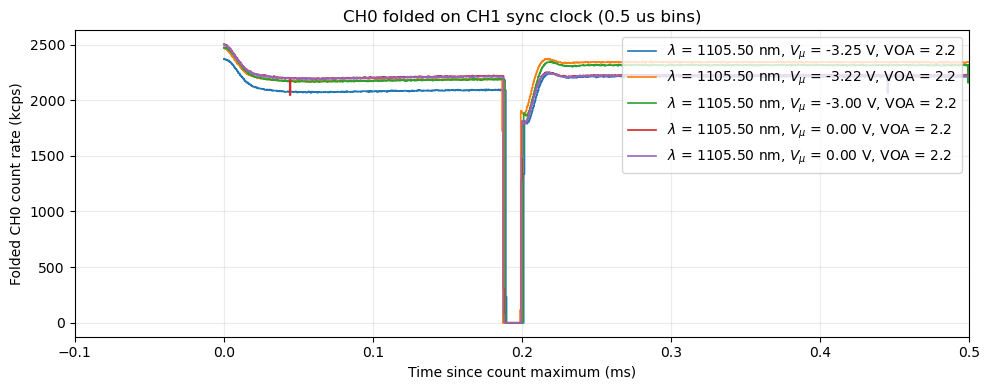

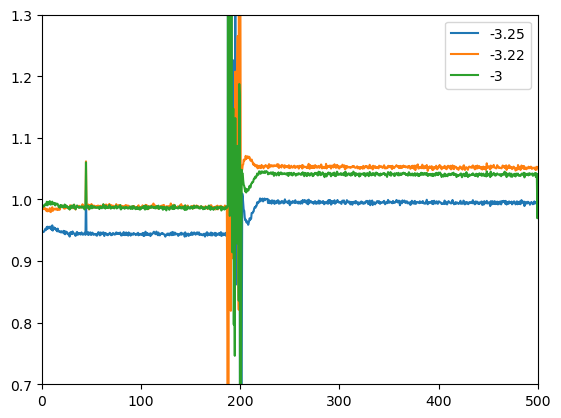

In [ ]:
DATA_ROOT = Path( r"Z:\Labs\G13\SSPDs\MoTe2_PP\20260701_vortex_two_excitation_sample_test3")

for i in range(6):
    acqs = np.arange(1,6)+5*i
    entries = get_metadata_entries(
        acqs,
        keys=["pump wl", "Vmu","voa_requested_initial_voltage" ],
        data_root=DATA_ROOT,
    )

    print("Plotting acqs", acqs)

    fig, ax, traces = plot_sync_traces(
        acqs,
        sync_tick_stride=100,
        bin_us=0.5,
        lims=[-0.1,3],
        ref_range=[0.1,0.15],
        t0_method="argmax",  
        unit="ms",
        data_root=DATA_ROOT,
        y_mode="raw",
        save_fig=False,
        legend_metadata={
        #     "X_LG": "pulse_parameters.amp_x_r1",
        #     # "t_x": {"key": "pulse_parameters.t_x", "unit": "s", "fmt": ".3g"},
        #     # "buffer": {"key": "pulse_parameters.buffer", "unit": "s", "fmt": ".1e"},
        #     # "B":"B_field"
            r"$\lambda$":{"key": "pump wl", "unit": "nm", "fmt": ".2f"},
            r"$V_\mu$" : {"key": "metadata.Vmu", "unit": "V", "fmt": ".2f"},
            "VOA": "metadata.voa_requested_initial_voltage"
        },
    )
    # ax.set_ylim(-0.15,0.04)
    ax.set_xlim(-0.1,.5)
    # plt.close(fig)
    sig1 = traces[0]['counts']+1
    sig2 = traces[1]['counts']+1
    sig3 = traces[2]['counts']+1
    ref = traces[3]['counts']+1
    t = traces[0]['time_us']
    

    plt.figure()
    for i, sig in enumerate([sig1, sig2, sig3]):
        corr = sig[:len(ref)]/ref
        plt.plot(t[:len(ref)],corr, label= entries[i]['Vmu'])
    # plt.plot(t,sig )
    # plt.plot(t,ref )
    plt.ylim(0.7,1.3)
    plt.xlim(0,500)
    plt.legend()


# 3 July: Static LG power dependence

Plotting acqs range(1, 189)


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_1816\2399075722.py:1747: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


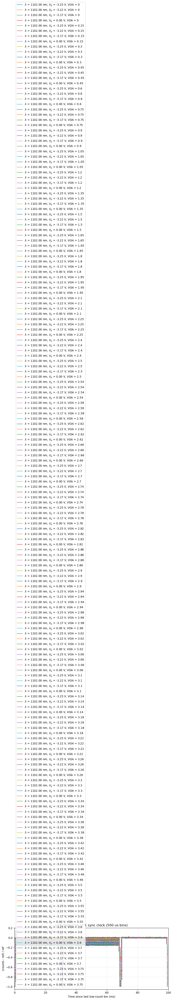

In [73]:


DATA_ROOT = Path( r"Z:\Labs\G13\SSPDs\MoTe2_PP\20260701_vortex_two_excitation_just_LG_power_dependence")


acqs =range(1,189)
entries = get_metadata_entries(
    acqs,
    keys=["pump wl", "Vmu","voa_requested_initial_voltage" ],
    data_root=DATA_ROOT,
)

print("Plotting acqs", acqs)

fig, ax, traces = plot_sync_traces(
    acqs,
    sync_tick_stride=100,
    bin_us=500,
    lims=[-0.1,100],
    ref_range=[80,85],
    t0_method="last_low",  
    unit="ms",
    data_root=DATA_ROOT,
    y_mode="self_normalized",
    save_fig=False,
    legend_metadata={
    #     "X_LG": "pulse_parameters.amp_x_r1",
    #     # "t_x": {"key": "pulse_parameters.t_x", "unit": "s", "fmt": ".3g"},
    #     # "buffer": {"key": "pulse_parameters.buffer", "unit": "s", "fmt": ".1e"},
    #     # "B":"B_field"
        r"$\lambda$":{"key": "pump wl", "unit": "nm", "fmt": ".2f"},
        r"$V_\mu$" : {"key": "metadata.Vmu", "unit": "V", "fmt": ".2f"},
        "VOA": "metadata.voa_requested_initial_voltage"
    },
)
# plt.close(fig)
# ax.set_ylim(-0.15,0.04)
# ax.set_xlim(-0.1,1)
ax.legend(loc='lower left')


(2.8, 3.8)

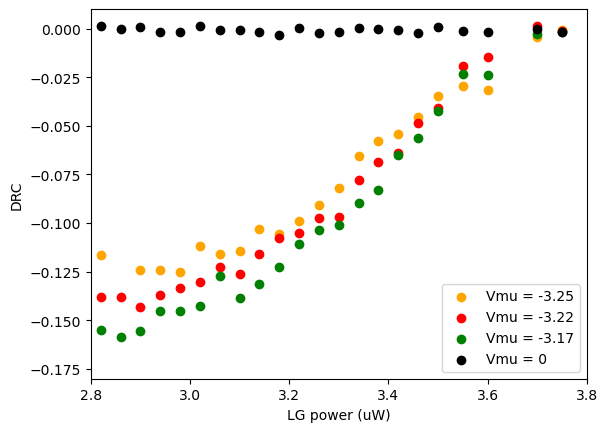

In [ ]:
R0 = [np.mean(trace['plot_y'][(trace['time_us'] > 10e3) & (trace['time_us'] < 60e3)  ]) for trace in traces]
v = [entry["voa_requested_initial_voltage"] for entry in entries]

cols = ['orange','red','green','k']
for i in range(len(acqs)):
    if i // 4 == 0:
        label = "Vmu = "+ str([-3.25,-3.22,-3.17,0][i%4])
        
    else:
        label=None
    c = cols[i%4]
    # plt.scatter(voa_erf_transmission_norm(v[i])*MAX_LG_POWER, R0[i],color = c,label=label)
    plt.scatter(v[i], R0[i],color = c,label=label)

plt.ylabel("DRC")
plt.xlabel("LG power (uW)")
plt.legend()
plt.ylim(-0.18,0.01)
plt.xlim(2.8,3.8)
# plt.scatter(v, R0)

# Characterization of AOMs

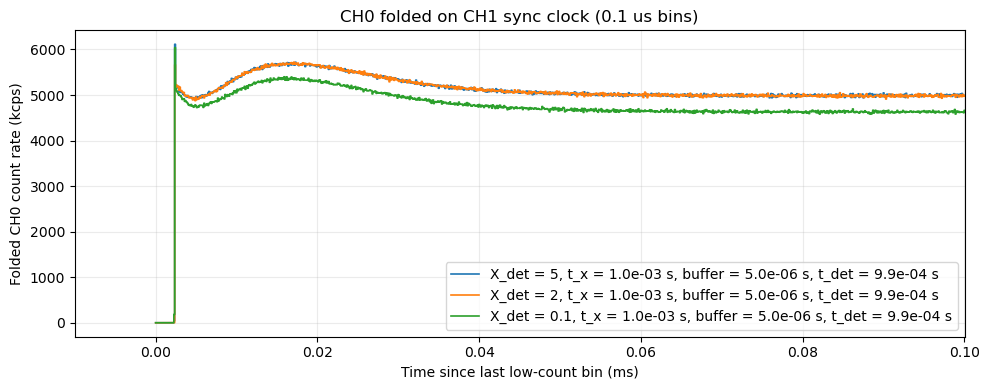

In [ ]:
DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260623_AOM_characterization")

# acqs = matching_acqs_by_parameters(
#     metadata_filters={
#         # "pulse_parameters.t_x": 100e-6,       
#         "pulse_parameters.amp_det_meas" : 2,
#         "pulse_parameters.buffer" : 5e-6# 5e-6     
#     },
#     data_root=DATA_ROOT,
#     require_raw=False,
#     require_analysis=True,
# )
# print("Plotting acqs", acqs)

acqs= [1,3,4]
fig, ax, traces = plot_sync_traces(
    acqs,
    sync_tick_stride=1,
    bin_us=0.1,
    lims=[-0.01,0.1],
    t0_method="last_low",  
    unit="ms",
    data_root=DATA_ROOT,
    y_mode="raw",
    save_fig=True,
    legend_metadata={
        "X_det": "pulse_parameters.amp_det_meas",
        "t_x": {"key": "pulse_parameters.t_x", "unit": "s", "fmt": ".1e"},
        "buffer": {"key": "pulse_parameters.buffer", "unit": "s", "fmt": ".1e"},
        # "B":"B_field"
        "t_det": {"key": "pulse_parameters.t_meas", "unit": "s", "fmt": ".1e"},

        # r"$\lambda = $":{"key": "pump wl", "unit": "nm", "fmt": ".2f"},
        # r"$V_\mu$" : {"key": "metadata.Vmu", "unit": "V", "fmt": ".2f"}
    },)
# ax.set_ylim(-0.05,0.15)
# ax.set_xlim(1,20)
    # fig.savefig(r"Q:\MoTe2_PP_local\20260619_vmu_x_wavelength\Vmu"+f"{vmu:.2f}.png",dpi =300)
ax.legend(loc = 'best')
# fig.set_size_inches(5, 4, forward=True)

# Testing switching back and forth

In [ ]:
DATA_ROOT = Path( r"Q:\MoTe2_PP_local\20260626_switch_back_overnight")
import gc

for i in range(1157,2601):
    try:
        results = analyze_new_timetrace(
            [i],
            data_root=DATA_ROOT,
            desired_count_rate_kcps=None,
            count_rate_bin_s=0.1,
            count_rate_channels=(0, 1),
            sync_tick_stride=1,
            raw_bin_us=1,
            raw_lims=[0, 100],
            normalized_bin_us=100,
            normalized_lims=[0.0,100],
            ref_range=[20,30],
            t0_method="last_low",  
            unit="ms",
            use_previous_reference=False,
            force_recompute_count_rate=False,
            force_recompute_fold=False,
        )
        print(f"Analysis of acq_{i} successful.")
    except Exception as exc:
        print(f"Analysis of acq_{i} failed: {exc}")
    finally:
        plt.close("all")
        if "results" in locals():
            del results
        gc.collect()


Analysis of acq_1157 successful.
Analysis of acq_1158 successful.
Analysis of acq_1159 successful.
Analysis of acq_1160 successful.
Analysis of acq_1161 successful.
Analysis of acq_1162 successful.
Analysis of acq_1163 successful.
Analysis of acq_1164 successful.
Analysis of acq_1165 successful.
Analysis of acq_1166 successful.
Analysis of acq_1167 successful.
Analysis of acq_1168 successful.
Analysis of acq_1169 successful.
Analysis of acq_1170 successful.
Analysis of acq_1171 successful.
Analysis of acq_1172 successful.
Analysis of acq_1173 successful.
Analysis of acq_1174 successful.
Analysis of acq_1175 successful.
Analysis of acq_1176 successful.
Analysis of acq_1177 successful.
Analysis of acq_1178 successful.
Analysis of acq_1179 successful.
Analysis of acq_1180 successful.
Analysis of acq_1181 successful.
Analysis of acq_1182 successful.
Analysis of acq_1183 successful.
Analysis of acq_1184 successful.
Analysis of acq_1185 successful.
Analysis of acq_1186 successful.
Analysis o

KeyboardInterrupt: 

Plotting acqs [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55]


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_7828\3312010598.py:1607: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


Plotting acqs [56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110]
Plotting acqs [111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156]
Plotting acqs [157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211]
Plotting acqs [212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252,

C:\Users\SSPDs\AppData\Local\Temp\ipykernel_7828\3312010598.py:1504: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=(10, 4))


Plotting acqs [597, 598, 599, 600, 601, 602, 603, 604, 605, 606, 607, 608, 609, 610, 611, 612, 613, 614, 615, 616, 617, 618, 619, 620, 621, 622, 623, 624, 625, 626, 627, 628, 629, 630, 631, 632, 633, 634, 635, 636, 637, 638, 639, 640, 641, 642, 643, 644, 645, 646, 647, 648, 649, 650, 651]
Plotting acqs [652, 653, 654, 655, 656, 657, 658, 659, 660, 661, 662, 663, 664, 665, 666, 667, 668, 669, 670, 671, 672, 673, 674, 675, 676, 677, 678, 679, 680, 681, 682, 683, 684, 685, 686, 687, 688, 689, 690, 691, 692, 693, 694, 695, 696, 697, 698, 699, 700, 701, 702, 703, 704, 705, 706]
Plotting acqs [707, 708, 709, 710, 711, 712, 713, 714, 715, 716, 717, 718, 719, 720, 721, 722, 723, 724, 725, 726, 727, 728, 729, 730, 731, 732, 733, 734, 735, 736, 737, 738, 739, 740, 741, 742, 743, 744, 745, 746, 747, 748, 749, 750, 751, 752, 753, 754, 755, 756, 757, 758, 759, 760, 761]


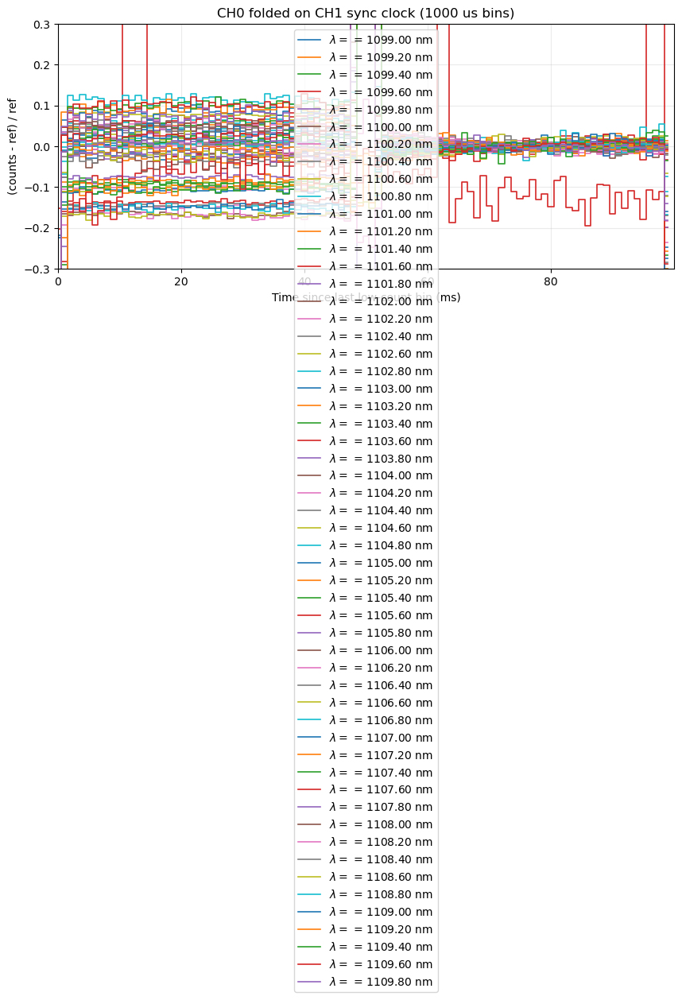

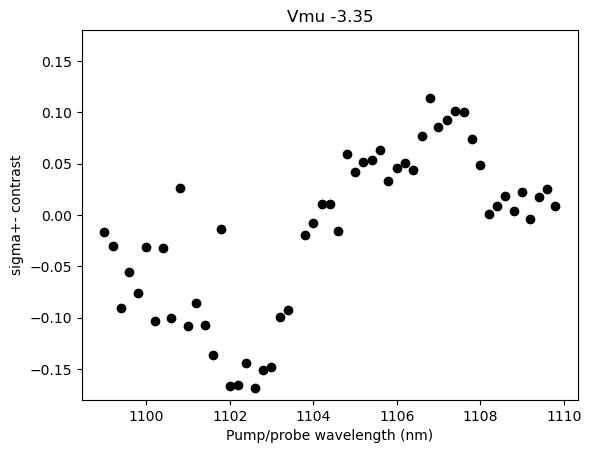

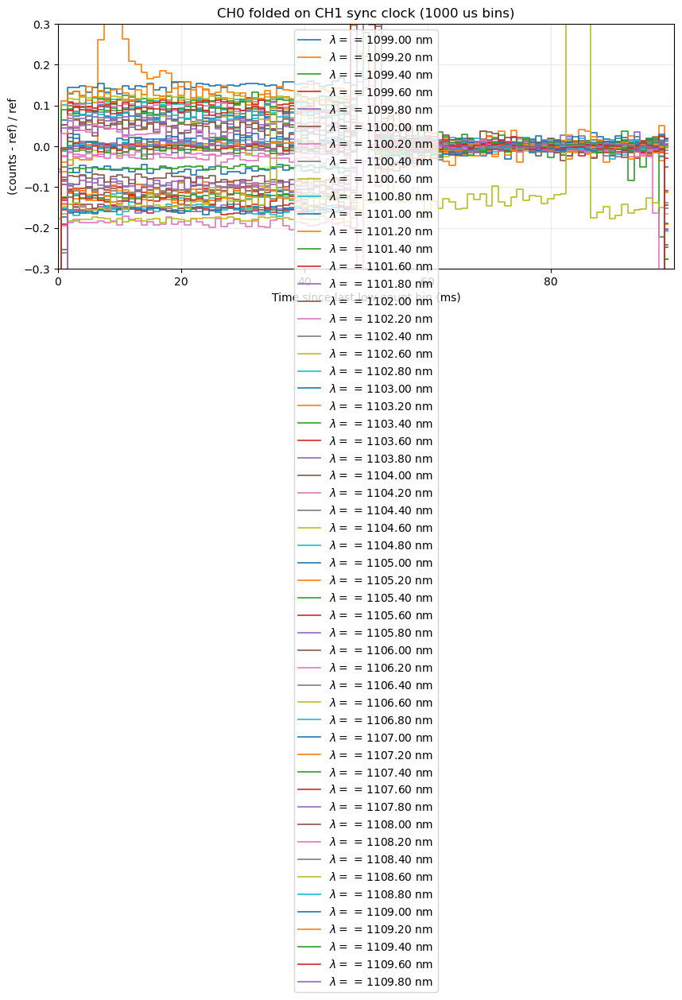

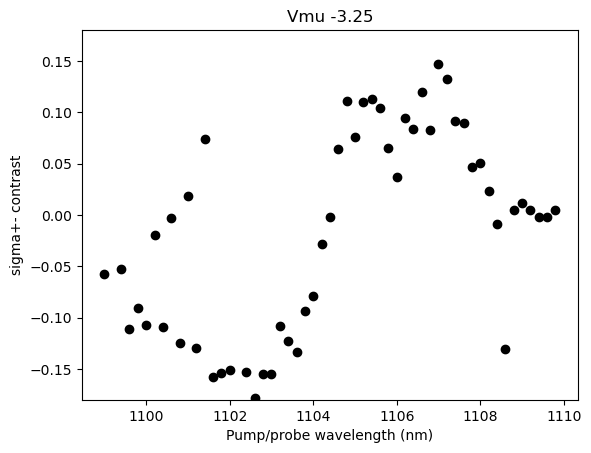

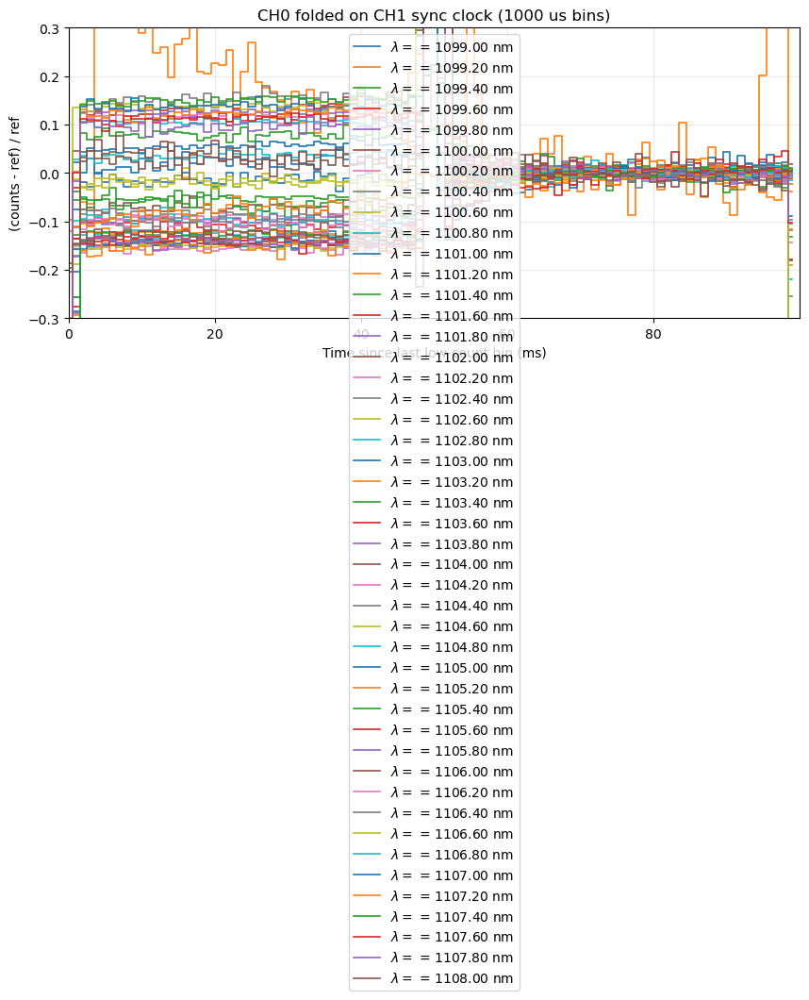

...

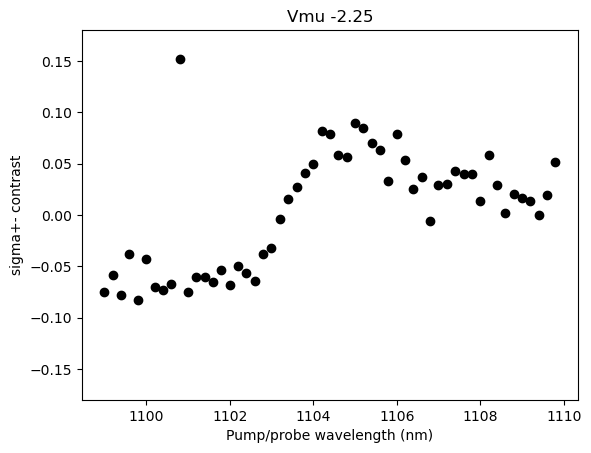

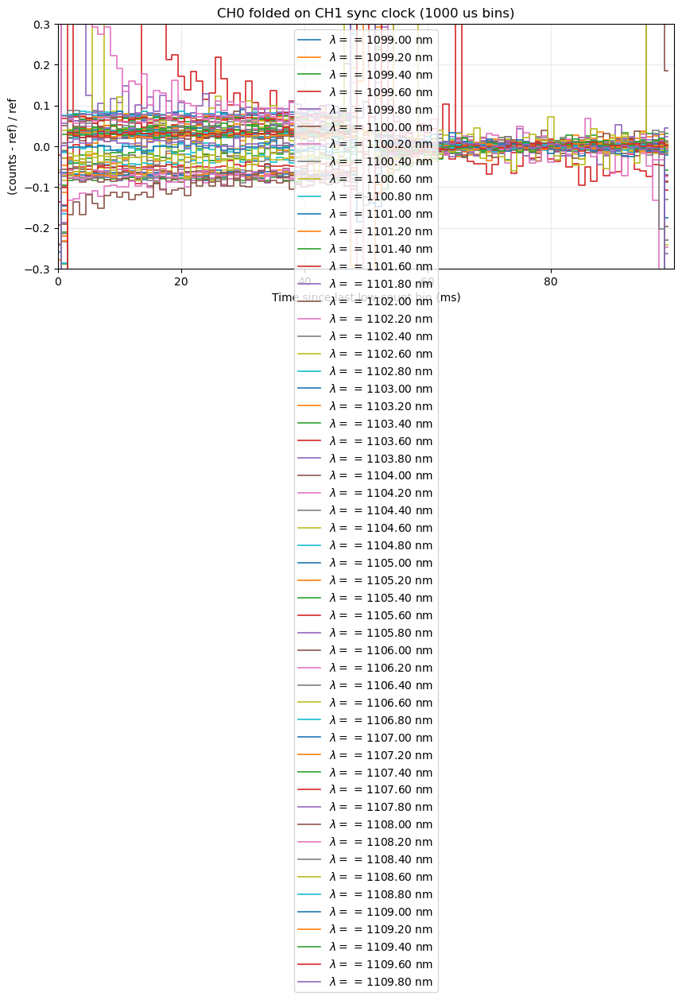

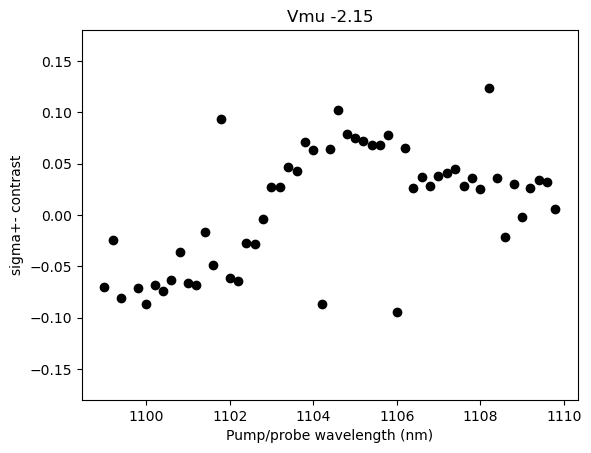

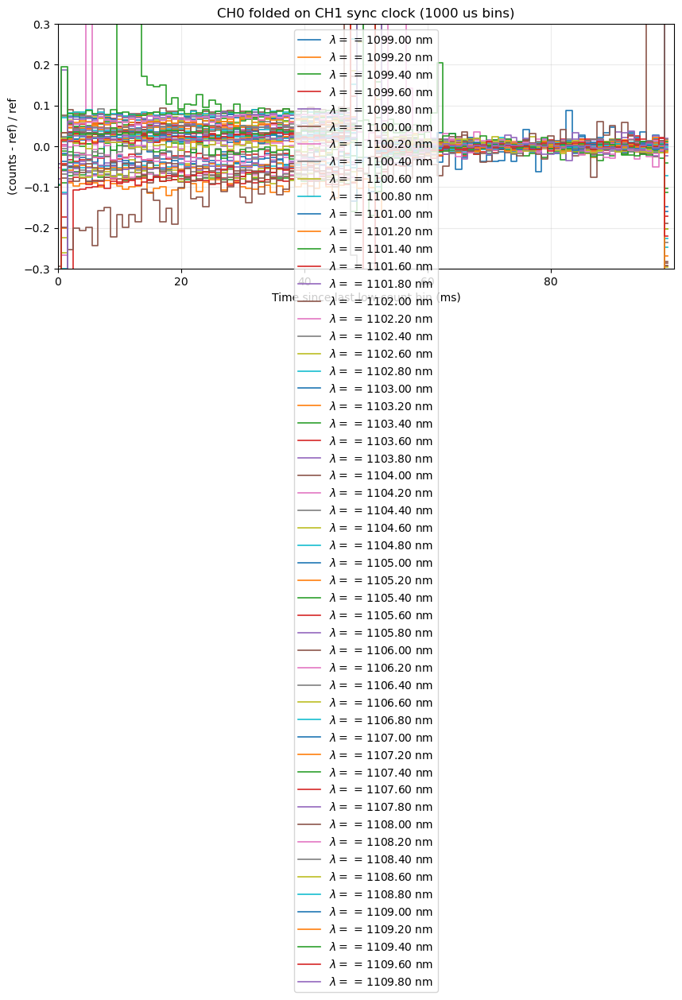

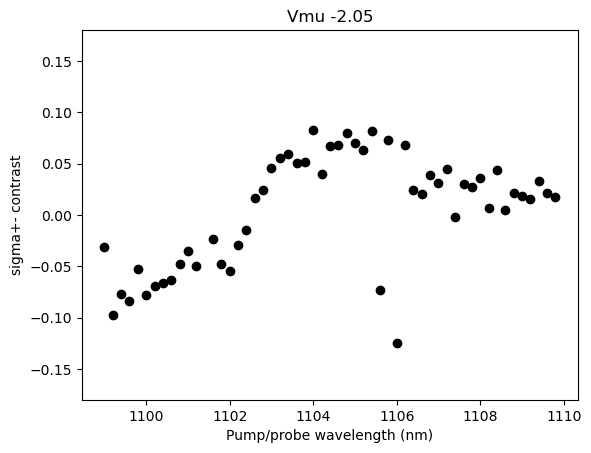

In [ ]:

DATA_ROOT = Path( r"Q:\MoTe2_PP_local\20260626_switch_back_overnight")
for vmu in np.arange(-3.35,-1.99,0.1):
    acqs = matching_acqs_by_parameters(
        metadata_filters={
            # "pulse_parameters.t_x": 100e-6,       
            # "pulse_parameters.amp_det_meas" : 2,
            # "pulse_parameters.buffer" : 5e-6# 5e-6     
            "Vmu":vmu
        },
        data_root=DATA_ROOT,
        require_raw=False,
        require_analysis=True,
    )
    print("Plotting acqs", acqs)


    all_contrasts = []
    # for i in range(len(all_vmus)):
    # acqs= range(1,38)
    fig, ax, traces = plot_sync_traces(
        acqs,
        sync_tick_stride=100,
        bin_us=1000,
        # lims=[-1,100],
        t0_method="last_low",  
        unit="ms",
        data_root=DATA_ROOT,
        y_mode="self_normalized",
        ref_range=[60,95],
        save_fig=True,
        # force_recompute=True,
        legend_metadata={
            # "X_det": "pulse_parameters.amp_det_meas",
            # "t_x": {"key": "pulse_parameters.t_x", "unit": "s", "fmt": ".1e"},
            # "buffer": {"key": "pulse_parameters.buffer", "unit": "s", "fmt": ".1e"},
            # "B":"B_field"
            # "t_det": {"key": "pulse_parameters.t_meas", "unit": "s", "fmt": ".1e"},

            r"$\lambda = $":{"key": "pump wl", "unit": "nm", "fmt": ".2f"},
            # r"$V_\mu$" : {"key": "metadata.Vmu", "unit": "V", "fmt": ".2f"}
        },)

    # ax.set_xlim(1,20)
        # fig.savefig(r"Q:\MoTe2_PP_local\20260619_vmu_x_wavelength\Vmu"+f"{vmu:.2f}.png",dpi =300)
    ax.legend(loc = 'best')
    ax.set_ylim(-0.3,0.3)

    plt.figure()
    wls = np.arange(1099,1110,0.2)
    for i in range(len(traces)):
        t = traces[i]['time_us']
        y = traces[i]['plot_y']
        y0 = np.mean(y[(t>5e3) & (t<40e3)])
        plt.scatter(wls[i],y0,color = 'k')
    plt.ylim(-.18,.18)
    plt.title(f"Vmu {vmu:.2f}")
    plt.xlabel("Pump/probe wavelength (nm)")
    plt.ylabel("sigma+- contrast")
    plt.savefig(r"Q:\MoTe2_PP_local\20260626_switch_back_overnight\contrast_Vmu_"+f"{vmu:.2f}.png",dpi=300)

Text(0.5, 1.0, 'Vmu -3.15')

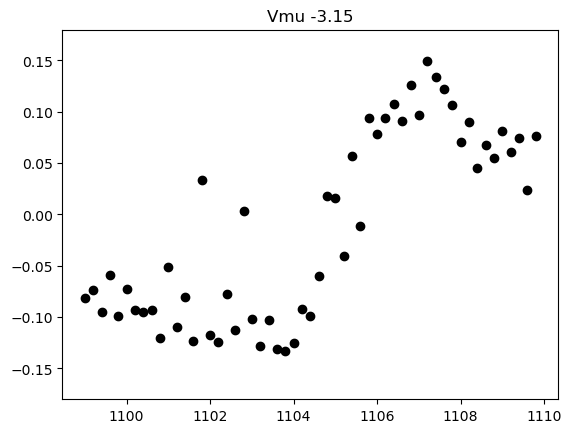

In [ ]:
wls = np.arange(1099,1110,0.2)
for i in range(len(traces)):
    t = traces[i]['time_us']
    y = traces[i]['plot_y']
    y0 = np.mean(y[(t>5e3) & (t<40e3)])
    plt.scatter(wls[i],y0,color = 'k')
plt.ylim(-.18,.18)
plt.title(f"Vmu {vmu:.2f}")
plt.xlabel("Pump/probe wavelength (nm)")
plt.ylabel("sigma+- contrast")
plt.savefig(DATA_ROOT + r"\contrast_Vmu_"+f"{vmu:.2f}")

C:\Users\SSPDs\AppData\Local\Temp\ipykernel_13808\3312010598.py:1607: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


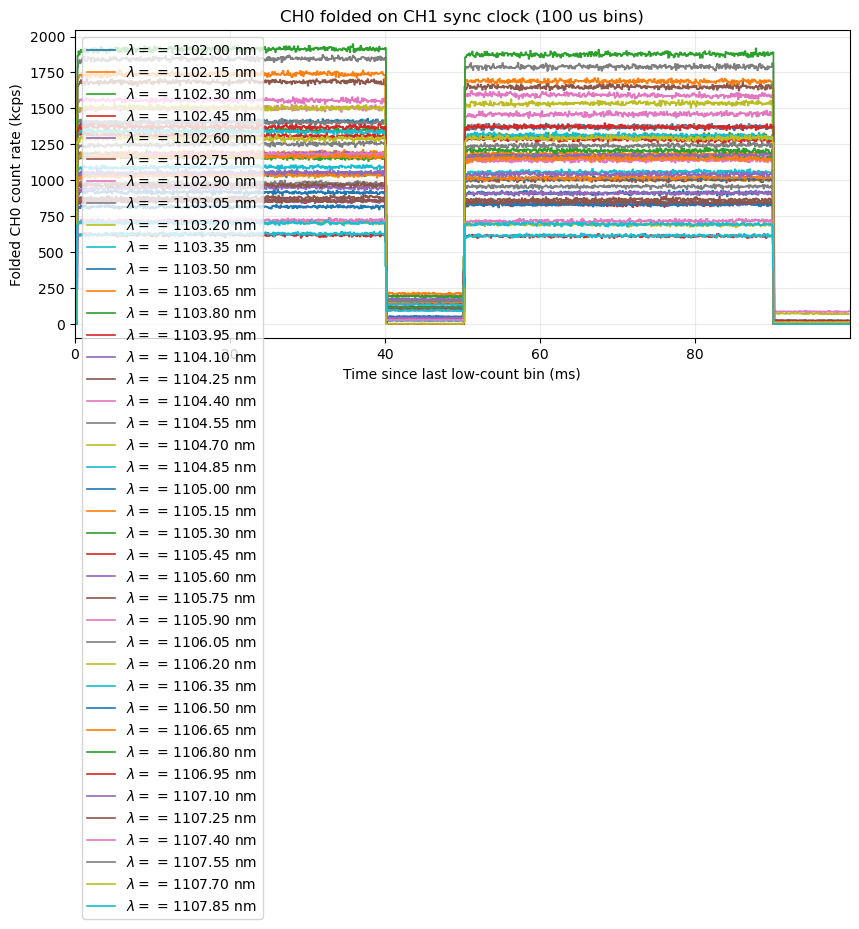

In [ ]:
DATA_ROOT = Path( r"Q:\MoTe2_PP_local\20260625_switch_back_vmu x wavelength")

# acqs = matching_acqs_by_parameters(
#     metadata_filters={
#         # "pulse_parameters.t_x": 100e-6,       
#         "pulse_parameters.amp_det_meas" : 2,
#         "pulse_parameters.buffer" : 5e-6# 5e-6     
#     },
#     data_root=DATA_ROOT,
#     require_raw=False,
#     require_analysis=True,
# )
# print("Plotting acqs", acqs)


all_contrasts = []
all_vmus = np.arange(-3.3,-2,0.02)[:1]
for i in range(len(all_vmus)):
    acqs= np.arange(1,41) + 40*i#2601
    fig, ax, traces = plot_sync_traces(
        acqs,
        sync_tick_stride=1,
        bin_us=100,
        # lims=[-1,100],
        t0_method="last_low",  
        unit="ms",
        data_root=DATA_ROOT,
        y_mode="raw",
        ref_range=[20,30],
        save_fig=True,
        legend_metadata={
            # "X_det": "pulse_parameters.amp_det_meas",
            # "t_x": {"key": "pulse_parameters.t_x", "unit": "s", "fmt": ".1e"},
            # "buffer": {"key": "pulse_parameters.buffer", "unit": "s", "fmt": ".1e"},
            # "B":"B_field"
            # "t_det": {"key": "pulse_parameters.t_meas", "unit": "s", "fmt": ".1e"},

            r"$\lambda = $":{"key": "pump wl", "unit": "nm", "fmt": ".2f"},
            # r"$V_\mu$" : {"key": "metadata.Vmu", "unit": "V", "fmt": ".2f"}
        },)
    # ax.set_ylim(-0.05,0.15)
    # ax.set_xlim(1,20)
        # fig.savefig(r"Q:\MoTe2_PP_local\20260619_vmu_x_wavelength\Vmu"+f"{vmu:.2f}.png",dpi =300)
    ax.legend(loc = 'best')
    # ax.set_ylim(-0.04,0.04)
    # fig.close()
    contrasts = [] 
    for j in range(len(traces)):
        t = traces[j]['time_us']
        ref = np.mean(traces[j]['plot_y'][(t<37e3)& (t> 10e3)])
        other = np.mean(traces[j]['plot_y'][(t>60e3)& (t< 80e3)])
        contrasts.append((ref-other)/ref)

    all_contrasts.append(contrasts)


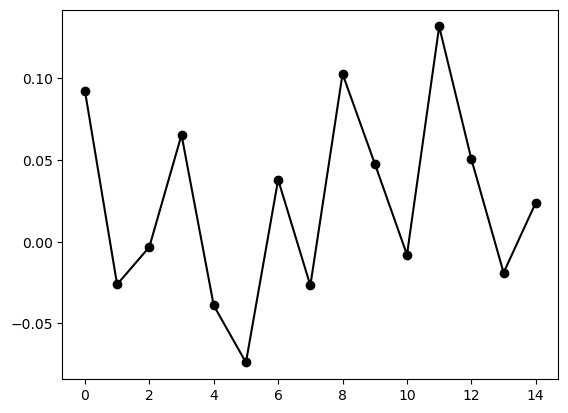

In [ ]:
for i in range(len(all_vmus)):
    plt.plot(range(len(traces)), (all_contrasts[i]),"-o",color = [0,0,i/len(all_vmus)])

In [ ]:
50/2000

0.025

# other

Scanning JSON files in Q:\MoTe2_PP_local\20260703_vortex_two_excitation_test4...
Done! Cleaned summary written to: Q:\MoTe2_PP_local\20260703_vortex_two_excitation_test4\swept_parameters_summary.txt


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_12240\3000149056.py:191: RuntimeWarning: divide by zero encountered in divide
  corr = sample_ratio[:min_len] / reference_ratio[:min_len]
C:\Users\SSPDs\AppData\Local\Temp\ipykernel_12240\3000149056.py:191: RuntimeWarning: invalid value encountered in divide
  corr = sample_ratio[:min_len] / reference_ratio[:min_len]


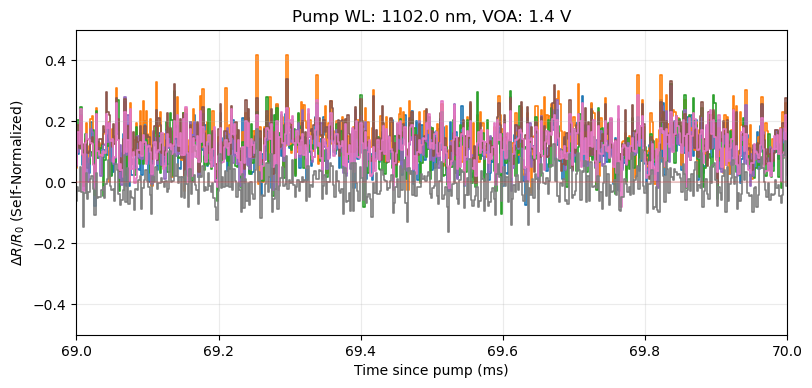

In [ ]:
DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260703_vortex_two_excitation_test4")
summarize_swept_parameters(DATA_ROOT)

wls = np.array([1102.0])
VOAs = np.array([1.4])

for wls_val in wls:
    for voa_val in VOAs:
        fig, ax = plot_vmu_contrast_with_0V_ref(
            pump_wl=wls_val,
            voa_voltage=voa_val,
            t_x_r1=0.001,
            data_root=DATA_ROOT,
            sync_tick_stride=100,
            bin_us=0.5,
            ref_range=[0.1,0.15],
            unit="ms",
            t0_method="last_low",
            plot_baseline=True,
            with_legend=False,
        )
        plt.xlim(69,70)
        plt.ylim(-0.5,0.5)
        plt.title(f"Pump WL: {wls_val} nm, VOA: {voa_val} V")
        #plt.savefig(r"Q:\MoTe2_PP_local\20260703_vortex_two_excitation_test4\Contrast_WL_%.1fnm_VOA_%.1fV.png"%(wls_val,voa_val), dpi=600, bbox_inches='tight')
        plt.show()

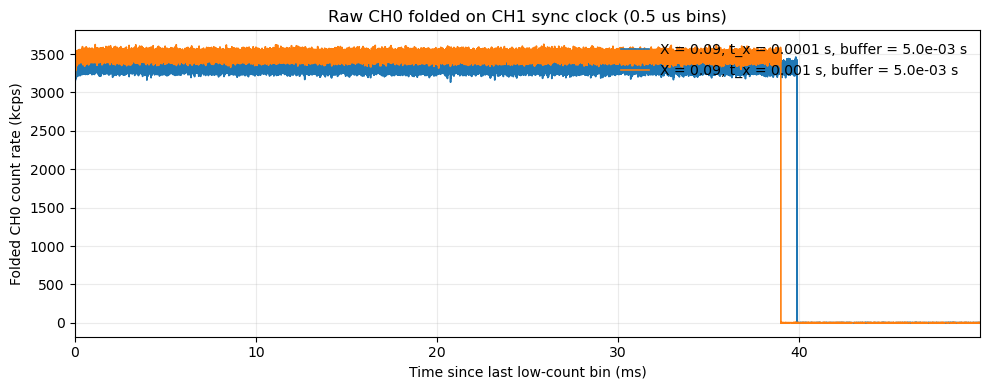

In [ ]:
DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260613_test3")

fig, ax, traces = plot_raw_sync_traces(
    [1,8],
    sync_tick_stride=1,
    bin_us=0.5,
    # lims=[-0.1,0.1],
    t0_method="last_low",
    unit="ms",
    data_root=DATA_ROOT,
    legend_metadata={
        "X": "pulse_parameters.amp_x",
        "t_x": {"key": "pulse_parameters.t_x", "unit": "s", "fmt": ".3g"},
        "buffer": {"key": "pulse_parameters.buffer", "unit": "s", "fmt": ".1e"},
    },
)


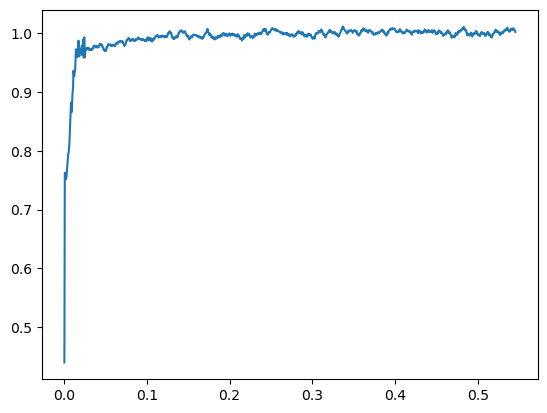

In [ ]:
ref_dat = np.load(r'Q:\MoTe2_PP_local\reference_response.npz')
response_ref = lambda t_ms: np.interp(t_ms, ref_dat['x_ms'], ref_dat['norm_refsig'])
plt.plot(ref_dat['x_ms'], ref_dat['norm_refsig'])

(0.7, 2.0)

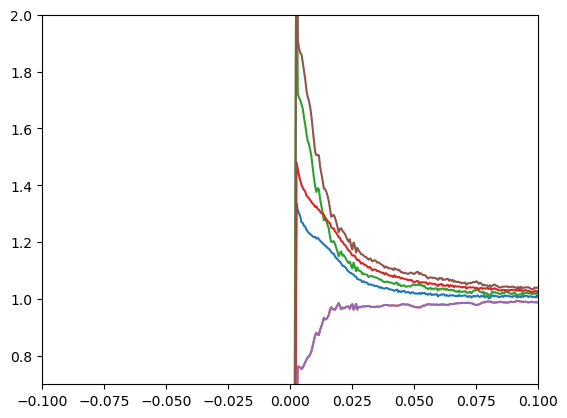

In [ ]:

for i in [0,1]:#range(len(traces)):
    t_dat = traces[i]["time_us"]*1e-3

    s_dat = traces[i]["rate_kcps"]
    plt.plot(t_dat, s_dat/np.mean(s_dat[(t_dat>1)&(t_dat<2)]))
    plt.plot(t_dat, response_ref(t_dat-2.3e-3))
    plt.plot(t_dat, s_dat/np.mean(s_dat[(t_dat>1)&(t_dat<2)])/response_ref(t_dat-2.3e-3))

plt.xlim(-0.1,0.1)
plt.ylim(0.7,2)



# Saving a reference signal

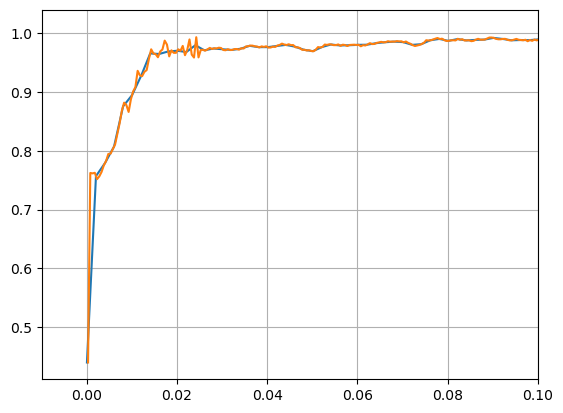

In [ ]:
counts = traces[0]["counts"][:50_000]
smooth_1 = ma(counts[:50], 1 )
smooth_2 = ma(counts[50:1100], 10)
x1 = traces[0]["time_us"][:50][:len(smooth_1)] / 1e3
x2 = traces[0]["time_us"][50:1100][:len(smooth_2)] / 1e3
norm_ref = np.mean(counts[45_000:50_000])

x_ms = np.concatenate((x1,x2))
y = np.concatenate((smooth_1 , smooth_2)) / norm_ref

response_ref = lambda t_ms: np.interp(t_ms, x_ms, y)

t_ms = np.linspace(0, 1,500)
response_ref(t_ms)
plt.plot(t_ms, response_ref(t_ms))
plt.plot(x_ms, y)

plt.xlim(-0.01,0.1)
plt.grid()
# traces[0]['time_us'][:50_000]

# x_ms

In [ ]:
ref_dat = np.load(r'Q:\MoTe2_PP_local\reference_response.npz')
response_ref = lambda t_ms: np.interp(t_ms, ref_dat['x_ms'], ref_dat['norm_refsig'])


# 1 July: Re-analyzing magnetic field and Vmu dependence

## Reading in reference measurements

### B_stabilized and B_stabilized2

Saved Q:\MoTe2_PP_local\20260701_RefMeas\acq_9_self_normalized_trace.npz


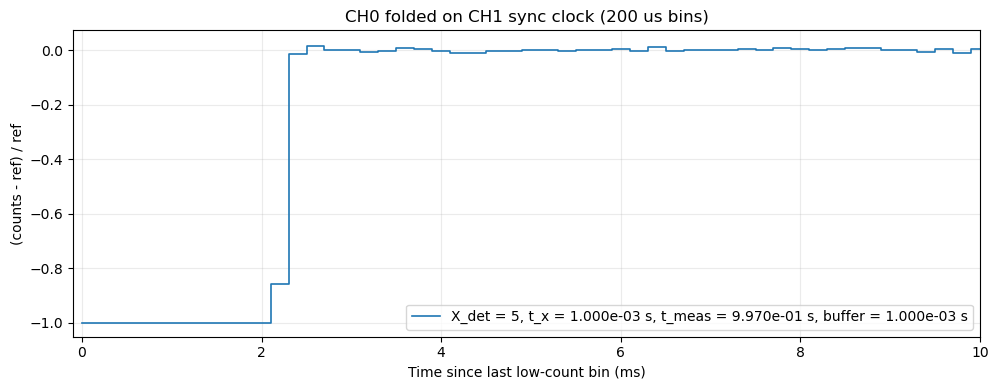

In [ ]:

DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260701_RefMeas")
   
acq_index = 9
fig, ax, traces = plot_sync_traces(
    [acq_index],
    sync_tick_stride=10,
    bin_us=200,
    t0_method="last_low",  
    unit="ms",
    data_root=DATA_ROOT,
    y_mode="self_normalized",
    ref_range=[900,920],
    save_fig=True,
    legend_metadata={
        "X_det": "pulse_parameters.amp_det_meas",
        "t_x": {"key": "pulse_parameters.t_x", "unit": "s", "fmt": ".3e"},
        "t_meas": {"key": "pulse_parameters.t_meas", "unit": "s", "fmt": ".3e"},
        "buffer": {"key": "pulse_parameters.buffer", "unit": "s", "fmt": ".3e"},
        # "B":"B_field"
        # "t_det": {"key": "pulse_parameters.t_meas", "unit": "s", "fmt": ".1e"},
        # r"$\lambda = $":{"key": "pump wl", "unit": "nm", "fmt": ".2f"},
        # r"$V_\mu$" : {"key": "metadata.Vmu", "unit": "V", "fmt": ".2f"}
    },)
ax.legend(loc = 'best')
# ax.set_ylim(-0.3,0.3)
ax.set_xlim(-0.1,10)




time_ms = traces[0]["time_us"] / 1e3
plot_y = traces[0]["plot_y"]

out_path = DATA_ROOT / f"acq_{acq_index}_self_normalized_trace.npz"
np.savez_compressed(
    out_path,
    acq_index=acq_index,
    time_ms=time_ms,
    plot_y=plot_y,
)
print(f"Saved {out_path}")

### VMU scans

Saved Q:\MoTe2_PP_local\20260701_RefMeas\acq_8_self_normalized_trace.npz


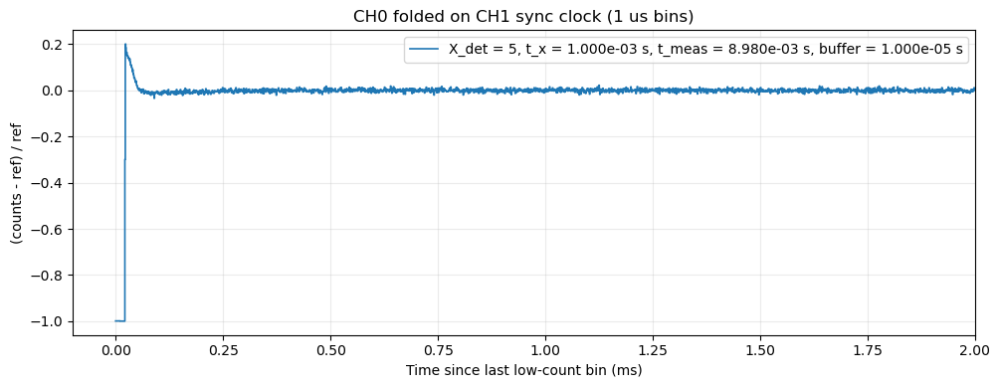

In [ ]:

DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260701_RefMeas")
   
acq_index = 8
fig, ax, traces = plot_sync_traces(
    [acq_index],
    sync_tick_stride=10,
    bin_us=1,
    t0_method="last_low",  
    unit="ms",
    data_root=DATA_ROOT,
    y_mode="self_normalized",
    ref_range=[8,8.1],
    save_fig=True,
    legend_metadata={
        "X_det": "pulse_parameters.amp_det_meas",
        "t_x": {"key": "pulse_parameters.t_x", "unit": "s", "fmt": ".3e"},
        "t_meas": {"key": "pulse_parameters.t_meas", "unit": "s", "fmt": ".3e"},
        "buffer": {"key": "pulse_parameters.buffer", "unit": "s", "fmt": ".3e"},
        # "B":"B_field"
        # "t_det": {"key": "pulse_parameters.t_meas", "unit": "s", "fmt": ".1e"},
        # r"$\lambda = $":{"key": "pump wl", "unit": "nm", "fmt": ".2f"},
        # r"$V_\mu$" : {"key": "metadata.Vmu", "unit": "V", "fmt": ".2f"}
    },)
ax.legend(loc = 'best')
# ax.set_ylim(-0.3,0.3)
ax.set_xlim(-0.1,2)




time_ms = traces[0]["time_us"] / 1e3
plot_y = traces[0]["plot_y"]

out_path = DATA_ROOT / f"acq_{acq_index}_self_normalized_trace.npz"
np.savez_compressed(
    out_path,
    acq_index=acq_index,
    time_ms=time_ms,
    plot_y=plot_y,
)
print(f"Saved {out_path}")

### Vmu x wavelength attempt

Saved Q:\MoTe2_PP_local\20260701_RefMeas\acq_12_self_normalized_trace.npz


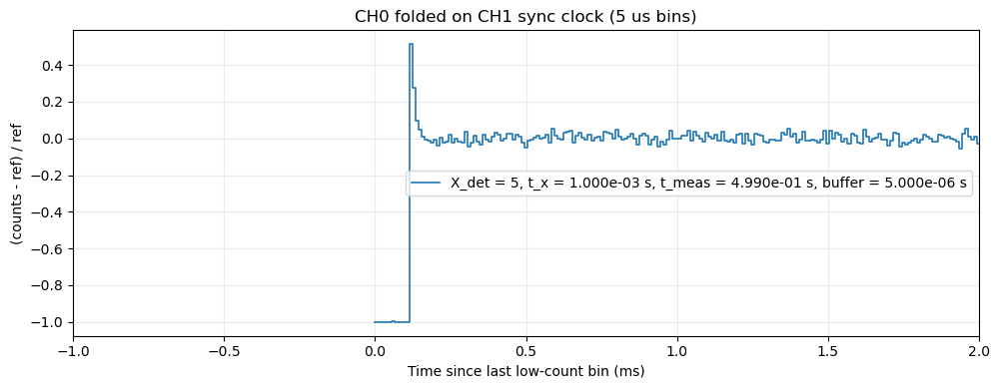

In [ ]:

DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260701_RefMeas")
   
acq_index = 12
fig, ax, traces = plot_sync_traces(
    [acq_index],
    sync_tick_stride=10,
    bin_us=5,
    t0_method="last_low",  
    unit="ms",
    data_root=DATA_ROOT,
    y_mode="self_normalized",
    ref_range=[400,450],
    save_fig=True,
    legend_metadata={
        "X_det": "pulse_parameters.amp_det_meas",
        "t_x": {"key": "pulse_parameters.t_x", "unit": "s", "fmt": ".3e"},
        "t_meas": {"key": "pulse_parameters.t_meas", "unit": "s", "fmt": ".3e"},
        "buffer": {"key": "pulse_parameters.buffer", "unit": "s", "fmt": ".3e"},
        # "B":"B_field"
        # "t_det": {"key": "pulse_parameters.t_meas", "unit": "s", "fmt": ".1e"},
        # r"$\lambda = $":{"key": "pump wl", "unit": "nm", "fmt": ".2f"},
        # r"$V_\mu$" : {"key": "metadata.Vmu", "unit": "V", "fmt": ".2f"}
    },)
ax.legend(loc = 'best')
# ax.set_ylim(-0.3,0.3)
ax.set_xlim(-1,2)




time_ms = traces[0]["time_us"] / 1e3
plot_y = traces[0]["plot_y"]

out_path = DATA_ROOT / f"acq_{acq_index}_self_normalized_trace.npz"
np.savez_compressed(
    out_path,
    acq_index=acq_index,
    time_ms=time_ms,
    plot_y=plot_y,
)
print(f"Saved {out_path}")

### B stab. 3 acq 1-10

Saved Q:\MoTe2_PP_local\20260701_RefMeas\acq_10_self_normalized_trace.npz


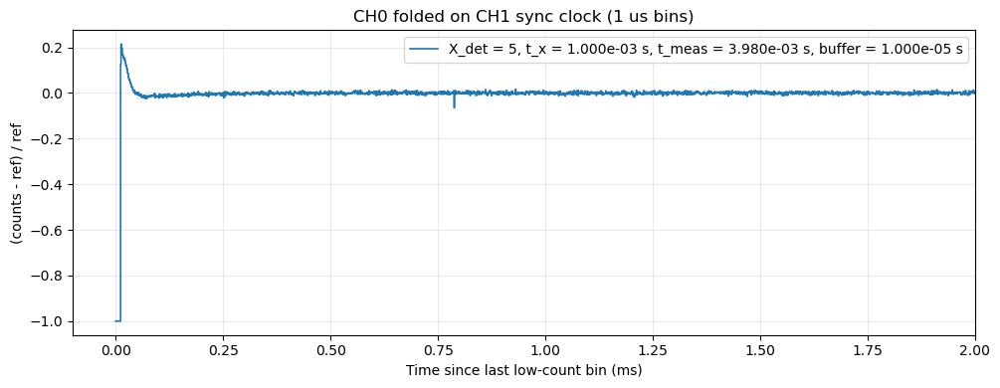

In [ ]:

DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260701_RefMeas")
   
acq_index = 10
fig, ax, traces = plot_sync_traces(
    [acq_index],
    sync_tick_stride=10,
    bin_us=1,
    t0_method="last_low",  
    unit="ms",
    data_root=DATA_ROOT,
    y_mode="self_normalized",
    ref_range=[3,3.5],
    save_fig=True,
    legend_metadata={
        "X_det": "pulse_parameters.amp_det_meas",
        "t_x": {"key": "pulse_parameters.t_x", "unit": "s", "fmt": ".3e"},
        "t_meas": {"key": "pulse_parameters.t_meas", "unit": "s", "fmt": ".3e"},
        "buffer": {"key": "pulse_parameters.buffer", "unit": "s", "fmt": ".3e"},
        # "B":"B_field"
        # "t_det": {"key": "pulse_parameters.t_meas", "unit": "s", "fmt": ".1e"},
        # r"$\lambda = $":{"key": "pump wl", "unit": "nm", "fmt": ".2f"},
        # r"$V_\mu$" : {"key": "metadata.Vmu", "unit": "V", "fmt": ".2f"}
    },)
ax.legend(loc = 'best')
# ax.set_ylim(-0.3,0.3)
ax.set_xlim(-0.1,2)




time_ms = traces[0]["time_us"] / 1e3
plot_y = traces[0]["plot_y"]

out_path = DATA_ROOT / f"acq_{acq_index}_self_normalized_trace.npz"
np.savez_compressed(
    out_path,
    acq_index=acq_index,
    time_ms=time_ms,
    plot_y=plot_y,
)
print(f"Saved {out_path}")

### B stab. acq. 11-17

Saved Q:\MoTe2_PP_local\20260701_RefMeas\acq_11_self_normalized_trace.npz


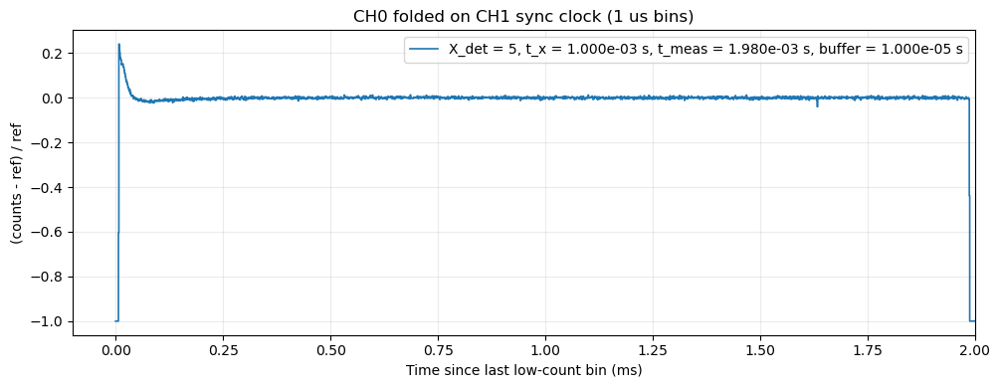

In [ ]:

DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260701_RefMeas")
   
acq_index = 11
fig, ax, traces = plot_sync_traces(
    [acq_index],
    sync_tick_stride=10,
    bin_us=1,
    t0_method="last_low",  
    unit="ms",
    data_root=DATA_ROOT,
    y_mode="self_normalized",
    ref_range=[1,1.1],
    save_fig=True,
    legend_metadata={
        "X_det": "pulse_parameters.amp_det_meas",
        "t_x": {"key": "pulse_parameters.t_x", "unit": "s", "fmt": ".3e"},
        "t_meas": {"key": "pulse_parameters.t_meas", "unit": "s", "fmt": ".3e"},
        "buffer": {"key": "pulse_parameters.buffer", "unit": "s", "fmt": ".3e"},
        # "B":"B_field"
        # "t_det": {"key": "pulse_parameters.t_meas", "unit": "s", "fmt": ".1e"},
        # r"$\lambda = $":{"key": "pump wl", "unit": "nm", "fmt": ".2f"},
        # r"$V_\mu$" : {"key": "metadata.Vmu", "unit": "V", "fmt": ".2f"}
    },)
ax.legend(loc = 'best')
# ax.set_ylim(-0.3,0.3)
ax.set_xlim(-0.1,2)




time_ms = traces[0]["time_us"] / 1e3
plot_y = traces[0]["plot_y"]

out_path = DATA_ROOT / f"acq_{acq_index}_self_normalized_trace.npz"
np.savez_compressed(
    out_path,
    acq_index=acq_index,
    time_ms=time_ms,
    plot_y=plot_y,
)
print(f"Saved {out_path}")

## Reading in and correcting the original magnetic field and Vmu data

### B stab 1 & 2

... are virtually unaffected by AOM artifacts because the time scales are so long

### B stab 3 acqs 1-10

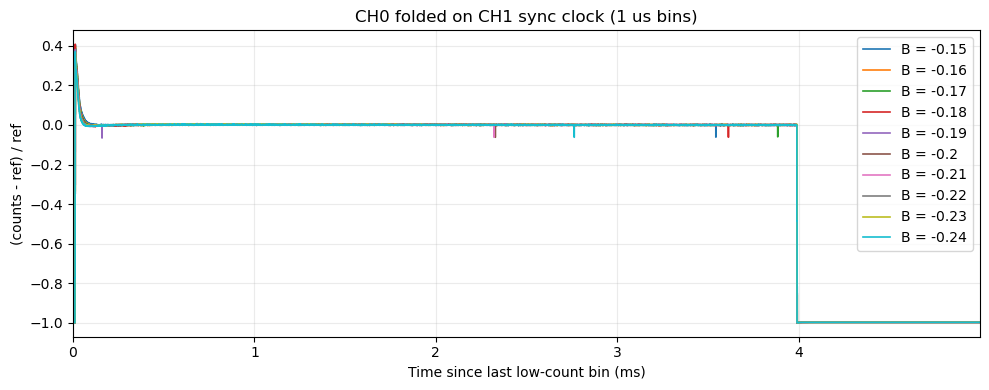

In [ ]:
DATA_ROOT = Path(r"Z:\Labs\G13\SSPDs\MoTe2_PP\20260606_B_stabilized3")
   
acqs = range(1,11)
fig, ax, traces = plot_sync_traces(
    acqs,
    sync_tick_stride=10,
    bin_us=1,
    t0_method="last_low",  
    unit="ms",
    data_root=DATA_ROOT,
    y_mode="self_normalized",
    ref_range=[3.7,3.8],
    save_fig=True,
    legend_metadata={
        # "X_det": "pulse_parameters.amp_det_meas",
        # "t_x": {"key": "pulse_parameters.t_x", "unit": "s", "fmt": ".3e"},
        # "t_meas": {"key": "pulse_parameters.t_meas", "unit": "s", "fmt": ".3e"},
        # "buffer": {"key": "pulse_parameters.buffer", "unit": "s", "fmt": ".3e"},
        "B":"B_field"
        # "t_det": {"key": "pulse_parameters.t_meas", "unit": "s", "fmt": ".1e"},
        # r"$\lambda = $":{"key": "pump wl", "unit": "nm", "fmt": ".2f"},
        # r"$V_\mu$" : {"key": "metadata.Vmu", "unit": "V", "fmt": ".2f"}
    },)
ax.legend(loc = 'best')
# ax.set_ylim(-0.3,0.3)
# ax.set_xlim(-0.1,200)


# time_ms = traces[0]["time_us"] / 1e3
# plot_y = traces[0]["plot_y"]

entries = get_metadata_entries(
    acqs,
    keys=["B_field"],#"pump wl", "Vmu","voa_requested_initial_voltage" ],
    data_root=DATA_ROOT,
)

### load reference
ref_zip = np.load(r"Q:\MoTe2_PP_local\20260701_RefMeas\acq_10_self_normalized_trace.npz")


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_12240\3245715627.py:11: RuntimeWarning: divide by zero encountered in divide
  refnormalized_sig = (traces[i]['plot_y'] + 1) / (ref_interp(t_ms_sig)+1) -1


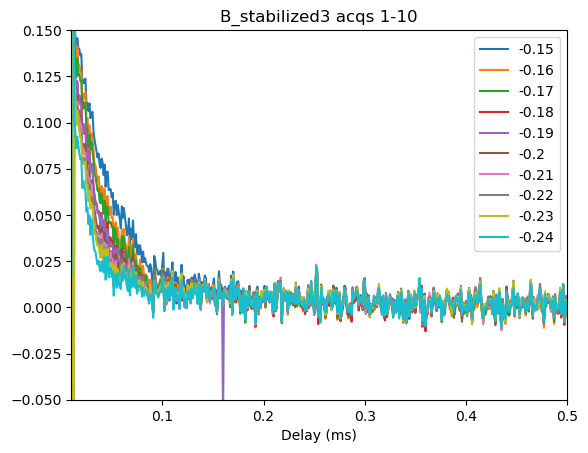

In [ ]:
time_ms_ref = ref_zip['time_ms']
y_ref  = ref_zip['plot_y']
# plt.plot(time_ms_ref, y_ref)
# plt.plot(traces[0]['time_us']/1e3,traces[0]['plot_y'])
# plt.ylim(0.9-1,1.3-1)
ref_interp = lambda t_ms: np.interp(t_ms, time_ms_ref, y_ref)


for i in range(len(traces)):
    t_ms_sig = traces[i]['time_us']/1e3
    refnormalized_sig = (traces[i]['plot_y'] + 1) / (ref_interp(t_ms_sig)+1) -1 
    plt.plot(t_ms_sig,refnormalized_sig, label = str(entries[i]["B_field"]))
plt.ylim(-0.05,.15)
plt.xlim(0.01,.5)
plt.xlabel("Delay (ms)")
plt.legend()
plt.title("B_stabilized3 acqs 1-10")
plt.savefig(os.path.join(DATA_ROOT,"refnorm_acqs_1-10.png"),dpi = 300)

### B stab 3 acqs 11-17


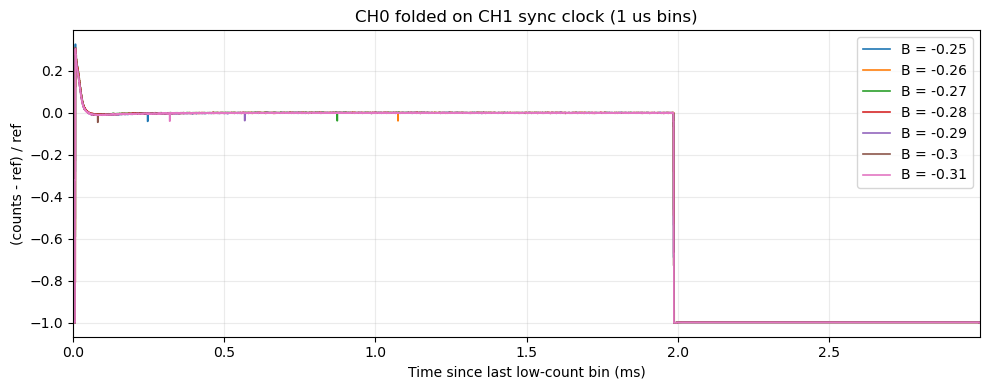

In [ ]:
DATA_ROOT = Path(r"Z:\Labs\G13\SSPDs\MoTe2_PP\20260606_B_stabilized3")
   
acqs = range(11,18)
fig, ax, traces = plot_sync_traces(
    acqs,
    sync_tick_stride=10,
    bin_us=1,
    t0_method="last_low",  
    unit="ms",
    data_root=DATA_ROOT,
    y_mode="self_normalized",
    ref_range=[1.5,1.8],
    save_fig=True,
    legend_metadata={
        # "X_det": "pulse_parameters.amp_det_meas",
        # "t_x": {"key": "pulse_parameters.t_x", "unit": "s", "fmt": ".3e"},
        # "t_meas": {"key": "pulse_parameters.t_meas", "unit": "s", "fmt": ".3e"},
        # "buffer": {"key": "pulse_parameters.buffer", "unit": "s", "fmt": ".3e"},
        "B":"B_field"
        # "t_det": {"key": "pulse_parameters.t_meas", "unit": "s", "fmt": ".1e"},
        # r"$\lambda = $":{"key": "pump wl", "unit": "nm", "fmt": ".2f"},
        # r"$V_\mu$" : {"key": "metadata.Vmu", "unit": "V", "fmt": ".2f"}
    },)
ax.legend(loc = 'best')
# ax.set_ylim(-0.3,0.3)
# ax.set_xlim(-0.1,200)


# time_ms = traces[0]["time_us"] / 1e3
# plot_y = traces[0]["plot_y"]

entries = get_metadata_entries(
    acqs,
    keys=["B_field"],#"pump wl", "Vmu","voa_requested_initial_voltage" ],
    data_root=DATA_ROOT,
)

### load reference
ref_zip = np.load(r"Q:\MoTe2_PP_local\20260701_RefMeas\acq_11_self_normalized_trace.npz")


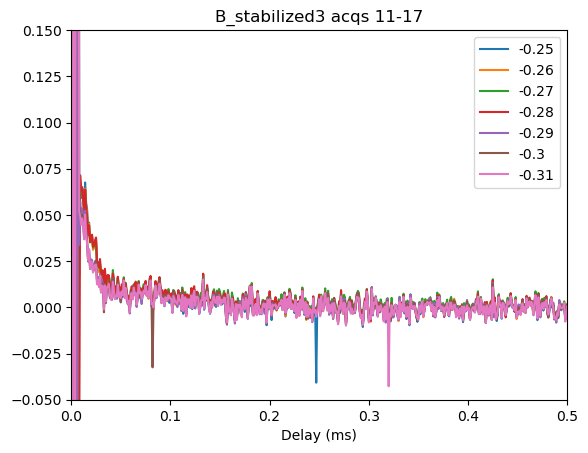

In [ ]:
time_ms_ref = ref_zip['time_ms']
y_ref  = ref_zip['plot_y']
# plt.plot(time_ms_ref, y_ref)
# plt.plot(traces[0]['time_us']/1e3,traces[0]['plot_y'])
# plt.ylim(0.9-1,1.3-1)
ref_interp = lambda t_ms: np.interp(t_ms, time_ms_ref, y_ref)


for i in range(len(traces)):
    t_ms_sig = traces[i]['time_us']/1e3
    refnormalized_sig = (traces[i]['plot_y'] + 1) / (ref_interp(t_ms_sig)+1) -1 
    plt.plot(t_ms_sig,refnormalized_sig, label = str(entries[i]["B_field"]))
plt.ylim(-0.05,.15)
plt.xlim(0,.5)
plt.xlabel("Delay (ms)")
plt.legend()
plt.title("B_stabilized3 acqs 11-17")
plt.savefig(os.path.join(DATA_ROOT,"refnorm_acqs_11-17.png"),dpi = 300)

### Vmu scan 3


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_12240\1166205840.py:1645: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


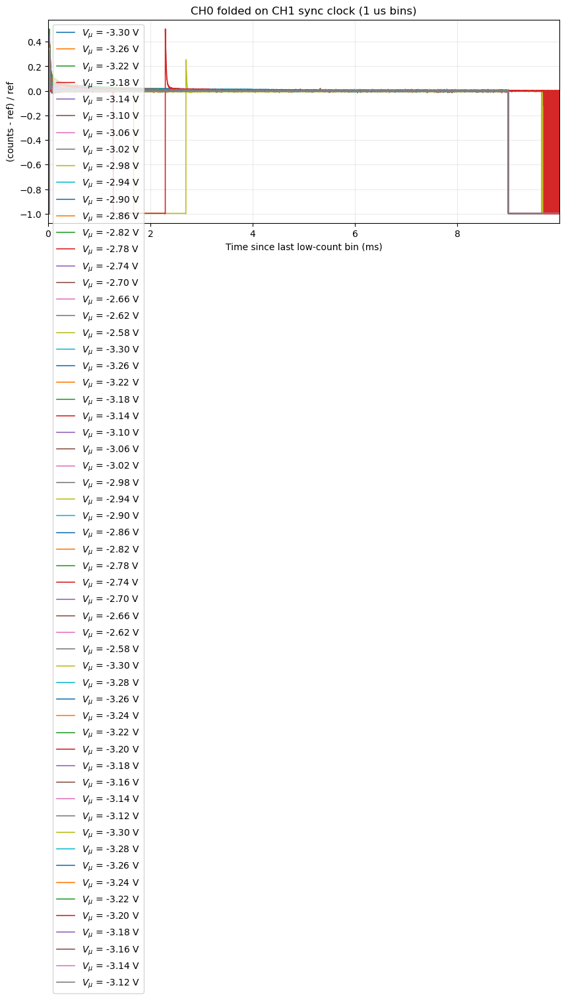

In [ ]:
DATA_ROOT = Path(r"Z:\Labs\G13\SSPDs\MoTe2_PP\20260607_vmu_scan3")
   
acqs = range(5,63)
fig, ax, traces = plot_sync_traces(
    acqs,
    sync_tick_stride=10,
    bin_us=1,
    t0_method="last_low",  
    unit="ms",
    data_root=DATA_ROOT,
    y_mode="self_normalized",
    ref_range=[8,8.5],
    save_fig=True,
    legend_metadata={
        # "X_det": "pulse_parameters.amp_det_meas",
        # "t_x": {"key": "pulse_parameters.t_x", "unit": "s", "fmt": ".3e"},
        # "t_meas": {"key": "pulse_parameters.t_meas", "unit": "s", "fmt": ".3e"},
        # "buffer": {"key": "pulse_parameters.buffer", "unit": "s", "fmt": ".3e"},
        # "B":"B_field"
        # "t_det": {"key": "pulse_parameters.t_meas", "unit": "s", "fmt": ".1e"},
        # r"$\lambda = $":{"key": "pump wl", "unit": "nm", "fmt": ".2f"},
        r"$V_\mu$" : {"key": "metadata.Vmu", "unit": "V", "fmt": ".2f"}
    },)
ax.legend(loc = 'best')
# ax.set_ylim(-0.3,0.3)
# ax.set_xlim(-0.1,200)


# time_ms = traces[0]["time_us"] / 1e3
# plot_y = traces[0]["plot_y"]

entries = get_metadata_entries(
    acqs,
    keys=["Vmu"],#"pump wl", "Vmu","voa_requested_initial_voltage" ],
    data_root=DATA_ROOT,
)

### load reference
ref_zip = np.load(r"Q:\MoTe2_PP_local\20260701_RefMeas\acq_8_self_normalized_trace.npz")


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_12240\958149476.py:11: RuntimeWarning: divide by zero encountered in divide
  refnormalized_sig = (traces[i]['plot_y'] + 1) / (ref_interp(t_ms_sig)+1) -1


Text(0.5, 1.0, 'Vmu_scan3')

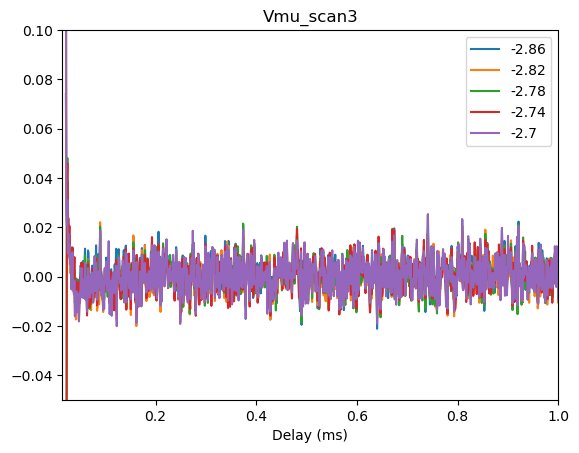

In [ ]:
time_ms_ref = ref_zip['time_ms']
y_ref  = ref_zip['plot_y']
# plt.plot(time_ms_ref, y_ref)
# plt.plot(traces[0]['time_us']/1e3,traces[0]['plot_y'])
# plt.ylim(0.9-1,1.3-1)
ref_interp = lambda t_ms: np.interp(t_ms, time_ms_ref, y_ref)


for i in range(30,35):#10,#range(len(traces)):
    t_ms_sig = traces[i]['time_us']/1e3
    refnormalized_sig = (traces[i]['plot_y'] + 1) / (ref_interp(t_ms_sig)+1) -1 
    plt.plot(t_ms_sig,refnormalized_sig, label = str(entries[i]["Vmu"]))

    np.savez(os.path.join(DATA_ROOT,f"acq_{i+1}_refnorm.npz"),t_ms_sig = t_ms_sig, refnormalized_sig = refnormalized_sig)
plt.ylim(-0.05,.1)
plt.xlim(0.015,1)
plt.xlabel("Delay (ms)")
plt.legend()
plt.title("Vmu_scan3")
# plt.savefig(os.path.join(DATA_ROOT,"refnorm_Vmu.png"),dpi = 300)

### Vmu scan 4


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_12240\1166205840.py:1645: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


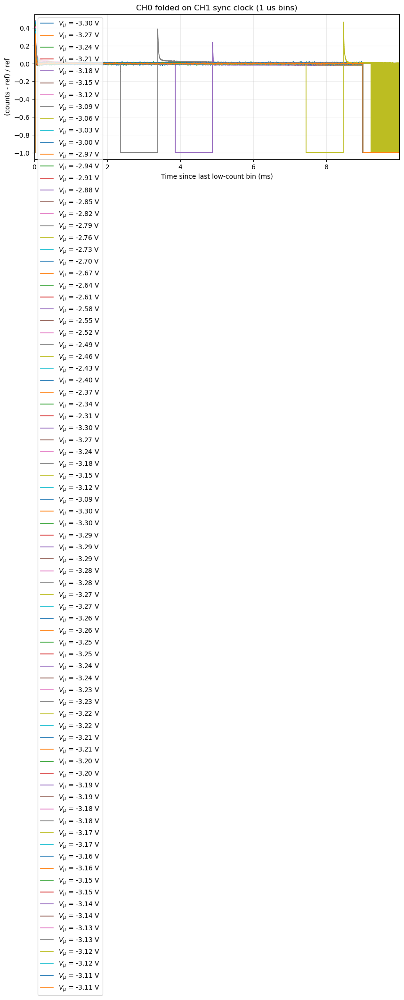

In [ ]:
DATA_ROOT = Path(r"Z:\Labs\G13\SSPDs\MoTe2_PP\20260607_vmu_scan4")
   
acqs = range(1,83)
fig, ax, traces = plot_sync_traces(
    acqs,
    sync_tick_stride=10,
    bin_us=1,
    t0_method="last_low",  
    unit="ms",
    data_root=DATA_ROOT,
    y_mode="self_normalized",
    ref_range=[1.9,2],
    save_fig=True,
    legend_metadata={
        # "X_det": "pulse_parameters.amp_det_meas",
        # "t_x": {"key": "pulse_parameters.t_x", "unit": "s", "fmt": ".3e"},
        # "t_meas": {"key": "pulse_parameters.t_meas", "unit": "s", "fmt": ".3e"},
        # "buffer": {"key": "pulse_parameters.buffer", "unit": "s", "fmt": ".3e"},
        # "B":"B_field"
        # "t_det": {"key": "pulse_parameters.t_meas", "unit": "s", "fmt": ".1e"},
        # r"$\lambda = $":{"key": "pump wl", "unit": "nm", "fmt": ".2f"},
        r"$V_\mu$" : {"key": "metadata.Vmu", "unit": "V", "fmt": ".2f"}
    },)
ax.legend(loc = 'best')
# ax.set_ylim(-0.3,0.3)
# ax.set_xlim(-0.1,200)


# time_ms = traces[0]["time_us"] / 1e3
# plot_y = traces[0]["plot_y"]

entries = get_metadata_entries(
    acqs,
    keys=["Vmu"],#"pump wl", "Vmu","voa_requested_initial_voltage" ],
    data_root=DATA_ROOT,
)

### load reference
ref_zip = np.load(r"Q:\MoTe2_PP_local\20260701_RefMeas\acq_8_self_normalized_trace.npz")


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_12240\3786421881.py:8: RuntimeWarning: divide by zero encountered in divide
  refnormalized_sig = (traces[i]['plot_y'] + 1) / (ref_interp(t_ms_sig)+1) -1


Text(0.5, 1.0, 'Vmu_scan3')

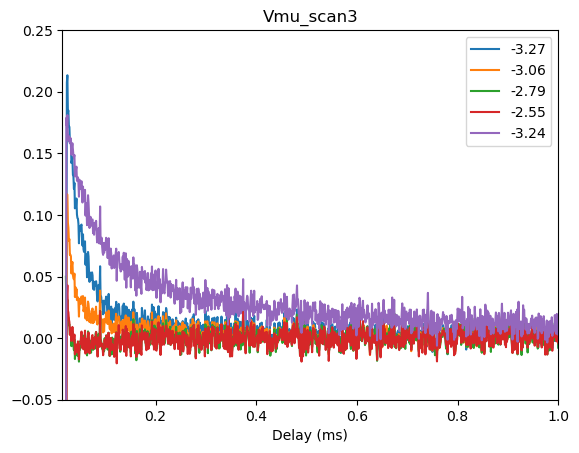

In [ ]:
time_ms_ref = ref_zip['time_ms']
y_ref  = ref_zip['plot_y']
ref_interp = lambda t_ms: np.interp(t_ms, time_ms_ref, y_ref)


for i in [1,8,17,25,36]:#range(len(traces)):
    t_ms_sig = traces[i]['time_us']/1e3
    refnormalized_sig = (traces[i]['plot_y'] + 1) / (ref_interp(t_ms_sig)+1) -1 
    plt.plot(t_ms_sig,refnormalized_sig, label = str(entries[i]["Vmu"]))

    np.savez(os.path.join(DATA_ROOT,f"acq_{i+1}_refnorm.npz"),t_ms_sig = t_ms_sig, refnormalized_sig = refnormalized_sig)
plt.ylim(-0.05,.25)
plt.xlim(0.015,1)
plt.xlabel("Delay (ms)")
plt.legend()
plt.title("Vmu_scan3")
# plt.savefig(os.path.join(DATA_ROOT,"refnorm_Vmu.png"),dpi = 300)

### Vmu scan 5


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_12240\1166205840.py:1645: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


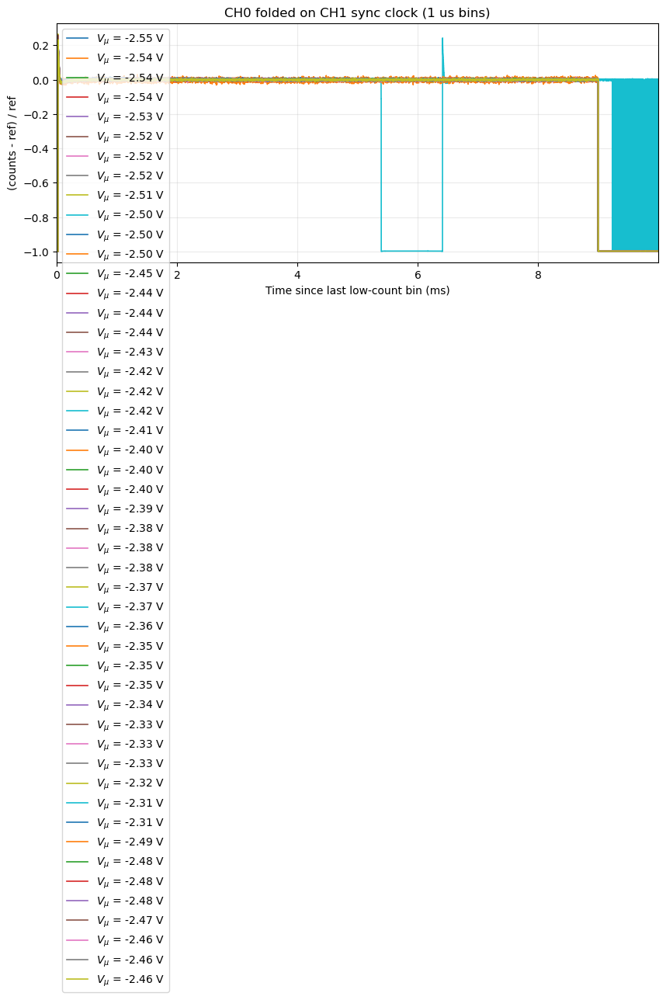

In [ ]:
DATA_ROOT = Path(r"Z:\Labs\G13\SSPDs\MoTe2_PP\20260609_vmuscan5")
   
acqs = range(1,50)
fig, ax, traces = plot_sync_traces(
    acqs,
    sync_tick_stride=10,
    bin_us=1,
    t0_method="last_low",  
    unit="ms",
    data_root=DATA_ROOT,
    y_mode="self_normalized",
    ref_range=[8.5,8.7],
    save_fig=True,
    legend_metadata={
        # "X_det": "pulse_parameters.amp_det_meas",
        # "t_x": {"key": "pulse_parameters.t_x", "unit": "s", "fmt": ".3e"},
        # "t_meas": {"key": "pulse_parameters.t_meas", "unit": "s", "fmt": ".3e"},
        # "buffer": {"key": "pulse_parameters.buffer", "unit": "s", "fmt": ".3e"},
        # "B":"B_field"
        # "t_det": {"key": "pulse_parameters.t_meas", "unit": "s", "fmt": ".1e"},
        # r"$\lambda = $":{"key": "pump wl", "unit": "nm", "fmt": ".2f"},
        r"$V_\mu$" : {"key": "metadata.Vmu", "unit": "V", "fmt": ".2f"}
    },)
ax.legend(loc = 'best')
# ax.set_ylim(-0.3,0.3)
# ax.set_xlim(-0.1,200)


# time_ms = traces[0]["time_us"] / 1e3
# plot_y = traces[0]["plot_y"]

entries = get_metadata_entries(
    acqs,
    keys=["Vmu"],#"pump wl", "Vmu","voa_requested_initial_voltage" ],
    data_root=DATA_ROOT,
)

### load reference
ref_zip = np.load(r"Q:\MoTe2_PP_local\20260701_RefMeas\acq_8_self_normalized_trace.npz")


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_12240\190515801.py:8: RuntimeWarning: divide by zero encountered in divide
  refnormalized_sig = (traces[i]['plot_y'] + 1) / (ref_interp(t_ms_sig)+1) -1


Text(0.5, 1.0, 'Vmu_scan5')

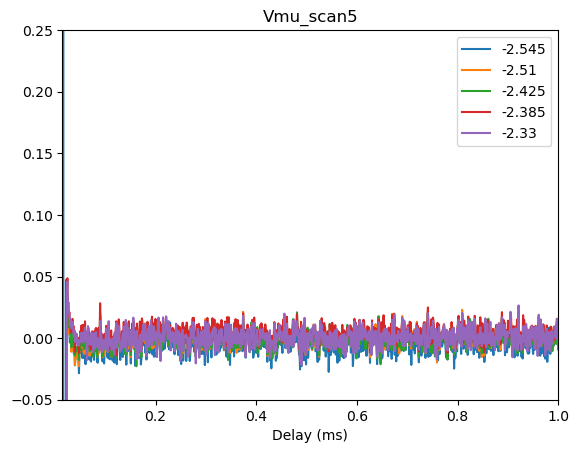

In [ ]:
time_ms_ref = ref_zip['time_ms']
y_ref  = ref_zip['plot_y']
ref_interp = lambda t_ms: np.interp(t_ms, time_ms_ref, y_ref)


for i in [1,8,17,25,36]:# range(len(traces)):
    t_ms_sig = traces[i]['time_us']/1e3
    refnormalized_sig = (traces[i]['plot_y'] + 1) / (ref_interp(t_ms_sig)+1) -1 
    plt.plot(t_ms_sig,refnormalized_sig, label = str(entries[i]["Vmu"]))

    np.savez(os.path.join(DATA_ROOT,f"acq_{i+1}_refnorm.npz"),t_ms_sig = t_ms_sig, refnormalized_sig = refnormalized_sig)
plt.ylim(-0.05,.25)
plt.xlim(0.015,1)
plt.xlabel("Delay (ms)")
plt.legend()
plt.title("Vmu_scan5")
# plt.savefig(os.path.join(DATA_ROOT,"refnorm_Vmu.png"),dpi = 300)

# 3 July Weekend measurement, searching for dynamics

## SP

In [182]:
DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260703_vortex_two_excitation_SP")

# First collect all reference traces
all_refs = []
t_ref = None

for i in range(32):
    acqs = [2*i + 2]

    fig, ax, traces = plot_sync_traces(
        acqs,
        sync_tick_stride=100,
        bin_us=0.5,
        t0_method="metadata_windows",
        unit="ms",
        data_root=DATA_ROOT,
        y_mode="self_normalized",
        ref_range=[1.08, 1.09],
        save_fig=True,
        force_recompute=False,
        legend_metadata={
            "buffer": {"key": "pulse_parameters.buffer", "unit": "s", "fmt": ".3e"},
            r"$V_\mu$": {"key": "metadata.Vmu", "unit": "V", "fmt": ".2f"},
            "VOA": "metadata.voa_requested_initial_voltage",
        },
    )
    plt.close(fig)

    ref = traces[0]["plot_y"] + 1
    t = traces[0]["time_us"] / 1e3

    if t_ref is None:
        t_ref = t
    else:
        n = min(len(t_ref), len(t), len(ref))
        t_ref = t_ref[:n]
        all_refs = [r[:n] for r in all_refs]
        ref = ref[:n]

    all_refs.append(ref)

all_refs = np.array(all_refs)
ref_std = np.std(all_refs, axis=0)
ref_mean = np.mean(all_refs, axis=0)

C:\Users\SSPDs\AppData\Local\Temp\ipykernel_13080\2802371418.py:38: RuntimeWarning: divide by zero encountered in divide
  corr = sig / ref
C:\Users\SSPDs\AppData\Local\Temp\ipykernel_13080\2802371418.py:38: RuntimeWarning: invalid value encountered in divide
  corr = sig / ref
C:\Users\SSPDs\AppData\Local\Temp\ipykernel_13080\2399075722.py:1644: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=(10, 4))
C:\Users\SSPDs\AppData\Local\Temp\ipykernel_13080\2802371418.py:42: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see

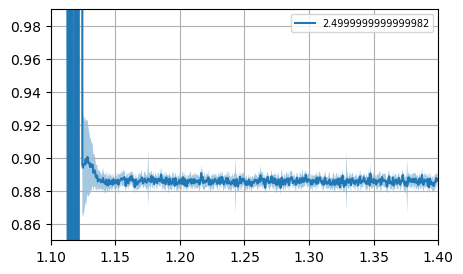

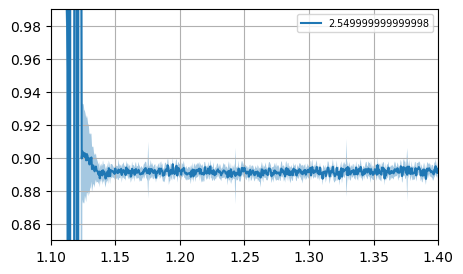

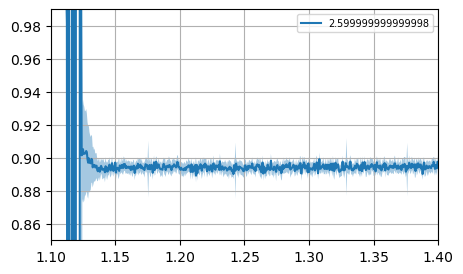

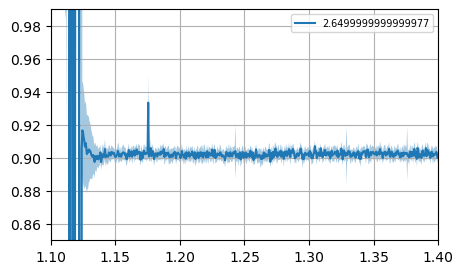

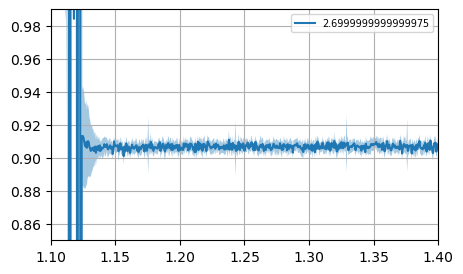

...

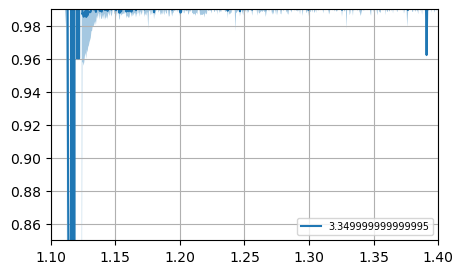

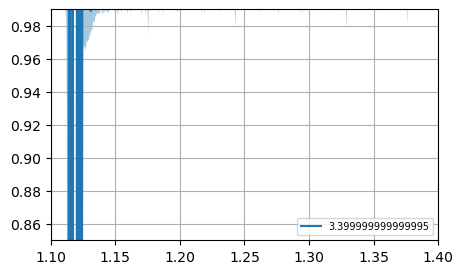

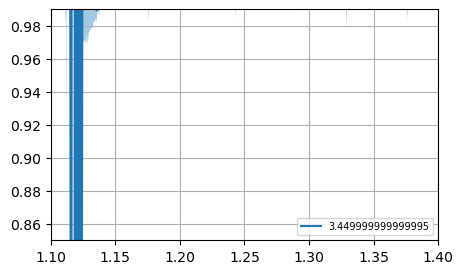

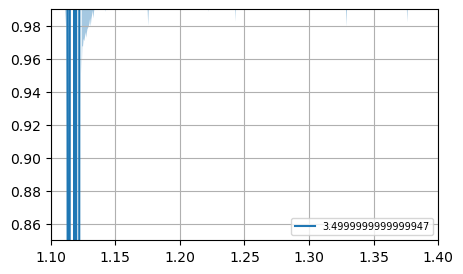

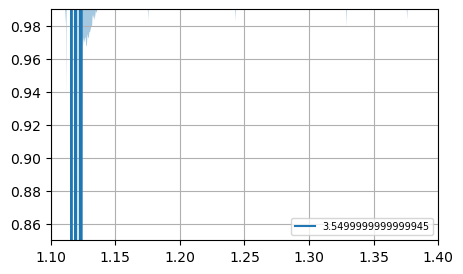

In [186]:

for i in range(10,32):
    acqs = [2*i + 1, 2*i + 2]

    fig, ax, traces = plot_sync_traces(
        acqs,
        sync_tick_stride=100,
        bin_us=0.5,
        t0_method="metadata_windows",
        unit="ms",
        data_root=DATA_ROOT,
        y_mode="self_normalized",
        ref_range=[1.08, 1.09],
        save_fig=True,
        force_recompute=False,
        legend_metadata={
            "buffer": {"key": "pulse_parameters.buffer", "unit": "s", "fmt": ".3e"},
            r"$V_\mu$": {"key": "metadata.Vmu", "unit": "V", "fmt": ".2f"},
            "VOA": "metadata.voa_requested_initial_voltage",
        },
    )
    plt.close(fig)

    entries = get_metadata_entries(
        acqs,
        keys=["voa_requested_initial_voltage"],
        data_root=DATA_ROOT,
    )

    sig = traces[0]["plot_y"] + 1
    ref = traces[1]["plot_y"] + 1
    t = traces[0]["time_us"] / 1e3

    n = min(len(sig), len(ref), len(t))
    sig = sig[:n]
    ref = ref[:n]
    t = t[:n]

    corr = sig / ref

    # Interpolate reference std onto this trace's time axis, in case lengths differ.
    sigma_ref = np.interp(t, t_ref, ref_std)
    fig_corr, ax_corr = plt.subplots(figsize=(5, 3))

    label = entries[0]["voa_requested_initial_voltage"]
    line, = ax_corr.plot(t, corr, label=label)

    ax_corr.fill_between(
        t,
        corr - 3*sigma_ref,
        corr + 3*sigma_ref,
        color=line.get_color(),
        alpha=0.4,
        linewidth=0,
    )


    # mask = (t < 1.34) & (t > 1.30) & np.isfinite(corr)
    # sig_mean = np.nanmean(corr[mask]) if np.any(mask) else np.nan
    # ax_corr.set_ylim(sig_mean*0.9,sig_mean*1.1)
    ax_corr.set_ylim(0.85,0.99)
    ax_corr.set_xlim(1.1, 1.4)
    ax_corr.grid()
    ax_corr.legend(fontsize=7)
    

## SM

In [180]:
DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260703_vortex_two_excitation_SM")

# First collect all reference traces
all_refs = []
t_ref = None

for i in range(27):
    acqs = [2*i + 2]

    fig, ax, traces = plot_sync_traces(
        acqs,
        sync_tick_stride=100,
        bin_us=0.5,
        t0_method="metadata_windows",
        unit="ms",
        data_root=DATA_ROOT,
        y_mode="self_normalized",
        ref_range=[1.08, 1.09],
        save_fig=True,
        force_recompute=False,
        legend_metadata={
            "buffer": {"key": "pulse_parameters.buffer", "unit": "s", "fmt": ".3e"},
            r"$V_\mu$": {"key": "metadata.Vmu", "unit": "V", "fmt": ".2f"},
            "VOA": "metadata.voa_requested_initial_voltage",
        },
    )
    plt.close(fig)

    ref = traces[0]["plot_y"] + 1
    t = traces[0]["time_us"] / 1e3

    if t_ref is None:
        t_ref = t
    else:
        n = min(len(t_ref), len(t), len(ref))
        t_ref = t_ref[:n]
        all_refs = [r[:n] for r in all_refs]
        ref = ref[:n]

    all_refs.append(ref)

all_refs = np.array(all_refs)
ref_std = np.std(all_refs, axis=0)
ref_mean = np.mean(all_refs, axis=0)

C:\Users\SSPDs\AppData\Local\Temp\ipykernel_13080\299411617.py:38: RuntimeWarning: divide by zero encountered in divide
  corr = sig / ref
C:\Users\SSPDs\AppData\Local\Temp\ipykernel_13080\299411617.py:38: RuntimeWarning: invalid value encountered in divide
  corr = sig / ref


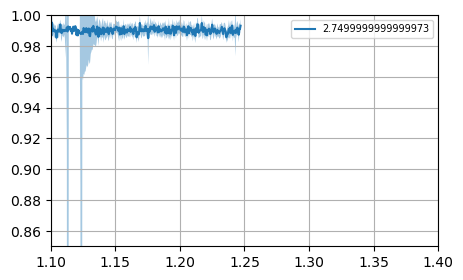

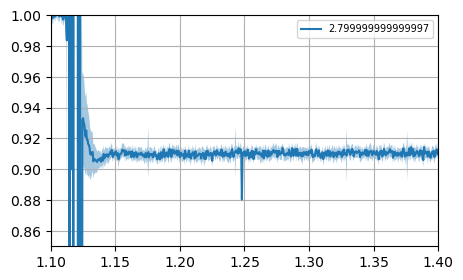

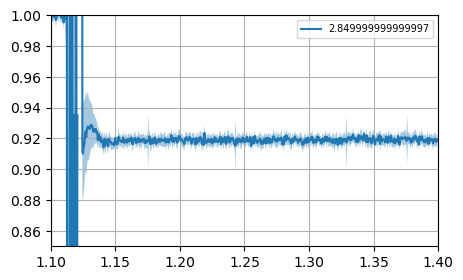

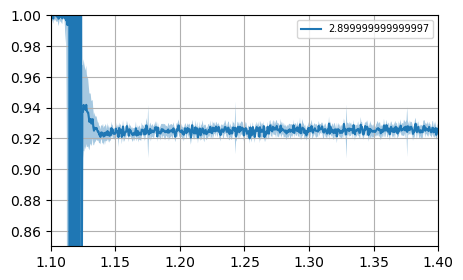

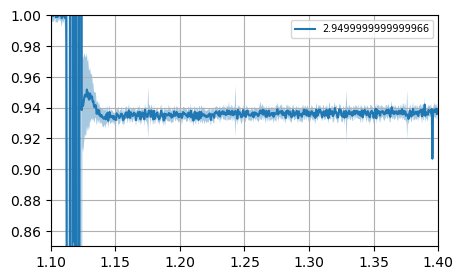

...

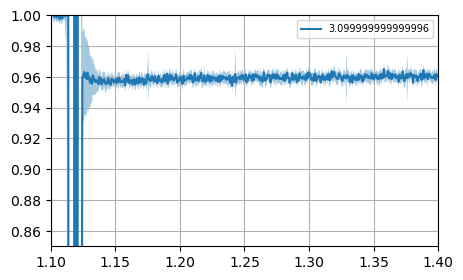

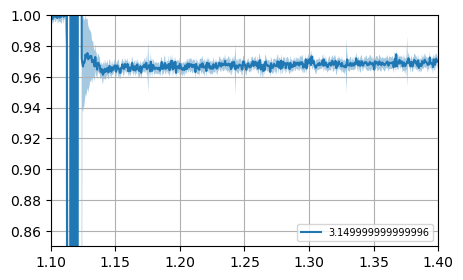

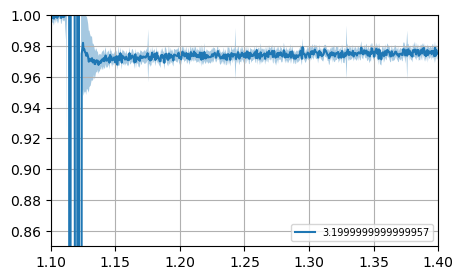

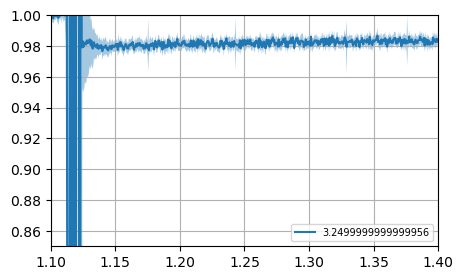

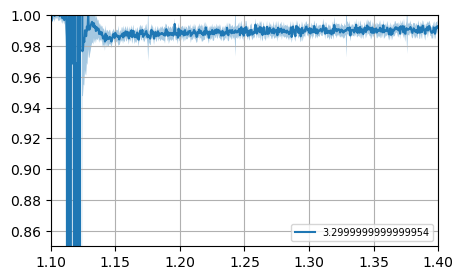

In [187]:

for i in range(15,27):
    acqs = [2*i + 1, 2*i + 2]

    fig, ax, traces = plot_sync_traces(
        acqs,
        sync_tick_stride=100,
        bin_us=0.5,
        t0_method="metadata_windows",
        unit="ms",
        data_root=DATA_ROOT,
        y_mode="self_normalized",
        ref_range=[1.08, 1.09],
        save_fig=True,
        force_recompute=False,
        legend_metadata={
            "buffer": {"key": "pulse_parameters.buffer", "unit": "s", "fmt": ".3e"},
            r"$V_\mu$": {"key": "metadata.Vmu", "unit": "V", "fmt": ".2f"},
            "VOA": "metadata.voa_requested_initial_voltage",
        },
    )
    plt.close(fig)

    entries = get_metadata_entries(
        acqs,
        keys=["voa_requested_initial_voltage"],
        data_root=DATA_ROOT,
    )

    sig = traces[0]["plot_y"] + 1
    ref = traces[1]["plot_y"] + 1
    t = traces[0]["time_us"] / 1e3

    n = min(len(sig), len(ref), len(t))
    sig = sig[:n]
    ref = ref[:n]
    t = t[:n]

    corr = sig / ref

    # Interpolate reference std onto this trace's time axis, in case lengths differ.
    sigma_ref = np.interp(t, t_ref, ref_std)
    fig_corr, ax_corr = plt.subplots(figsize=(5, 3))

    label = entries[0]["voa_requested_initial_voltage"]
    line, = ax_corr.plot(t, corr, label=label)

    ax_corr.fill_between(
        t,
        corr - 3*sigma_ref,
        corr + 3*sigma_ref,
        color=line.get_color(),
        alpha=0.4,
        linewidth=0,
    )


#   sig_mean = np.mean(corr[(t<1.34) & (t>1.30)  ])
#     ax_corr.set_ylim(sig_mean*0.9,sig_mean*1.1)
    ax_corr.set_ylim(0.85,1)
    ax_corr.set_xlim(1.1, 1.4)
    ax_corr.grid()
    ax_corr.legend(fontsize=7)
    

# Checking how much the Vmu = 0 traces vary as a function of LG power/measurement time

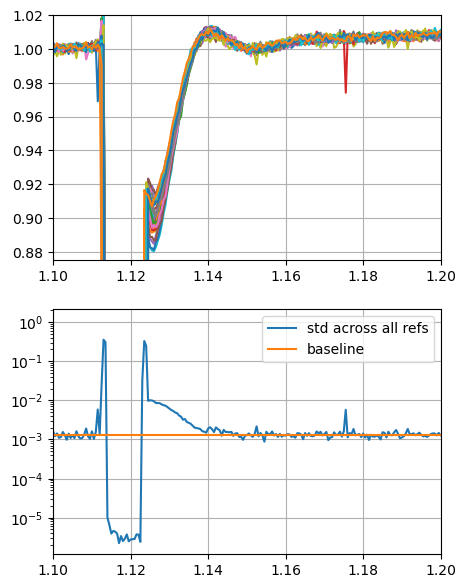

In [168]:
DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260703_vortex_two_excitation_SM")
   
all_refs = []

fig_refs,ax_refs = plt.subplots(2,1,figsize = (5,7))
for i in range(27):
    acqs = [2*i+2]
    fig, ax, traces = plot_sync_traces(
        acqs,
        sync_tick_stride=100,
        bin_us=0.5,
        t0_method="metadata_windows",  
        unit="ms",
        data_root=DATA_ROOT,
        y_mode="self_normalized",
        ref_range=[1.08,1.09],
        save_fig=True,
        force_recompute=False,
        legend_metadata={
            # "X_det": "pulse_parameters.amp_det_meas",
            # "t_x": {"key": "pulse_parameters.t_x", "unit": "s", "fmt": ".3e"},
            # "t_meas": {"key": "pulse_parameters.t_meas", "unit": "s", "fmt": ".3e"},
            "buffer": {"key": "pulse_parameters.buffer", "unit": "s", "fmt": ".3e"},
            # "B":"B_field"
            # "t_det": {"key": "pulse_parameters.t_meas", "unit": "s", "fmt": ".1e"},
            # r"$\lambda = $":{"key": "pump wl", "unit": "nm", "fmt": ".2f"},
            r"$V_\mu$" : {"key": "metadata.Vmu", "unit": "V", "fmt": ".2f"},
            "VOA": "metadata.voa_requested_initial_voltage"
        },)
    ax.legend(loc = 'best')
    # ax.set_ylim(-0.3,0.3)
    # ax.set_xlim(0.1,0.12)
    plt.close(fig)

    # time_ms = traces[0]["time_us"] / 1e3
    # plot_y = traces[0]["plot_y"]

    entries = get_metadata_entries(
        acqs,
        keys=["voa_requested_initial_voltage"],
        data_root=DATA_ROOT,
    )

    # sig = traces[0]['plot_y']+1
    ref = traces[0]['plot_y']+1
    t = traces[0]['time_us']/1e3
    all_refs.append(ref)


    # corr = sig[:min(len(ref),len(sig))]/ref[:min(len(ref),len(sig))]
    # t = t[:min(len(ref),len(sig))]
    # plt.plot(t,corr, label= entries[0]['voa_requested_initial_voltage'])
    # plt.plot(t,sig )
    plt.sca(ax_refs[0])
    plt.plot(t,ref,label=acqs[0] )


plt.ylim(0.875,1.02)
plt.xlim(1.1,1.2)
plt.grid()

# plt.legend(loc='lower left',fontsize = 6)
plt.sca(ax_refs[1])
all_refs =np.array(all_refs)
vr = np.std(all_refs,axis = 0)
plt.plot(t, vr,label='std across all refs')
plt.yscale('log')
plt.xlim(1.1,1.2)
plt.plot([1.1,1.2],np.ones(2)*np.mean(vr[(t<1.11)&(t>1.1)]) ,label='baseline')
plt.legend()
plt.grid()


Text(0, 0.5, 'Ref at t = 1.127 ms')

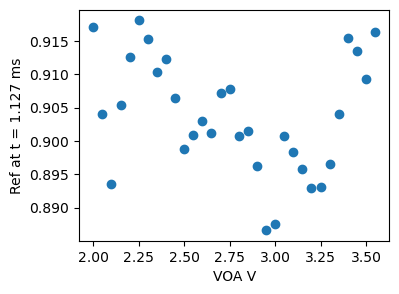

In [170]:

voas = get_metadata_entries(
        [2*i+2 for i in range(32)],
        keys=["voa_requested_initial_voltage"],
        data_root=DATA_ROOT,
    )
plt.figure(figsize = (4,3))
plt.scatter([voa['voa_requested_initial_voltage'] for voa in voas],all_refs[:,find_nearest(t, 1.127)])
plt.xlabel("VOA V")
plt.ylabel("Ref at t = 1.127 ms")

# 6 July Corroborating potential dynamics at 1 uW LG power

## Spot 1 (Ax 1 = 36 V, Ax 2 = 11 V)

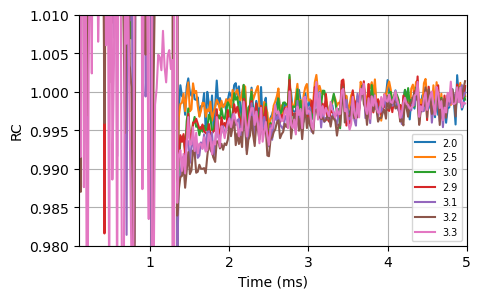

In [86]:
DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260706_vortex_two_excitation_SM_2")

REF_ACQ = 16 

fig_ref, ax_ref, ref_traces = plot_sync_traces(
    [REF_ACQ],
    sync_tick_stride=100,
    bin_us=10,
    t0_method="metadata_windows",
    unit="ms",
    data_root=DATA_ROOT,
    y_mode="self_normalized",
    ref_range=[4.88, 4.91],
    save_fig=True,
    force_recompute=False,
)

fixed_ref = ref_traces[0]["plot_y"] + 1
t_ref = ref_traces[0]["time_us"] / 1e3
plt.close(fig_ref)


fig_corr, ax_corr = plt.subplots(figsize=(5, 3))

for sig_acq in [13,14,15,17,18,19,20]:
    

    fig, ax, traces = plot_sync_traces(
        [sig_acq],
        sync_tick_stride=100,
        bin_us=20,
        t0_method="metadata_windows",
        unit="ms",
        data_root=DATA_ROOT,
        y_mode="self_normalized",
        ref_range=[4.8,4.9],#[1.11,1.12],
        save_fig=True,
        force_recompute=False,
        legend_metadata={
            "buffer": {"key": "pulse_parameters.buffer", "unit": "s", "fmt": ".3e"},
            r"$V_\mu$": {"key": "metadata.Vmu", "unit": "V", "fmt": ".2f"},
            "VOA": "metadata.voa_requested_initial_voltage",
        },
    )
    plt.close(fig)

    entries = get_metadata_entries(
        [sig_acq],
        keys=["voa_requested_initial_voltage"],
        data_root=DATA_ROOT,
    )

    sig = traces[0]["plot_y"] + 1
    t = traces[0]["time_us"] / 1e3

    ref = np.interp(t, t_ref, fixed_ref)

    valid = np.isfinite(sig) & np.isfinite(ref) & (ref != 0)
    corr = np.full_like(sig, np.nan, dtype=float)
    corr[valid] = sig[valid] / ref[valid]

    label = entries[0]["voa_requested_initial_voltage"]
    ax_corr.plot(t, corr, label=label)

ax_corr.set_ylim(0.86,1.01)
ax_corr.set_ylim(0.98,1.01)

ax_corr.set_xlim(0.1, 5)
ax_corr.set_xlabel("Time (ms)")
ax_corr.set_ylabel("RC")
ax_corr.grid()
ax_corr.legend(fontsize=7)

## Spot 2 (Ax 1 = 36 V, Ax 2 = 9 V)
.... some 200 nm away from the first spot

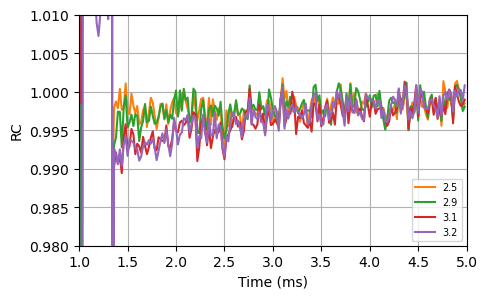

In [94]:
DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260706_vortex_two_excitation_SM_2")

REF_ACQ = 16 

fig_ref, ax_ref, ref_traces = plot_sync_traces(
    [REF_ACQ],
    sync_tick_stride=100,
    bin_us=10,
    t0_method="metadata_windows",
    unit="ms",
    data_root=DATA_ROOT,
    y_mode="self_normalized",
    ref_range=[4.88, 4.91],
    save_fig=True,
    force_recompute=False,
)

fixed_ref = ref_traces[0]["plot_y"] + 1
t_ref = ref_traces[0]["time_us"] / 1e3
plt.close(fig_ref)


fig_corr, ax_corr = plt.subplots(figsize=(5, 3))
ax_corr.plot([],[] ,label=None)
for sig_acq in [21,22,23,24]:
    

    fig, ax, traces = plot_sync_traces(
        [sig_acq],
        sync_tick_stride=100,
        bin_us=20,
        t0_method="metadata_windows",
        unit="ms",
        data_root=DATA_ROOT,
        y_mode="self_normalized",
        # ref_range=[1.11,1.12],
        ref_range=[4.8,4.9],#
        save_fig=True,
        force_recompute=False,
        legend_metadata={
            "buffer": {"key": "pulse_parameters.buffer", "unit": "s", "fmt": ".3e"},
            r"$V_\mu$": {"key": "metadata.Vmu", "unit": "V", "fmt": ".2f"},
            "VOA": "metadata.voa_requested_initial_voltage",
        },
    )
    plt.close(fig)

    entries = get_metadata_entries(
        [sig_acq],
        keys=["voa_requested_initial_voltage"],
        data_root=DATA_ROOT,
    )

    sig = traces[0]["plot_y"] + 1
    t = traces[0]["time_us"] / 1e3

    ref = np.interp(t, t_ref, fixed_ref)

    valid = np.isfinite(sig) & np.isfinite(ref) & (ref != 0)
    corr = np.full_like(sig, np.nan, dtype=float)
    corr[valid] = sig[valid] / ref[valid]

    label = entries[0]["voa_requested_initial_voltage"]
    ax_corr.plot(t, corr, label=label)

ax_corr.set_ylim(0.86,1.01)
ax_corr.set_ylim(0.98,1.01)

ax_corr.set_xlim(1, 5)
ax_corr.set_xlabel("Time (ms)")
ax_corr.set_ylabel("RC")
ax_corr.grid()
ax_corr.legend(fontsize=7)

# Several spots on the sample:  

[1, 2, 3, 4, 5, 6, 7, 8, 9]
[10, 11, 12, 13, 14, 15, 16, 17, 18]
[19, 20, 21, 22, 23, 24, 25, 26, 27]
[28, 29, 30, 31, 32, 33, 34, 35, 36]
[37, 38, 39, 40, 41, 42, 43, 44]


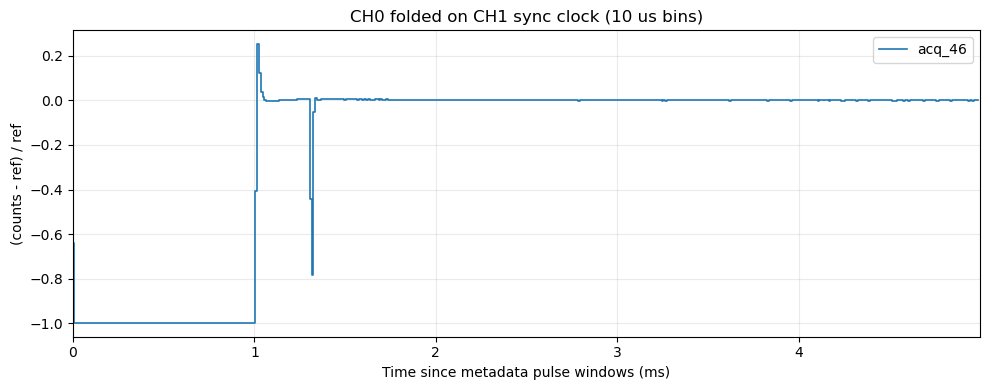

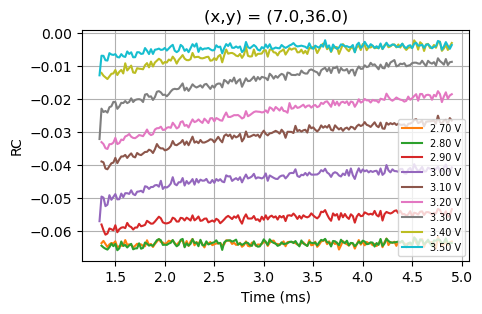

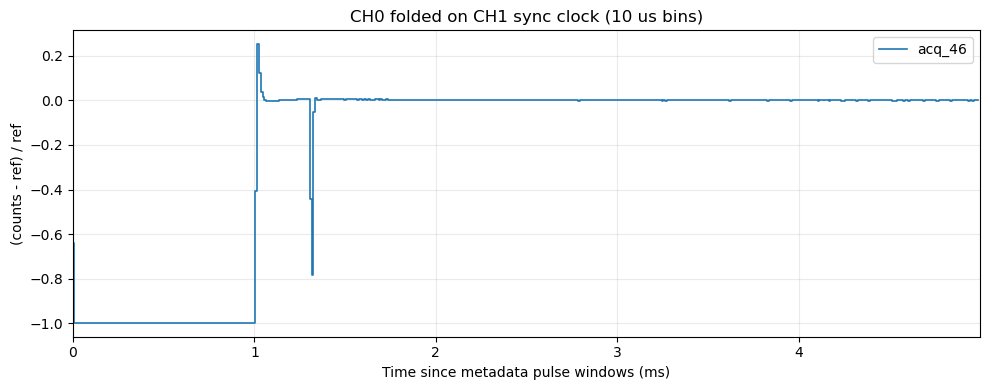

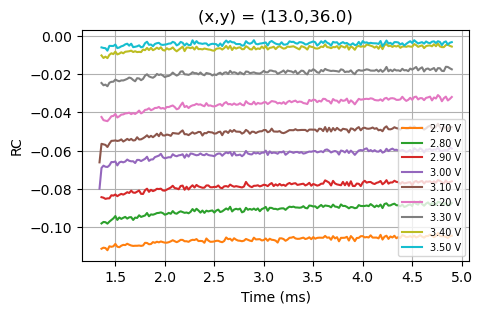

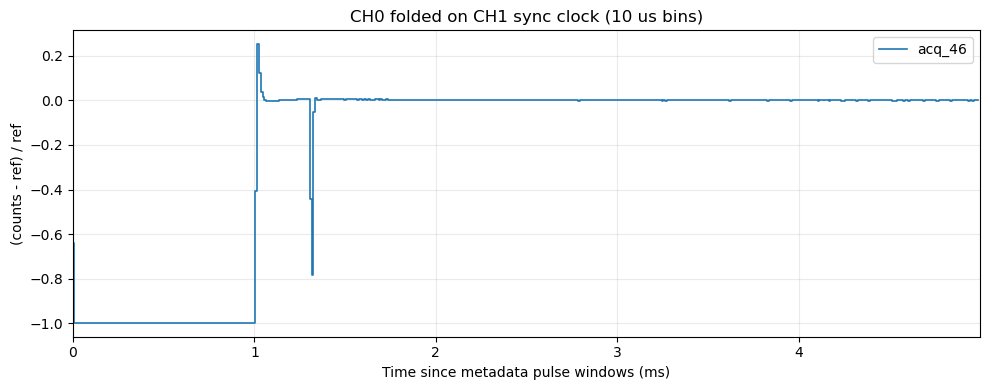

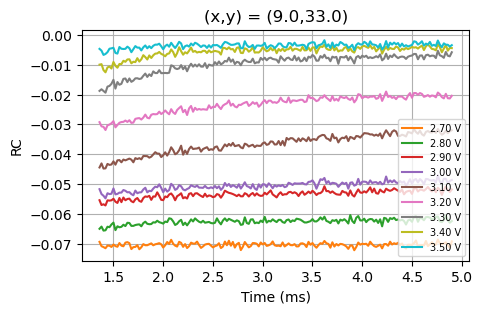

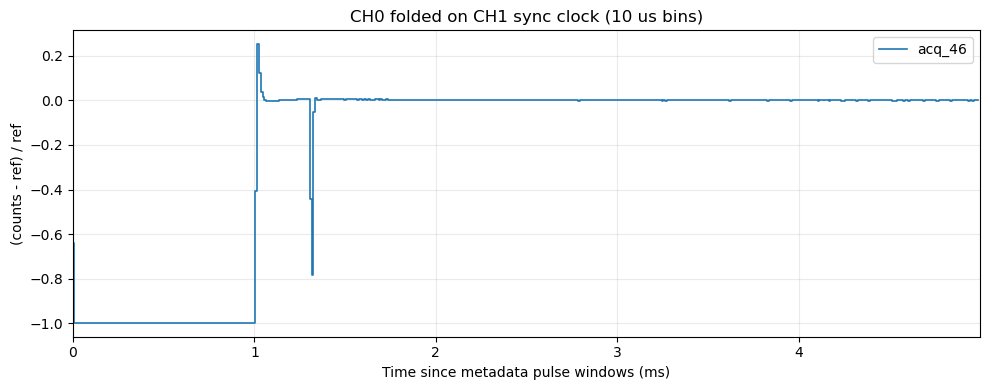

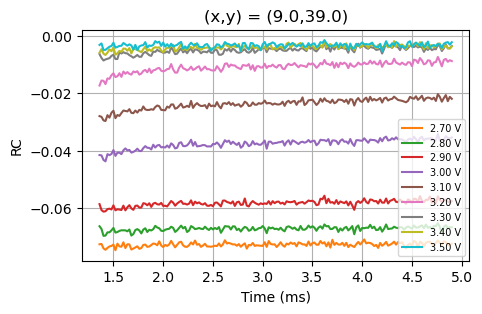

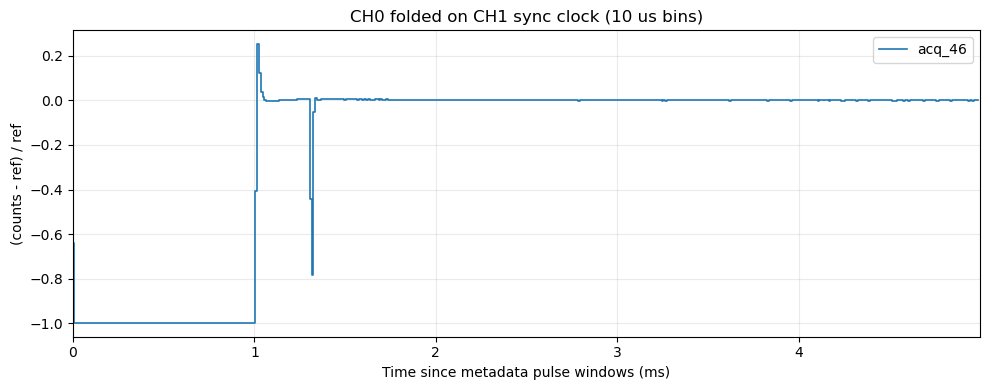

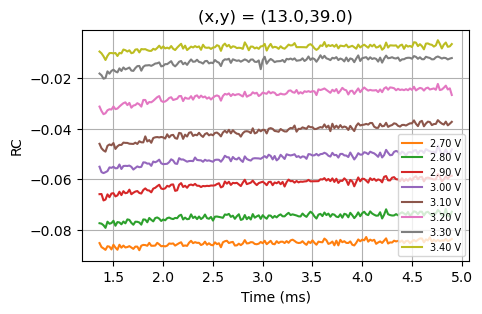

In [174]:
x_pos = np.array([7,  13, 9,   9, 13]) #by default 11
y_pos = np.array([36, 36, 33, 39, 39]) #by default 36

DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260706_vortex_two_excitation_SM_3_overnight_spatial_scan")

for xs,ys in zip(x_pos, y_pos):
    acqs = matching_acqs_by_parameters(
        metadata_filters={
             "metadata.description": r"Vortex two-excitation test measurement, short time delays, intermediate powers, SM, ax1 = %.1f, ax2 = %.1f"%(xs,ys)
        },
        data_root=DATA_ROOT,
        require_raw=False,
        require_analysis=True,
    )
    print(acqs)
    REF_ACQ = 46
    fig_ref, ax_ref, ref_traces = plot_sync_traces(
        [REF_ACQ],
        sync_tick_stride=100,
        bin_us=10,
        t0_method="metadata_windows",
        unit="ms",
        data_root=DATA_ROOT,
        y_mode="self_normalized",
        ref_range=[4.88, 4.91],
        save_fig=True,
        force_recompute=False,
    )

    fixed_ref = ref_traces[0]["plot_y"] + 1
    t_ref = ref_traces[0]["time_us"] / 1e3
    # plt.close(fig_ref)


    fig_corr, ax_corr = plt.subplots(figsize=(5, 3))
    ax_corr.plot([],[] ,label=None)
    for sig_acq in acqs:
        
        fig, ax, traces = plot_sync_traces(
            [sig_acq],
            sync_tick_stride=100,
            bin_us=20,
            t0_method="metadata_windows",
            unit="ms",
            data_root=DATA_ROOT,
            y_mode="self_normalized",
            # ref_range=[1.11,1.12],
            ref_range=[1.2,1.25],#
            save_fig=True,
            force_recompute=False,
            legend_metadata={
                # "buffer": {"key": "pulse_parameters.buffer", "unit": "s", "fmt": ".3e"},
                # r"$V_\mu$": {"key": "metadata.Vmu", "unit": "V", "fmt": ".2f"},
                "VOA": "metadata.voa_requested_initial_voltage",
            },
        )
        plt.close(fig)

        entries = get_metadata_entries(
            [sig_acq],
            keys=["voa_requested_initial_voltage"],
            data_root=DATA_ROOT,
        )

        sig = traces[0]["plot_y"] + 1
        t = traces[0]["time_us"] / 1e3

        ref = np.interp(t, t_ref, fixed_ref)

        valid = np.isfinite(sig) & np.isfinite(ref) & (ref != 0)
        corr = np.full_like(sig, np.nan, dtype=float)
        corr[valid] = sig[valid] / ref[valid]

        ####### SAVE THIS DATA
        cache_dir = DATA_ROOT / f"acq_{sig_acq}_pump_probe_folded"
        out_path = cache_dir / f"acq_{sig_acq}_corrected_by_acq_{REF_ACQ}_bin20us_metadata_windows.npz"

        np.savez_compressed(
            out_path,
            time_ms=t,
            corrected=corr - 1,
            corr_raw=corr,
            signal=sig,
            reference_interp=ref,
            reference_acq=REF_ACQ,
            signal_acq=sig_acq,
            voa_requested_initial_voltage=entries[0]["voa_requested_initial_voltage"],
            x_pos=xs,
            y_pos=ys,
            t0_method="metadata_windows",
            bin_us=20,
            ref_range=np.array([1.2, 1.25]),
        )

        label = f'{entries[0]["voa_requested_initial_voltage"]:.2f} V'
        ax_corr.plot(t[(t>1.34)&(t<4.9)], corr[(t>1.34)&(t<4.9)] - 1, label=label)

    # ax_corr.set_ylim(-0.1,0.0)
    plt.title('(x,y) = (%.1f,%.1f)'%(xs,ys))
    # ax_corr.set_xlim(1.3, 5)
    ax_corr.set_xlabel("Time (ms)")
    ax_corr.set_ylabel("RC")
    ax_corr.grid()
    ax_corr.legend(fontsize=7,loc = 'lower right')
    plt.savefig(r'Q:\MoTe2_PP_local\20260706_vortex_two_excitation_SM_3_overnight_spatial_scan\Corrected_LG_dynamics_xs_%.1f_ys_%.1f_init_norm.png'%(xs,ys),dpi=600,facecolor='w')

### Fitting timescales to the corrected data

[1, 2, 3, 4, 5, 6, 7, 8, 9]


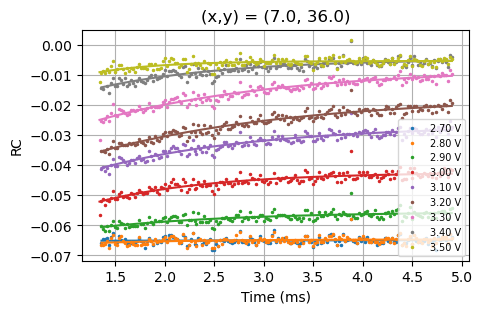

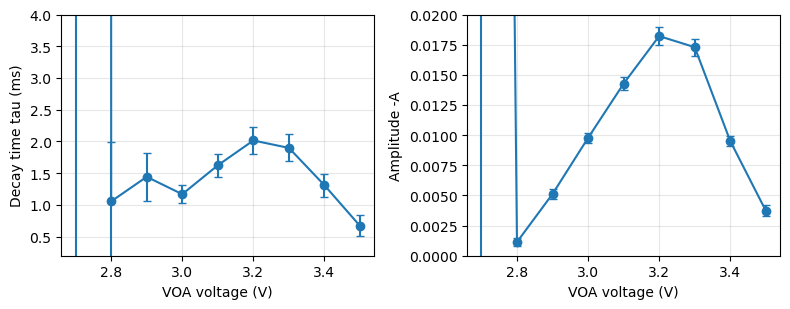

[10, 11, 12, 13, 14, 15, 16, 17, 18]


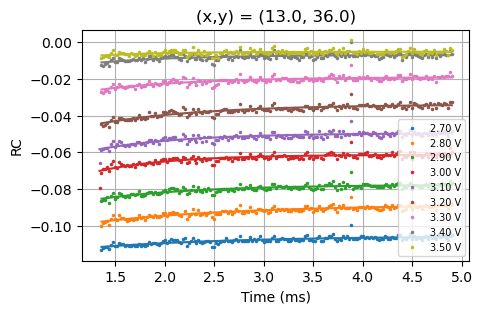

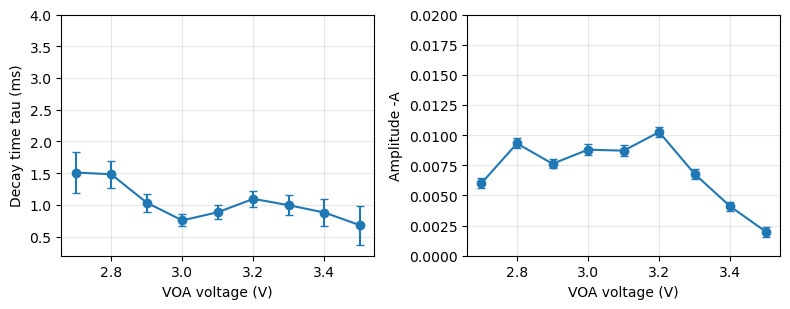

[19, 20, 21, 22, 23, 24, 25, 26, 27]


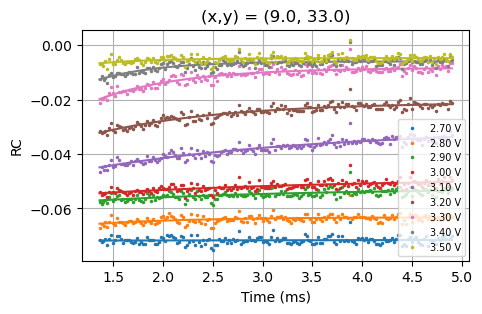

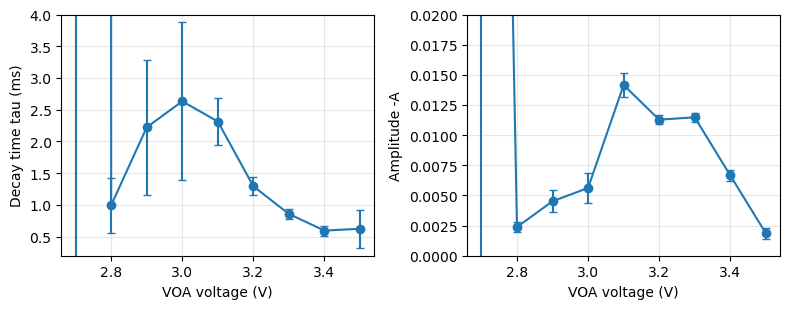

[28, 29, 30, 31, 32, 33, 34, 35, 36]


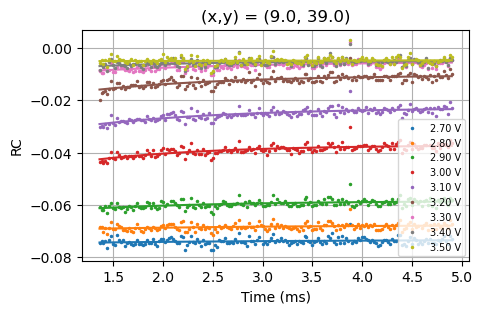

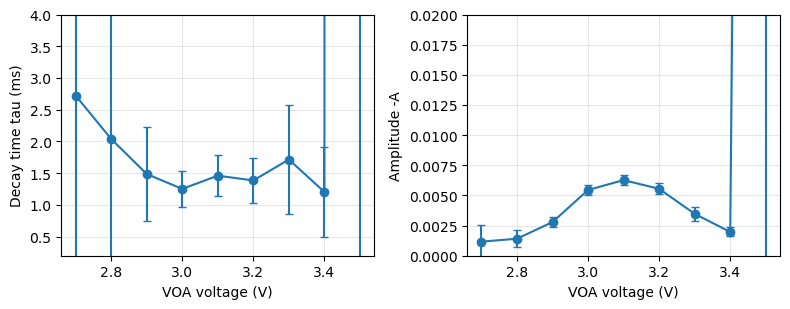

[37, 38, 39, 40, 41, 42, 43, 44]


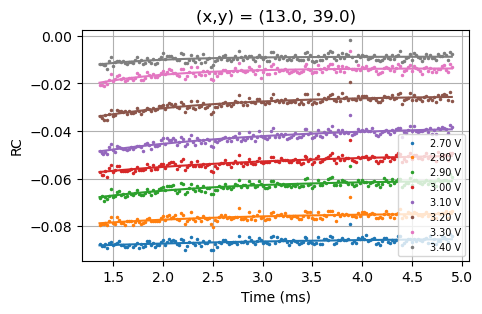

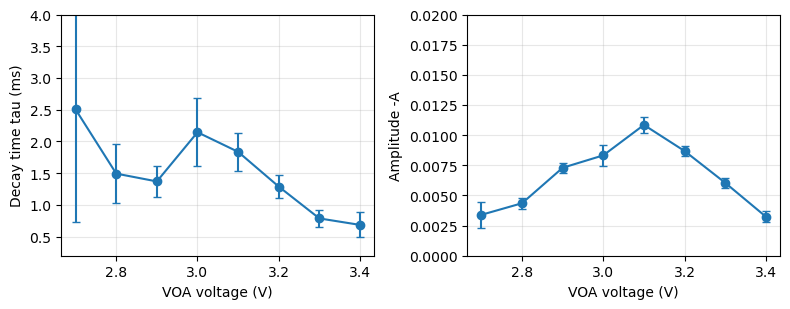

In [35]:
from scipy.optimize import curve_fit

def exp_decay(t, y0, A, tau):
    t0 = np.nanmin(t)
    return y0 + A * np.exp(-(t - t0) / tau)


x_pos = np.array([7, 13, 9, 9, 13])
y_pos = np.array([36, 36, 33, 39, 39])

DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260706_vortex_two_excitation_SM_3_overnight_spatial_scan")
for xs, ys in zip(x_pos, y_pos):
    fits_dict = {}

    acqs = matching_acqs_by_parameters(
        metadata_filters={
            "metadata.description": (
                r"Vortex two-excitation test measurement, short time delays, intermediate powers, SM, "
                "ax1 = %.1f, ax2 = %.1f" % (xs, ys)
            )
        },
        data_root=DATA_ROOT,
        require_raw=False,
        require_analysis=True,
    )
    print(acqs)

    fig_corr, ax_corr = plt.subplots(figsize=(5, 3))

    for sig_acq in acqs:
        entries = get_metadata_entries(
            [sig_acq],
            keys=["voa_requested_initial_voltage","metadata.description"],
            data_root=DATA_ROOT,
        )

        cache_dir = DATA_ROOT / f"acq_{sig_acq}_pump_probe_folded"
        out_path = cache_dir / f"acq_{sig_acq}_corrected_by_acq_{REF_ACQ}_bin20us_metadata_windows.npz"

        z = np.load(out_path)
        t_all = z["time_ms"]
        y_all = z["corrected"]

        mask = (
            (t_all > 1.34)
            & (t_all < 4.9)
            & np.isfinite(t_all)
            & np.isfinite(y_all)
        )
        t = t_all[mask]
        y = y_all[mask]

        y0_guess = np.nanmean(y[-max(3, len(y)//10):])
        A_guess = y[0] - y0_guess
        tau_guess = 1.0

        try:
            popt, pcov = curve_fit(
                exp_decay,
                t,
                y,
                p0=[y0_guess, A_guess, tau_guess],
                bounds=([-np.inf, -np.inf, 1e-6], [np.inf, np.inf, np.inf]),
                maxfev=10000,
            )
        except Exception as exc:
            print(f"Fit failed for acq {sig_acq}: {exc}")
            continue

        y0_fit, A_fit, tau_fit = popt
        voa = float(entries[0]["voa_requested_initial_voltage"])

        perr = np.sqrt(np.diag(pcov))
        y0_err, A_err, tau_err = perr

        fits_dict[sig_acq] = {
            "acq": int(sig_acq),
            "x": float(xs),
            "y": float(ys),
            "voa": voa,
            "description": entries[0]["metadata.description"],
            "popt": popt,
            "pcov": pcov,
            "y0": y0_fit,
            "A": A_fit,
            "tau": tau_fit,
            "y0_err": y0_err,
            "A_err": A_err,
            "tau_err": tau_err,
        }
        label = f'{entries[0]["voa_requested_initial_voltage"]:.2f} V'
        data_scat = ax_corr.plot(t, y, ".", ms=3, label=f"{label}")

        t_fit = np.linspace(np.nanmin(t), np.nanmax(t), 500)
        ax_corr.plot(
            t_fit,
            exp_decay(t_fit, *popt),
            "-",
            label=None,#f"{label}",#: tau={tau_fit:.2f} ms",
            color= data_scat[0].get_color()
        )
        # ax_corr.set_ylim(-0.07,-0.062)

    plt.title("(x,y) = (%.1f, %.1f)" % (xs, ys))
    ax_corr.set_xlabel("Time (ms)")
    ax_corr.set_ylabel("RC")
    ax_corr.grid()
    ax_corr.legend(fontsize=7, loc="lower right")

    fit_rows = sorted(fits_dict.values(), key=lambda d: d["voa"])

    voa = np.array([d["voa"] for d in fit_rows])
    tau = np.array([d["tau"] for d in fit_rows])
    tau_err = np.array([d["tau_err"] for d in fit_rows])
    amp = np.array([d["A"] for d in fit_rows])
    amp_err = np.array([d["A_err"] for d in fit_rows])

    fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))

    axes[0].errorbar(voa, tau, yerr=tau_err, fmt="o-", capsize=3)
    axes[0].set_xlabel("VOA voltage (V)")
    axes[0].set_ylabel("Decay time tau (ms)")
    axes[0].grid(alpha=0.3)
    axes[0].set_ylim(0.2, 4)

    axes[1].errorbar(voa, -amp, yerr=amp_err, fmt="o-", capsize=3)
    axes[1].set_xlabel("VOA voltage (V)")
    axes[1].set_ylabel("Amplitude -A")
    axes[1].grid(alpha=0.3)
    axes[1].set_ylim(0,0.02)

    plt.tight_layout()
    plt.show()

# Longer time delays

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


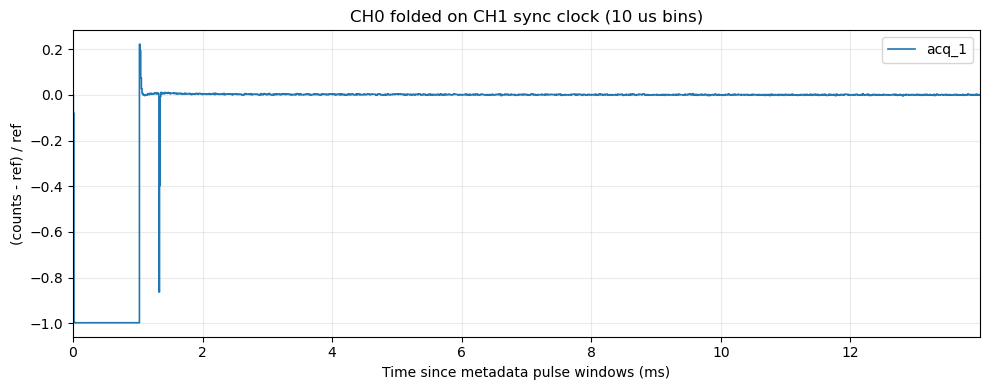

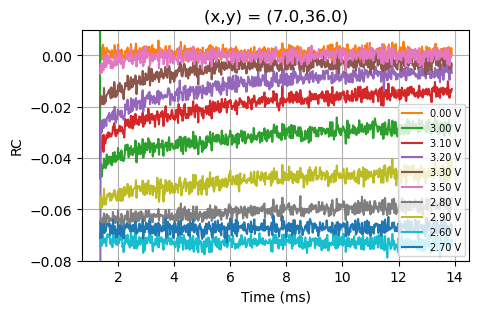

In [87]:
x_pos = np.array([7]) #by default 11
y_pos = np.array([36]) #by default 36

DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260707_vortex_two_excitation_SM_longer_delays_X7_y36")
#DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260707_vortex_two_excitation_SM_50ms_X7_y36")


for xs,ys in zip(x_pos, y_pos):
    acqs = matching_acqs_by_parameters(
        metadata_filters={
             "metadata.description": r"Vortex two-excitation test measurement, short time delays, intermediate powers, SM, ax1 = %.1f, ax2 = %.1f"%(xs,ys)
        },
        data_root=DATA_ROOT,
        require_raw=False,
        require_analysis=True,
    )
    print(acqs)
    
    REF_ACQ = 1
    fig_ref, ax_ref, ref_traces = plot_sync_traces(
        [REF_ACQ],
        sync_tick_stride=100,
        bin_us=10,
        t0_method="metadata_windows",
        unit="ms",
        data_root=DATA_ROOT,
        y_mode="self_normalized",
        ref_range=[13.88, 13.91],
        #ref_range=[49.88, 49.91],
        save_fig=True,
        force_recompute=False,
    )

    fixed_ref = ref_traces[0]["plot_y"] + 1
    t_ref = ref_traces[0]["time_us"] / 1e3
    # plt.close(fig_ref)


    fig_corr, ax_corr = plt.subplots(figsize=(5, 3))
    ax_corr.plot([],[] ,label=None)
    for sig_acq in acqs:
        
        fig, ax, traces = plot_sync_traces(
            [sig_acq],
            sync_tick_stride=100,
            bin_us=20,
            t0_method="metadata_windows",
            unit="ms",
            data_root=DATA_ROOT,
            y_mode="self_normalized",
            ref_range=[1.11,1.12],
            #ref_range=[1.2,1.25],#
            save_fig=True,
            force_recompute=False,
            legend_metadata={
                # "buffer": {"key": "pulse_parameters.buffer", "unit": "s", "fmt": ".3e"},
                # r"$V_\mu$": {"key": "metadata.Vmu", "unit": "V", "fmt": ".2f"},
                "VOA": "metadata.voa_requested_initial_voltage",
            },
        )
        plt.close(fig)

        entries = get_metadata_entries(
            [sig_acq],
            keys=["voa_requested_initial_voltage"],
            data_root=DATA_ROOT,
        )

        sig = traces[0]["plot_y"] + 1
        t = traces[0]["time_us"] / 1e3

        ref = np.interp(t, t_ref, fixed_ref)

        valid = np.isfinite(sig) & np.isfinite(ref) & (ref != 0)
        corr = np.full_like(sig, np.nan, dtype=float)
        corr[valid] = sig[valid] / ref[valid]

        ####### SAVE THIS DATA
        cache_dir = DATA_ROOT / f"acq_{sig_acq}_pump_probe_folded"
        out_path = cache_dir / f"acq_{sig_acq}_corrected_by_acq_{REF_ACQ}_bin20us_metadata_windows.npz"

        np.savez_compressed(
            out_path,
            time_ms=t,
            corrected=corr - 1,
            corr_raw=corr,
            signal=sig,
            reference_interp=ref,
            reference_acq=REF_ACQ,
            signal_acq=sig_acq,
            voa_requested_initial_voltage=entries[0]["voa_requested_initial_voltage"],
            x_pos=xs,
            y_pos=ys,
            t0_method="metadata_windows",
            bin_us=20,
            ref_range=np.array([1.2, 1.25]),
        )

        label = f'{entries[0]["voa_requested_initial_voltage"]:.2f} V'
        ax_corr.plot(t[(t>1.34)&(t<13.9)], corr[(t>1.34)&(t<13.9)] - 1, label=label)
        #ax_corr.plot(t[(t>1.34)&(t<49.9)], corr[(t>1.34)&(t<49.9)] - 1, label=label)

    ax_corr.set_ylim(-0.08,0.01)
    plt.title('(x,y) = (%.1f,%.1f)'%(xs,ys))
    # ax_corr.set_xlim(1.3, 5)
    ax_corr.set_xlabel("Time (ms)")
    ax_corr.set_ylabel("RC")
    ax_corr.grid()
    ax_corr.legend(fontsize=7,loc = 'lower right')
    # plt.savefig(r'Q:\MoTe2_PP_local\20260707_vortex_two_excitation_SM_longer_delays_X7_y36\Corrected_LG_dynamics_xs_%.1f_ys_%.1f_init_norm.png'%(xs,ys),dpi=600,facecolor='w')

[ 9 10  7  8  2  3  4  5  6]


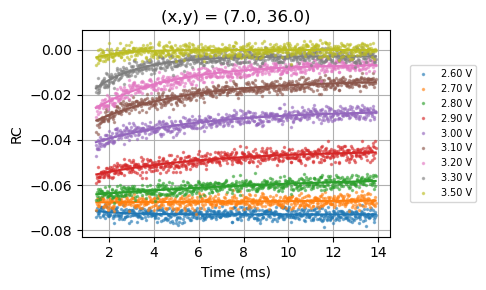

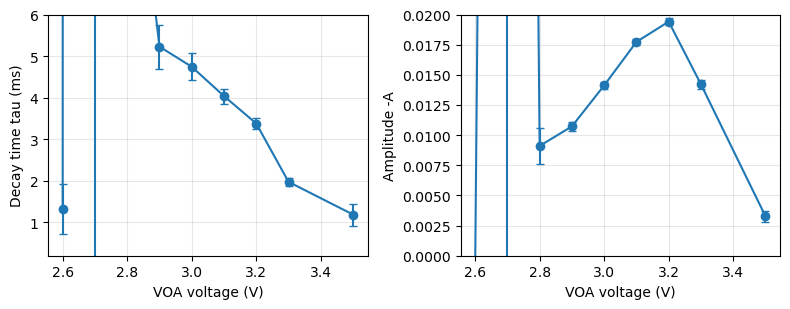

In [94]:
from scipy.optimize import curve_fit

def exp_decay(t, y0, A, tau):
    t0 = np.nanmin(t)
    return y0 + A * np.exp(-(t - t0) / tau)


x_pos = np.array([7])
y_pos = np.array([36])

DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260707_vortex_two_excitation_SM_longer_delays_X7_y36")
for xs, ys in zip(x_pos, y_pos):
    fits_dict = {}

    acqs = matching_acqs_by_parameters(
        metadata_filters={
            "metadata.description": (
                r"Vortex two-excitation test measurement, short time delays, intermediate powers, SM, "
                "ax1 = %.1f, ax2 = %.1f" % (xs, ys)
            )
        },
        data_root=DATA_ROOT,
        require_raw=False,
        require_analysis=True,
    )
    acqs = np.concatenate((np.array([9,10,7,8]),np.arange(2,7)))
    print(acqs)

    fig_corr, ax_corr = plt.subplots(figsize=(5, 3))

    for sig_acq in acqs:
        entries = get_metadata_entries(
            [sig_acq],
            keys=["voa_requested_initial_voltage","metadata.description"],
            data_root=DATA_ROOT,
        )

        cache_dir = DATA_ROOT / f"acq_{sig_acq}_pump_probe_folded"
        out_path = cache_dir / f"acq_{sig_acq}_corrected_by_acq_{REF_ACQ}_bin20us_metadata_windows.npz"

        z = np.load(out_path)
        t_all = z["time_ms"]
        y_all = z["corrected"]

        mask = (
            (t_all > 1.4)
            & (t_all < 13.9)
            & np.isfinite(t_all)
            & np.isfinite(y_all)
        )
        t = t_all[mask]
        y = y_all[mask]

        y0_guess = np.nanmean(y[-max(3, len(y)//10):])
        A_guess = y[0] - y0_guess
        tau_guess = 1.0

        try:
            popt, pcov = curve_fit(
                exp_decay,
                t,
                y,
                p0=[y0_guess, A_guess, tau_guess],
                bounds=([-np.inf, -np.inf, 1e-6], [np.inf, np.inf, np.inf]),
                maxfev=10000,
            )
        except Exception as exc:
            print(f"Fit failed for acq {sig_acq}: {exc}")
            continue

        y0_fit, A_fit, tau_fit = popt
        voa = float(entries[0]["voa_requested_initial_voltage"])

        perr = np.sqrt(np.diag(pcov))
        y0_err, A_err, tau_err = perr

        fits_dict[sig_acq] = {
            "acq": int(sig_acq),
            "x": float(xs),
            "y": float(ys),
            "voa": voa,
            "description": entries[0]["metadata.description"],
            "popt": popt,
            "pcov": pcov,
            "y0": y0_fit,
            "A": A_fit,
            "tau": tau_fit,
            "y0_err": y0_err,
            "A_err": A_err,
            "tau_err": tau_err,
        }
        label = f'{entries[0]["voa_requested_initial_voltage"]:.2f} V'
        data_scat = ax_corr.plot(t, y, ".", ms=3, label=f"{label}",alpha=0.5)

        t_fit = np.linspace(np.nanmin(t), np.nanmax(t), 500)
        ax_corr.plot(
            t_fit,
            exp_decay(t_fit, *popt),
            "-",
            label=None,#f"{label}",#: tau={tau_fit:.2f} ms",
            color= data_scat[0].get_color()
        )
        # ax_corr.set_ylim(-0.07,-0.062)

    plt.title("(x,y) = (%.1f, %.1f)" % (xs, ys))
    ax_corr.set_xlabel("Time (ms)")
    ax_corr.set_ylabel("RC")
    ax_corr.grid()
    
    # Anchor the legend outside the right edge of the plot
    ax_corr.legend(fontsize=7, loc="center left", bbox_to_anchor=(1.05, 0.5))
    
    # Adjust layout so the external legend isn't cut off
    fig_corr.tight_layout()

    fit_rows = sorted(fits_dict.values(), key=lambda d: d["voa"])

    voa = np.array([d["voa"] for d in fit_rows])
    tau = np.array([d["tau"] for d in fit_rows])
    tau_err = np.array([d["tau_err"] for d in fit_rows])
    amp = np.array([d["A"] for d in fit_rows])
    amp_err = np.array([d["A_err"] for d in fit_rows])

    fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))

    axes[0].errorbar(voa, tau, yerr=tau_err, fmt="o-", capsize=3)
    axes[0].set_xlabel("VOA voltage (V)")
    axes[0].set_ylabel("Decay time tau (ms)")
    axes[0].grid(alpha=0.3)
    axes[0].set_ylim(0.2, 6)

    axes[1].errorbar(voa, -amp, yerr=amp_err, fmt="o-", capsize=3)
    axes[1].set_xlabel("VOA voltage (V)")
    axes[1].set_ylabel("Amplitude -A")
    axes[1].grid(alpha=0.3)
    axes[1].set_ylim(0,0.02)

    plt.tight_layout()
    plt.show()

# Magnetic field x power dependence @ Vmu = -3.22 for SP and SM

## SM

In [233]:
(xs,ys) = (9,36)
DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260709_vortex_two_excitation_SM_other_Vmus_test_X%.1f_y%.1f_B_-5mT"%(xs,ys))

Sorted acqs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


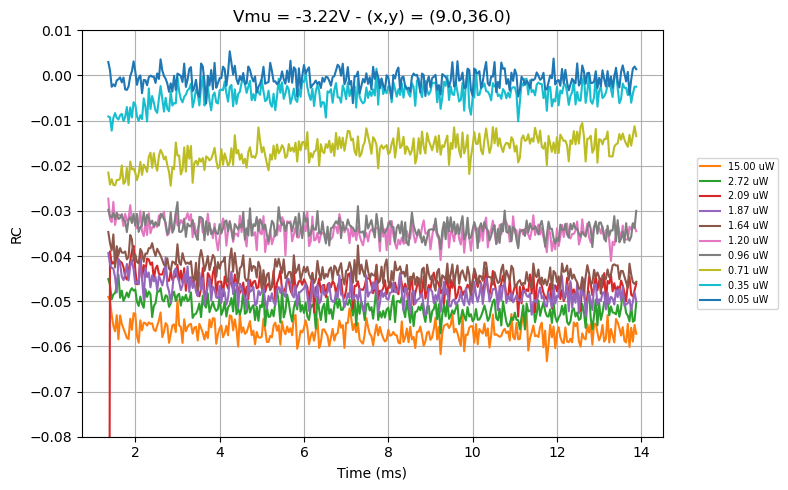

In [234]:


# DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260709_vortex_two_excitation_SM_other_Vmus_test_X%d_y%d"%(xs,ys))


# DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260709_vortex_two_excitation_SM_other_Vmus_test_X%.1f_y%.1f"%(xs,ys))
# DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260709_vortex_two_excitation_SM_other_Vmus_test_X%.1f_y%.1f_B_5mT"%(xs,ys))

# DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260709_vortex_two_excitation_SM_other_Vmus_test_X%.1f_y%.1f_B_3mT"%(xs,ys))


vmus = [-3.22] #np.arange(-3.3,-3.1,0.01)

for vmu in vmus:
    acqs = matching_acqs_by_parameters(
        metadata_filters={
             #"metadata.description": r"Vortex two-excitation test measurement, short time delays, intermediate powers, SM, ax1 = %.1f, ax2 = %.1f"%(xs,ys),
             "metadata.Vmu": vmu
        },
        data_root=DATA_ROOT,
        require_raw=False,
        require_analysis=True,
    )
    
    # --- NEW: Sort acqs by VOA parameter ---
    acq_voa_pairs = []
    for acq in acqs:
        temp_entries = get_metadata_entries(
            [acq],
            keys=["voa_requested_initial_voltage"],
            data_root=DATA_ROOT,
        )
        voa_val = float(temp_entries[0]["voa_requested_initial_voltage"])
        acq_voa_pairs.append((acq, voa_val))
        
    acq_voa_pairs.sort(key=lambda x: x[1], reverse=False)
    acqs = [pair[0] for pair in acq_voa_pairs]
    
    print("Sorted acqs:", acqs)
    
    REF_ACQ = 0
    fig_ref, ax_ref, ref_traces = plot_sync_traces(
        [REF_ACQ],
        sync_tick_stride=100,
        bin_us=10,
        t0_method="metadata_windows",
        unit="ms",
        data_root=DATA_ROOT,
        y_mode="self_normalized",
        ref_range=[1.15, 1.25],
        #ref_range=[49.88, 49.91],
        save_fig=True,
        force_recompute=False,
    )

    fixed_ref = ref_traces[0]["plot_y"] + 1
    t_ref = ref_traces[0]["time_us"] / 1e3
    plt.close(fig_ref)


    fig_corr, ax_corr = plt.subplots(figsize=(8, 5))
    ax_corr.plot([],[] ,label=None)
    for sig_acq in acqs:
        
        fig, ax, traces = plot_sync_traces(
            [sig_acq],
            sync_tick_stride=100,
            bin_us=40,
            t0_method="metadata_windows",
            unit="ms",
            data_root=DATA_ROOT,
            y_mode="self_normalized",
            #ref_range=[1.11,1.12],
            ref_range=[1.15,1.25],#
            save_fig=True,
            force_recompute=False,
            legend_metadata={
                # "buffer": {"key": "pulse_parameters.buffer", "unit": "s", "fmt": ".3e"},
                r"$V_\mu$": {"key": "metadata.Vmu", "unit": "V", "fmt": ".2f"},
                "VOA": "metadata.voa_requested_initial_voltage",
            },
        )
        plt.close(fig)

        entries = get_metadata_entries(
            [sig_acq],
            keys=["voa_requested_initial_voltage","Vmu"],
            data_root=DATA_ROOT,
        )

        sig = traces[0]["plot_y"] + 1
        t = traces[0]["time_us"] / 1e3

        ref = np.interp(t, t_ref, fixed_ref)

        valid = np.isfinite(sig) & np.isfinite(ref) & (ref != 0)
        corr = np.full_like(sig, np.nan, dtype=float)
        corr[valid] = sig[valid] / ref[valid]

        ####### SAVE THIS DATA
        cache_dir = DATA_ROOT / f"acq_{sig_acq}_pump_probe_folded"
        out_path = cache_dir / f"acq_{sig_acq}_corrected_by_acq_{REF_ACQ}_bin20us_metadata_windows.npz"

        np.savez_compressed(
            out_path,
            time_ms=t,
            corrected=corr - 1,
            corr_raw=corr,
            signal=sig,
            reference_interp=ref,
            reference_acq=REF_ACQ,
            signal_acq=sig_acq,
            voa_requested_initial_voltage=entries[0]["voa_requested_initial_voltage"],
            x_pos=xs,
            y_pos=ys,
            t0_method="metadata_windows",
            bin_us=20,
            ref_range=np.array([1.15, 1.25]),
        )

        label = f'{entries[0]["voa_requested_initial_voltage"]:.2f} V, Vmu = {entries[0]["Vmu"]:.2f} V'
        label = f'{voa_erf_transmission_norm(entries[0]["voa_requested_initial_voltage"])*15:.2f} uW'
        
        ax_corr.plot(t[(t>1.34)&(t<13.9)], corr[(t>1.34)&(t<13.9)] - 1, label=label)
        #ax_corr.plot(t[(t>1.34)&(t<49.9)], corr[(t>1.34)&(t<49.9)] - 1, label=label)

    ax_corr.set_ylim(-0.08,0.01)
    plt.title('Vmu = %.2fV - (x,y) = (%.1f,%.1f)'%(vmu,xs,ys))
    # ax_corr.set_xlim(1.3, 5)
    ax_corr.set_xlabel("Time (ms)")
    ax_corr.set_ylabel("RC")
    ax_corr.grid()
    ax_corr.legend(fontsize=7, loc="center left", bbox_to_anchor=(1.05, 0.5))
    fig_corr.tight_layout()
    #plt.savefig(r'%s/Corrected_LG_dynamics_Vmu_%.2fV_xs_%.1f_ys_%.1f_init_norm.png'%(DATA_ROOT,vmu,xs,ys),dpi=600,facecolor='w')

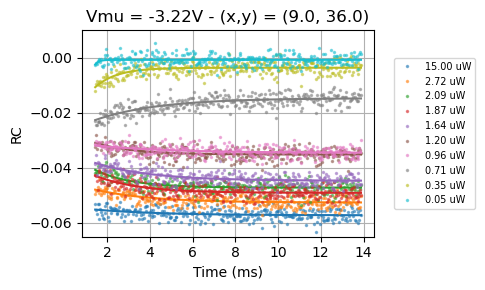

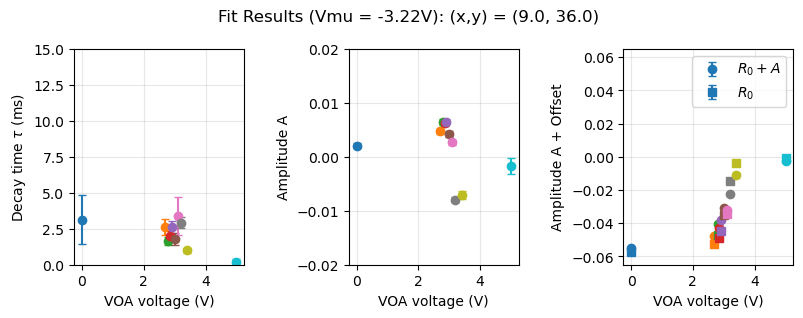

In [ ]:
REF_ACQ = 0

all_fits_results = {}

for vmu in vmus:
    fits_dict = {}
    
    acqs = matching_acqs_by_parameters(
        metadata_filters={
             "metadata.Vmu": vmu,
            #  "metadata.voa_requested_initial_voltage":(0,3.39)
        },
        data_root=DATA_ROOT,
        require_raw=False,
        require_analysis=True,
    )

    # --- Sort acqs by VOA parameter ---
    acq_voa_pairs = []
    for acq in acqs:
        temp_entries = get_metadata_entries(
            [acq],
            keys=["voa_requested_initial_voltage"],
            data_root=DATA_ROOT,
        )
        voa_val = float(temp_entries[0]["voa_requested_initial_voltage"])
        acq_voa_pairs.append((acq, voa_val))
        
    acq_voa_pairs.sort(key=lambda x: x[1], reverse=False)
    acqs = [pair[0] for pair in acq_voa_pairs]

    fig_corr, ax_corr = plt.subplots(figsize=(5, 3))

    for sig_acq in acqs:
        entries = get_metadata_entries(
            [sig_acq],
            keys=["voa_requested_initial_voltage","metadata.description"],
            data_root=DATA_ROOT,
        )

        cache_dir = DATA_ROOT / f"acq_{sig_acq}_pump_probe_folded"
        out_path = cache_dir / f"acq_{sig_acq}_corrected_by_acq_{REF_ACQ}_bin20us_metadata_windows.npz"

        z = np.load(out_path)
        t_all = z["time_ms"]
        y_all = z["corrected"]

        mask = (
            (t_all > 1.4)
            & (t_all < 13.9)
            & np.isfinite(t_all)
            & np.isfinite(y_all)
            & (y_all>-0.2)
            & (y_all<0.02)
        )
        t = t_all[mask]
        y = y_all[mask]

        y0_guess = np.nanmean(y[-max(3, len(y)//10):])
        A_guess = y[0] - y0_guess
        tau_guess = 10

        try:
            popt, pcov = curve_fit(
                exp_decay,
                t,
                y,
                p0=[y0_guess, A_guess, tau_guess],
                bounds=([-0.2,-0.1, 10e-3], [0.01, 0.1, 100]),
                maxfev=10000,
            )
        except Exception as exc:
            print(f"Fit failed for acq {sig_acq}: {exc}")
            continue

        y0_fit, A_fit, tau_fit = popt
        voa = float(entries[0]["voa_requested_initial_voltage"])

        perr = np.sqrt(np.diag(pcov))
        y0_err, A_err, tau_err = perr

        fits_dict[sig_acq] = {
            "acq": int(sig_acq),
            "x": float(xs),
            "y": float(ys),
            "voa": voa,
            "description": entries[0]["metadata.description"],
            "popt": popt,
            "pcov": pcov,
            "y0": y0_fit,
            "A": A_fit,
            "tau": tau_fit,
            "y0_err": y0_err,
            "A_err": A_err,
            "tau_err": tau_err,
        }
        
        label = f'{entries[0]["voa_requested_initial_voltage"]:.2f} V'
        label = f'{voa_erf_transmission_norm(entries[0]["voa_requested_initial_voltage"])*MAX_LG_POWER:.2f} uW'
        data_scat = ax_corr.plot(t, y, ".", ms=3, label=f"{label}", alpha=0.5)

        t_fit = np.linspace(np.nanmin(t), np.nanmax(t), 500)
        ax_corr.plot(
            t_fit,
            exp_decay(t_fit, *popt),
            "-",
            label=None,
            color=data_scat[0].get_color()
        )

    # Finalize and save individual Vmu plot
    plt.title("Vmu = %.2fV - (x,y) = (%.1f, %.1f)" % (vmu, xs, ys))
    ax_corr.set_xlabel("Time (ms)")
    ax_corr.set_ylabel("RC")
    ax_corr.grid()
    ax_corr.set_ylim(-0.065,0.01)
    ax_corr.legend(fontsize=7, loc="center left", bbox_to_anchor=(1.05, 0.5))
    fig_corr.tight_layout()
    plt.savefig(r'%s/Fitted_LG_dynamics_Vmu_%.2fV_xs_%.1f_ys_%.1f_init_norm.png' % (DATA_ROOT, vmu, xs, ys), dpi=600, facecolor='w')
    # plt.close(fig_corr)

    # Save results to global dictionary
    fit_rows = sorted(fits_dict.values(), key=lambda d: d["voa"])
    all_fits_results[vmu] = fit_rows

if len(vmus) == 1:
    fig, axes = plot_single_vmu(all_fits_results, xs, ys, data_root=DATA_ROOT, save_fig=True)
    axes[1].set_ylim(-0.02,0.02)
    axes[2].set_ylim(-0.065,0.065)
elif len(vmus) > 1:
    fig, axes = plot_multi_vmu(all_fits_results, xs, ys, data_root=DATA_ROOT, save_fig=True)
else:
    print("No valid fits were generated. Cannot create summary plots.")


## SP

In [315]:
(xs,ys) = (9,36)
DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260709_vortex_two_excitation_SM_other_Vmus_test_X%.1f_y%.1f_B_5mT"%(xs,ys))


Sorted acqs: [1, 2, 7, 8, 9, 3, 4, 5, 6, 10]


KeyboardInterrupt: 

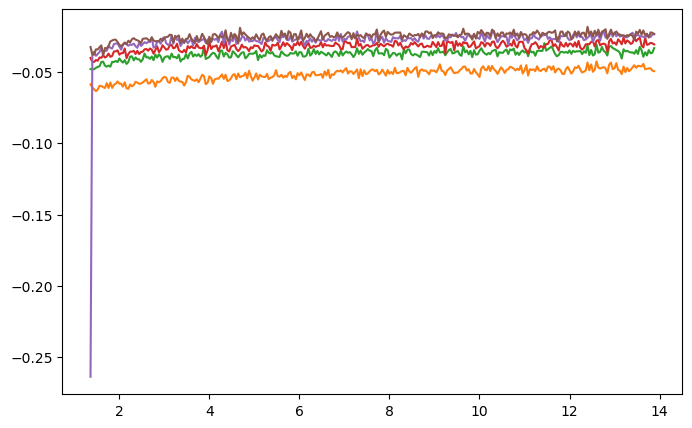

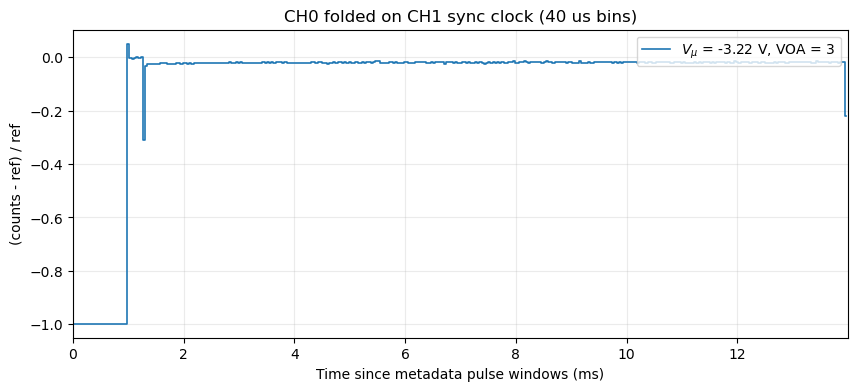

In [319]:
vmus = [-3.22]#[-3.22] 
for vmu in vmus:
    acqs = matching_acqs_by_parameters(
        metadata_filters={
             #"metadata.description": r"Vortex two-excitation test measurement, short time delays, intermediate powers, SM, ax1 = %.1f, ax2 = %.1f"%(xs,ys),
             "metadata.Vmu": vmu,
            #  "metadata.voa_requested_initial_voltage":(3.0,3.24)
        },
        data_root=DATA_ROOT,
        require_raw=False,
        require_analysis=True,
    )
    
    acq_voa_pairs = []
    for acq in acqs:
        temp_entries = get_metadata_entries(
            [acq],
            keys=["voa_requested_initial_voltage"],
            data_root=DATA_ROOT,
        )
        voa_val = float(temp_entries[0]["voa_requested_initial_voltage"])
        acq_voa_pairs.append((acq, voa_val))
        
    acq_voa_pairs.sort(key=lambda x: x[1], reverse=False)
    acqs = [pair[0] for pair in acq_voa_pairs]
    
    print("Sorted acqs:", acqs)
    
    REF_ACQ = 0
    fig_ref, ax_ref, ref_traces = plot_sync_traces(
        [REF_ACQ],
        sync_tick_stride=100,
        bin_us=10,
        t0_method="metadata_windows",
        unit="ms",
        data_root=DATA_ROOT,
        y_mode="self_normalized",
        ref_range=[1.15,1.25],
        #ref_range=[49.88, 49.91],
        save_fig=True,
        force_recompute=False,
    )

    fixed_ref = ref_traces[0]["plot_y"] + 1
    t_ref = ref_traces[0]["time_us"] / 1e3
    plt.close(fig_ref)


    fig_corr, ax_corr = plt.subplots(figsize=(8, 5))
    ax_corr.plot([],[] ,label=None)
    for sig_acq in acqs:
        
        fig, ax, traces = plot_sync_traces(
            [sig_acq],
            sync_tick_stride=100,
            bin_us=40,
            t0_method="metadata_windows",
            unit="ms",
            data_root=DATA_ROOT,
            y_mode="self_normalized",
            #ref_range=[1.11,1.12],
            ref_range=[1.15,1.25],#
            save_fig=True,
            force_recompute=False,
            legend_metadata={
                # "buffer": {"key": "pulse_parameters.buffer", "unit": "s", "fmt": ".3e"},
                r"$V_\mu$": {"key": "metadata.Vmu", "unit": "V", "fmt": ".2f"},
                "VOA": "metadata.voa_requested_initial_voltage",
            },
        )
        plt.close(fig)

        entries = get_metadata_entries(
            [sig_acq],
            keys=["voa_requested_initial_voltage","Vmu"],
            data_root=DATA_ROOT,
        )

        sig = traces[0]["plot_y"] + 1
        t = traces[0]["time_us"] / 1e3

        ref = np.interp(t, t_ref, fixed_ref)

        valid = np.isfinite(sig) & np.isfinite(ref) & (ref != 0)
        corr = np.full_like(sig, np.nan, dtype=float)
        corr[valid] = sig[valid] / ref[valid]

        ####### SAVE THIS DATA
        cache_dir = DATA_ROOT / f"acq_{sig_acq}_pump_probe_folded"
        out_path = cache_dir / f"acq_{sig_acq}_corrected_by_acq_{REF_ACQ}_bin20us_metadata_windows.npz"

        np.savez_compressed(
            out_path,
            time_ms=t,
            corrected=corr - 1,
            corr_raw=corr,
            signal=sig,
            reference_interp=ref,
            reference_acq=REF_ACQ,
            signal_acq=sig_acq,
            voa_requested_initial_voltage=entries[0]["voa_requested_initial_voltage"],
            x_pos=xs,
            y_pos=ys,
            t0_method="metadata_windows",
            bin_us=20,
            ref_range=np.array([1.15, 1.25]),
        )

        label = f'{entries[0]["voa_requested_initial_voltage"]:.2f} V, Vmu = {entries[0]["Vmu"]:.2f} V'
        # label = f'{voa_erf_transmission_norm(entries[0]["voa_requested_initial_voltage"])*15:.2f} uW'

        ax_corr.plot(t[(t>1.34)&(t<13.9)], corr[(t>1.34)&(t<13.9)] - 1, label=label)
        #ax_corr.plot(t[(t>1.34)&(t<49.9)], corr[(t>1.34)&(t<49.9)] - 1, label=label)

    ax_corr.set_ylim(-0.08,0.01)
    plt.title('Vmu = %.2fV - (x,y) = (%.1f,%.1f)'%(vmu,xs,ys))
    # ax_corr.set_xlim(1.3, 5)
    ax_corr.set_xlabel("Time (ms)")
    ax_corr.set_ylabel("RC")
    ax_corr.grid()
    ax_corr.legend(fontsize=9, loc="center left", bbox_to_anchor=(1.05, 0.5))
    fig_corr.tight_layout()
    plt.savefig(r'%s/Corrected_LG_dynamics_Vmu_%.2fV_xs_%.1f_ys_%.1f_init_norm.png'%(DATA_ROOT,vmu,xs,ys),dpi=600,facecolor='w')

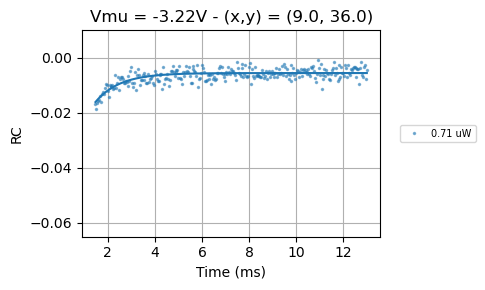

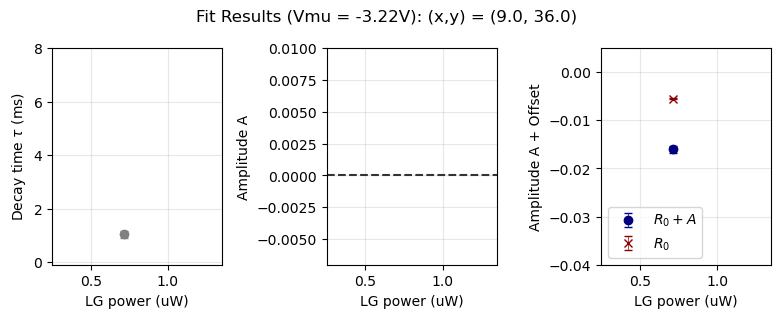

In [ ]:
REF_ACQ = 0

all_fits_results = {}

for vmu in vmus:
    fits_dict = {}
    
    acqs = matching_acqs_by_parameters(
        metadata_filters={
             "metadata.Vmu": vmu,
             "metadata.voa_requested_initial_voltage":3.2

        },
        data_root=DATA_ROOT,
        require_raw=False,
        require_analysis=True,
    )

    # --- Sort acqs by VOA parameter ---
    acq_voa_pairs = []
    for acq in acqs:
        temp_entries = get_metadata_entries(
            [acq],
            keys=["voa_requested_initial_voltage"],
            data_root=DATA_ROOT,
        )
        voa_val = float(temp_entries[0]["voa_requested_initial_voltage"])
        acq_voa_pairs.append((acq, voa_val))
        
    acq_voa_pairs.sort(key=lambda x: x[1], reverse=False)
    acqs = [pair[0] for pair in acq_voa_pairs]

    fig_corr, ax_corr = plt.subplots(figsize=(5, 3))

    for sig_acq in acqs:
        entries = get_metadata_entries(
            [sig_acq],
            keys=["voa_requested_initial_voltage","metadata.description"],
            data_root=DATA_ROOT,
        )

        cache_dir = DATA_ROOT / f"acq_{sig_acq}_pump_probe_folded"
        out_path = cache_dir / f"acq_{sig_acq}_corrected_by_acq_{REF_ACQ}_bin20us_metadata_windows.npz"

        z = np.load(out_path)
        t_all = z["time_ms"]
        y_all = z["corrected"]

        mask = (
            (t_all > 1.45)
            & (t_all < 13)
            & np.isfinite(t_all)
            & np.isfinite(y_all)
            & (y_all>-0.2)
            & (y_all<0.02)
        )
        t = t_all[mask]
        y = y_all[mask]

        y0_guess = np.nanmean(y[-max(3, len(y)//10):])
        A_guess = y[0] - y0_guess
        tau_guess = 1.0

        try:
            popt, pcov = curve_fit(
                exp_decay,
                t,
                y,
                p0=[y0_guess, A_guess, tau_guess],
                bounds=([-np.inf, -np.inf, 1e-6], [np.inf, np.inf, np.inf]),
                maxfev=10000,
            )
        except Exception as exc:
            print(f"Fit failed for acq {sig_acq}: {exc}")
            continue

        y0_fit, A_fit, tau_fit = popt
        voa = float(entries[0]["voa_requested_initial_voltage"])

        perr = np.sqrt(np.diag(pcov))
        y0_err, A_err, tau_err = perr

        fits_dict[sig_acq] = {
            "acq": int(sig_acq),
            "x": float(xs),
            "y": float(ys),
            "voa": voa,
            "description": entries[0]["metadata.description"],
            "popt": popt,
            "pcov": pcov,
            "y0": y0_fit,
            "A": A_fit,
            "tau": tau_fit,
            "y0_err": y0_err,
            "A_err": A_err,
            "tau_err": tau_err,
        }
        
        label = f'{entries[0]["voa_requested_initial_voltage"]:.2f} V'
        label = f'{voa_erf_transmission_norm(entries[0]["voa_requested_initial_voltage"])*MAX_LG_POWER:.2f} uW'
        
        data_scat = ax_corr.plot(t, y, ".", ms=3, label=f"{label}", alpha=0.5)

        t_fit = np.linspace(np.nanmin(t), np.nanmax(t), 500)
        ax_corr.plot(
            t_fit,
            exp_decay(t_fit, *popt),
            "-",
            label=None,
            color=data_scat[0].get_color()
        )

    # Finalize and save individual Vmu plot
    plt.title("Vmu = %.2fV - (x,y) = (%.1f, %.1f)" % (vmu, xs, ys))
    ax_corr.set_xlabel("Time (ms)")
    ax_corr.set_ylabel("RC")
    ax_corr.grid()
    ax_corr.set_ylim(-0.065,0.01)
    ax_corr.legend(fontsize=7, loc="center left", bbox_to_anchor=(1.05, 0.5))
    fig_corr.tight_layout()
    plt.savefig(r'%s/Fitted_LG_dynamics_Vmu_%.2fV_xs_%.1f_ys_%.1f_init_norm.png' % (DATA_ROOT, vmu, xs, ys), dpi=600, facecolor='w')
    # plt.close(fig_corr)

    # Save results to global dictionary
    fit_rows = sorted(fits_dict.values(), key=lambda d: d["voa"])
    all_fits_results[vmu] = fit_rows

if len(vmus) == 1:
    fig, axes = plot_single_vmu(all_fits_results, xs, ys, data_root=DATA_ROOT, save_fig=True)
    axes[0].set_ylim(-0.1,8)
    axes[1].set_ylim(-0.007,0.01)#-0.02,0.02)
    axes[2].set_ylim(-0.04,0.005)#-0.08,0.08)
    # xlims = (2.64,3.47) # VOA lims 
    xlims = (0.25,1.35)

    if xlims is not None:
        axes[0].set_xlim(*xlims)
        axes[1].set_xlim(*xlims)
        axes[2].set_xlim(*xlims)
    axes[1].plot([*xlims],[0,0],'--',color = [0.2,0.2,.2],label=None)
elif len(vmus) > 1:
    fig, axes = plot_multi_vmu(all_fits_results, xs, ys, data_root=DATA_ROOT, save_fig=True)
else:
    print("No valid fits were generated. Cannot create summary plots.")


## Replotting as a funciton of magnetic field

In [200]:
from scipy.optimize import curve_fit
import re

def exp_decay(t, y0, A, tau):
    t0 = np.nanmin(t)
    return y0 + A * np.exp(-(t - t0) / tau)

def B_from_root(path):
    m = re.search(r"_B_([+-]?\d+(?:\.\d+)?)mT", str(path))
    return float(m.group(1)) if m else np.nan


def plot_fixed_voa_vs_B(
    pol="SP",
    voa_target=2.85,
    voa_tol=0.02,
    vmu=-3.22,
    xs=9.0,
    ys=36.0,
    B_values=(-2, 0, 1, 3, 5),
    base=r"Q:\MoTe2_PP_local",
    fit_range=(1.45, 13.0),
    y_range=(-0.08, 0.01),
    REF_ACQ=0,
):
    rows = []

    for B in B_values:
        DATA_ROOT = Path(
            base
            + rf"\20260709_vortex_two_excitation_{pol}_other_Vmus_test_X{xs:.1f}_y{ys:.1f}_B_{B:g}mT"
        )

        acqs = matching_acqs_by_parameters(
            metadata_filters={"metadata.Vmu": vmu},
            data_root=DATA_ROOT,
            require_raw=False,
            require_analysis=True,
        )

        for acq in acqs:
            entries = get_metadata_entries(
                [acq],
                keys=["voa_requested_initial_voltage", "metadata.Vmu"],
                data_root=DATA_ROOT,
            )
            voa = float(entries[0]["voa_requested_initial_voltage"])
            if not np.isclose(voa, voa_target, atol=voa_tol):
                continue

            cache_dir = DATA_ROOT / f"acq_{acq}_pump_probe_folded"
            out_path = cache_dir / f"acq_{acq}_corrected_by_acq_{REF_ACQ}_bin20us_metadata_windows.npz"
            if not out_path.exists():
                print("missing:", out_path)
                continue

            z = np.load(out_path)
            t_all = z["time_ms"]
            y_all = z["corrected"]

            mask = (
                (t_all > fit_range[0])
                & (t_all < fit_range[1])
                & np.isfinite(t_all)
                & np.isfinite(y_all)
                & (y_all > -0.2)
                & (y_all < 0.02)
            )
            t = t_all[mask]
            y = y_all[mask]
            if len(t) < 5:
                continue

            y0_guess = np.nanmean(y[-max(3, len(y)//10):])
            A_guess = y[0] - y0_guess
            tau_guess = 1.0

            try:
                popt, pcov = curve_fit(
                    exp_decay,
                    t,
                    y,
                    p0=[y0_guess, A_guess, tau_guess],
                    bounds=([-np.inf, -np.inf, 1e-6], [np.inf, np.inf, np.inf]),
                    maxfev=10000,
                )
                perr = np.sqrt(np.diag(pcov))
            except Exception as exc:
                print(f"fit failed B={B:g} mT, acq={acq}: {exc}")
                popt = np.array([np.nan, np.nan, np.nan])
                perr = np.array([np.nan, np.nan, np.nan])

            rows.append({
                "B": float(B),
                "acq": int(acq),
                "voa": voa,
                "t": t,
                "y": y,
                "popt": np.array(popt),
                "perr": np.array(perr),
            })

    rows = sorted(rows, key=lambda d: d["B"])

    fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))

    for row in rows:
        Bval = row["B"]
        t = row["t"]
        y = row["y"]
        popt = row["popt"]

        line = axes[0].plot(t, y, ".", ms=3, alpha=0.45, label=f"{Bval:g} mT")[0]
        if np.all(np.isfinite(popt)):
            t_fit = np.linspace(np.nanmin(t), np.nanmax(t), 500)
            axes[0].plot(t_fit, exp_decay(t_fit, *popt), "-", color=line.get_color())

    axes[0].set_title(f"{pol}, VOA = {voa_target:.2f} V, Vmu = {vmu:.2f} V")
    axes[0].set_xlabel("Time (ms)")
    axes[0].set_ylabel("RC")
    axes[0].set_ylim(*y_range)
    axes[0].grid(alpha=0.3)
    axes[0].legend(fontsize=7)

    B = np.array([r["B"] for r in rows])
    y0 = np.array([r["popt"][0] for r in rows])
    amp = np.array([r["popt"][1] for r in rows])
    tau = np.array([r["popt"][2] for r in rows])

    y0_err = np.array([r["perr"][0] for r in rows])
    amp_err = np.array([r["perr"][1] for r in rows])
    tau_err = np.array([r["perr"][2] for r in rows])

    r0_plus_amp = y0 + amp
    r0_plus_amp_err = np.sqrt(y0_err**2 + amp_err**2)

    axes[1].errorbar(B, tau, yerr=tau_err, fmt="o-", capsize=3, label=r"$\tau$")
    ax2 = axes[1].twinx()
    ax2.errorbar(B, amp, yerr=amp_err, fmt="s--", capsize=3, color="C1", label="-A")

    axes[1].set_xlabel("B field (mT)")
    axes[1].set_ylabel(r"$\tau$ (ms)")
    ax2.set_ylabel("-A")
    axes[1].grid(alpha=0.3)

    h1, l1 = axes[1].get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    axes[1].legend(h1 + h2, l1 + l2, fontsize=7, loc="best")

    axes[2].errorbar(B, y0, yerr=y0_err, fmt="o-", capsize=3, label=r"$R_0$")
    axes[2].errorbar(
        B,
        r0_plus_amp,
        yerr=r0_plus_amp_err,
        fmt="s--",
        capsize=3,
        label=r"$R_0 + A$",
    )
    axes[2].axhline(0, color="0.5", lw=1)
    axes[2].set_xlabel("B field (mT)")
    axes[2].set_ylabel("RC level")
    axes[2].grid(alpha=0.3)
    axes[2].legend(fontsize=7, loc="best")

    plt.tight_layout()
    return rows, fig, axes,ax2


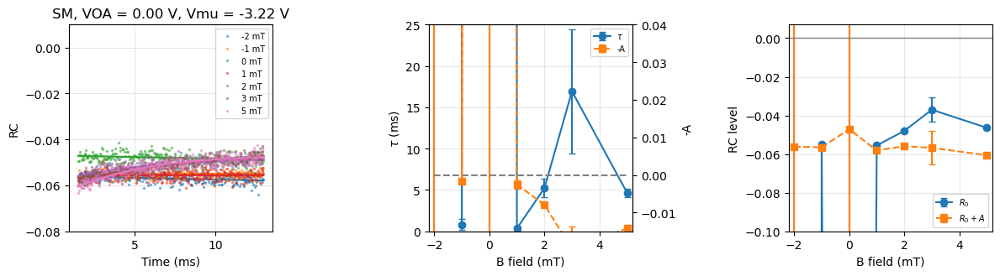

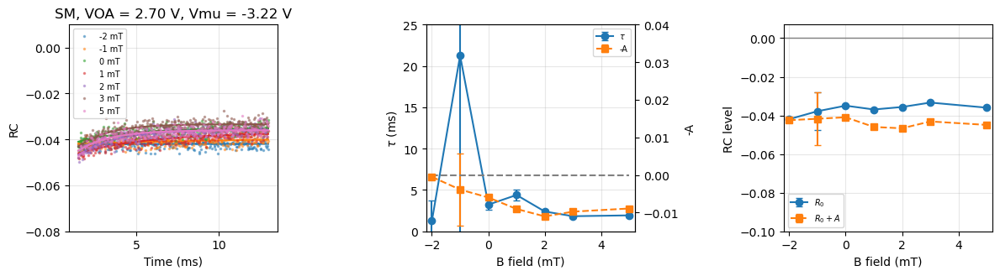

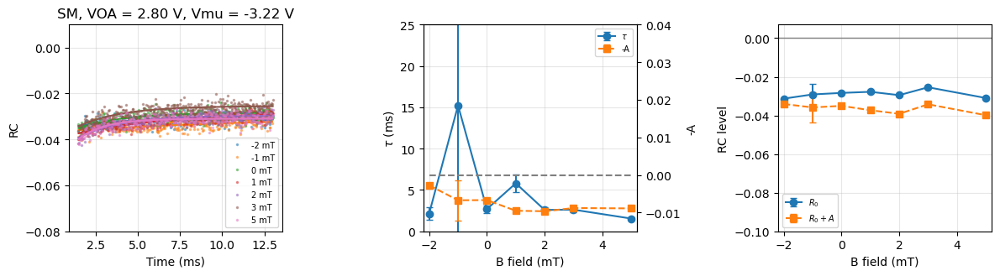

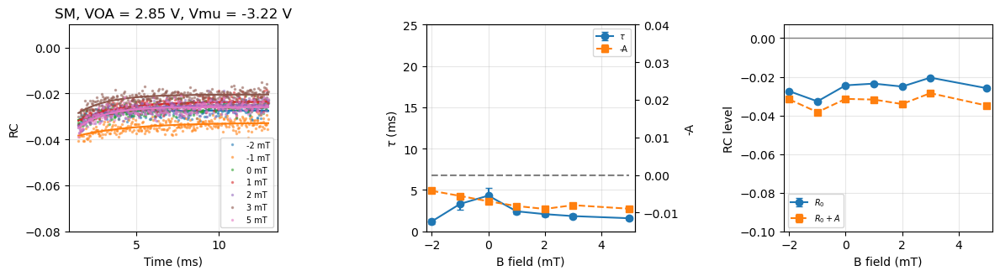

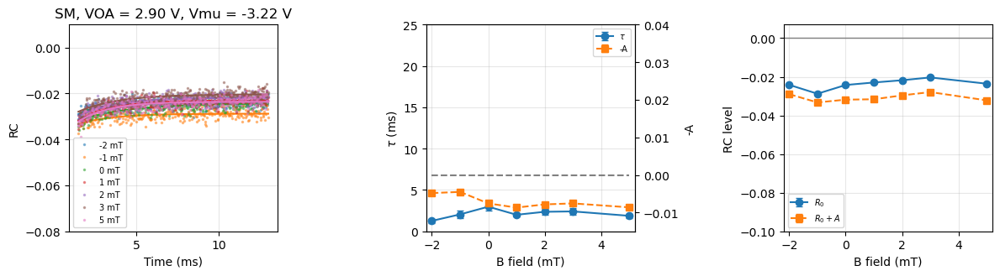

...

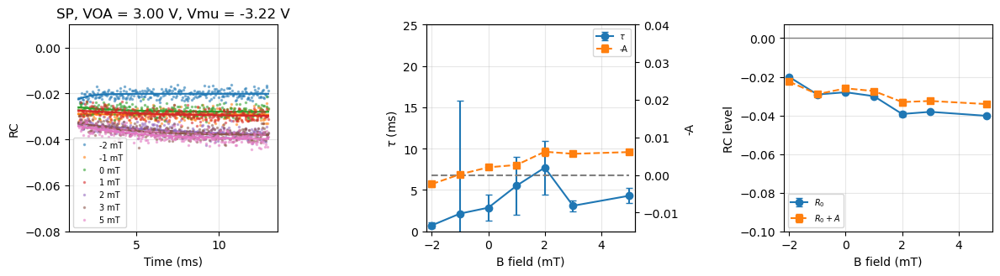

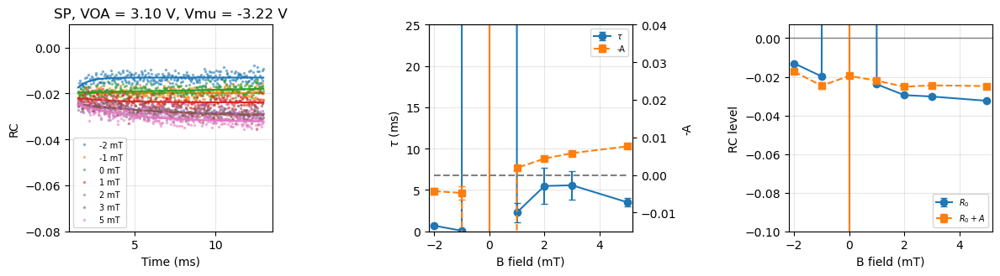

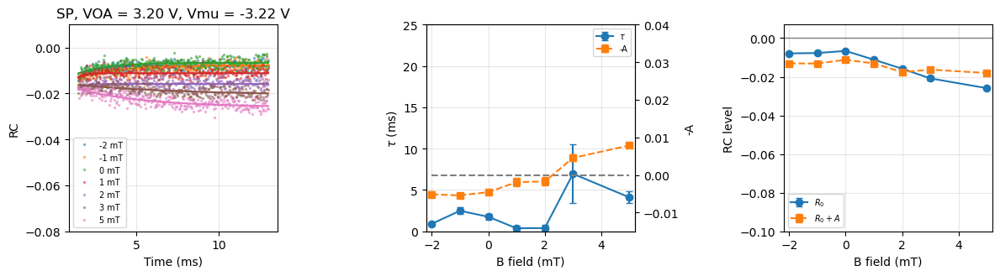

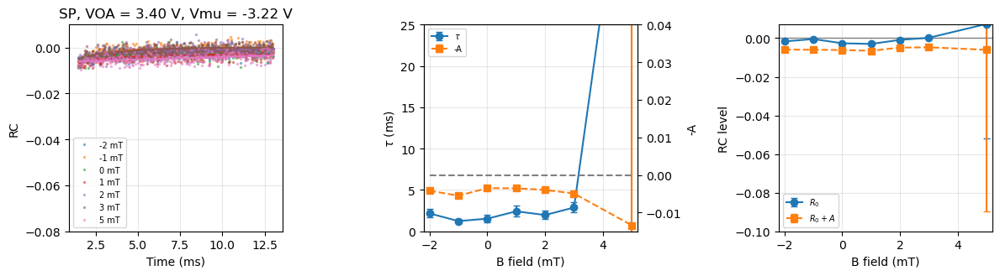

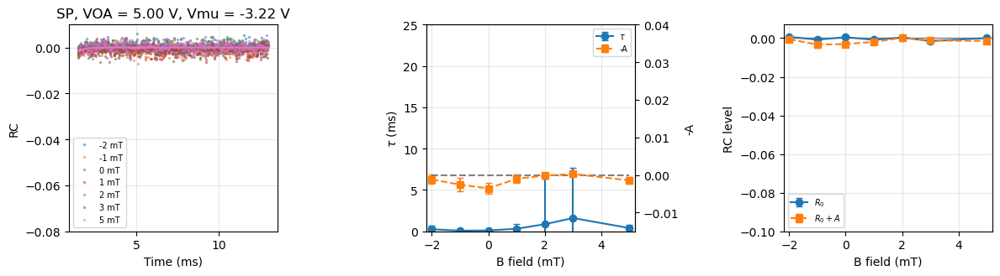

In [236]:

for pol in ["SM","SP"]:
    for voa in [0,2.7,2.8,2.85,2.9,3.0,3.1,3.2,3.4,5]:
    
        rows, fig, axes,ax2 = plot_fixed_voa_vs_B(
            pol=pol,
            voa_target=voa,
            voa_tol=0.01,
            vmu=-3.22,
            xs=9.0,
            ys=36.0,
            B_values=(-2, -1,0, 1,2, 3, 5),
            base=r"Q:\MoTe2_PP_local",
            fit_range=(1.45, 13.0),
            # y_range=(-0.08, 0.01),
        )
        axes[1].set_ylim(0,25)
        axes[1].set_xlim(-2.2,5.2)
        axes[2].set_xlim(-2.2,5.2)
        axes[2].set_ylim(-0.1,0.007)
        ax2.set_ylim(-0.015,0.04)
        ax2.plot([-2,5],[0,0],'--',color='grey',label=None)

# Vmu dependence in SM

Vmu scan acquisitions:
acq    5: Vmu = -3.3000 V, VOA = 3.40 V
acq    6: Vmu = -3.2900 V, VOA = 3.40 V
acq    7: Vmu = -3.2800 V, VOA = 3.40 V
acq    8: Vmu = -3.2700 V, VOA = 3.40 V
acq    9: Vmu = -3.2600 V, VOA = 3.40 V
acq   10: Vmu = -3.2500 V, VOA = 3.40 V
acq   11: Vmu = -3.2400 V, VOA = 3.40 V
acq   12: Vmu = -3.2300 V, VOA = 3.40 V
acq   13: Vmu = -3.2200 V, VOA = 3.40 V
acq   14: Vmu = -3.2100 V, VOA = 3.40 V
acq   15: Vmu = -3.2000 V, VOA = 3.40 V
acq   16: Vmu = -3.1900 V, VOA = 3.40 V
acq   17: Vmu = -3.1800 V, VOA = 3.40 V
acq   18: Vmu = -3.1700 V, VOA = 3.40 V
acq   19: Vmu = -3.1600 V, VOA = 3.40 V
acq   20: Vmu = -3.1500 V, VOA = 3.40 V
acq   21: Vmu = -3.1400 V, VOA = 3.40 V
acq   22: Vmu = -3.1300 V, VOA = 3.40 V
acq   23: Vmu = -3.1200 V, VOA = 3.40 V
acq   24: Vmu = -3.1100 V, VOA = 3.40 V
acq  119: Vmu = -3.1000 V, VOA = 3.40 V
acq  120: Vmu = -3.0900 V, VOA = 3.40 V
acq  121: Vmu = -3.0800 V, VOA = 3.40 V
acq  122: Vmu = -3.0700 V, VOA = 3.40 V


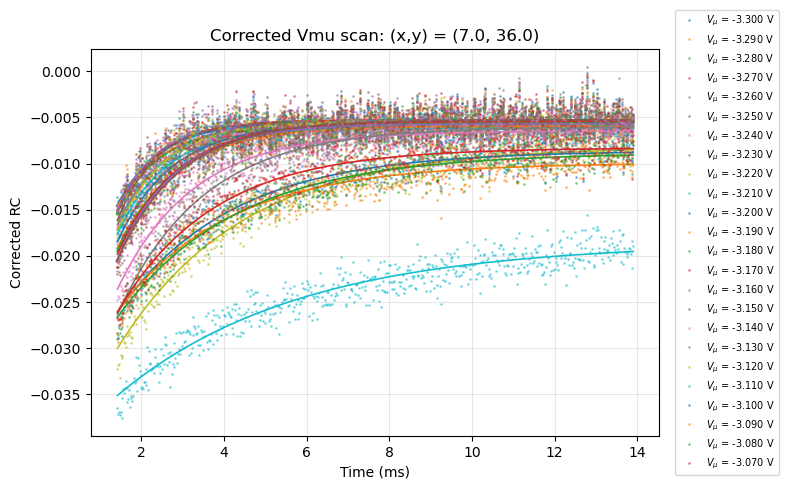

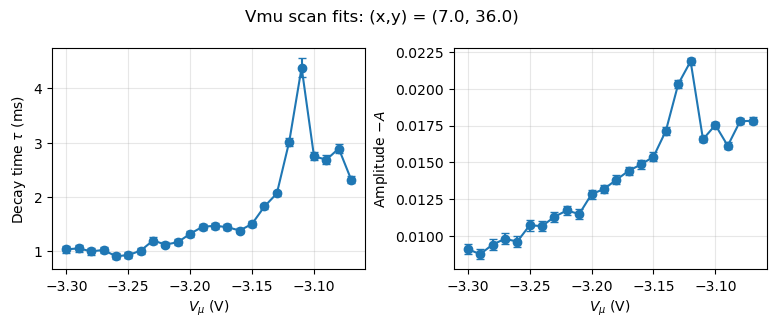

In [164]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


DATA_ROOT = Path(
    r"Q:\MoTe2_PP_local\20260707_vortex_two_excitation_SM_other_Vmus_test_X7_y36"
)

XS = 7
YS = 36
REF_ACQ = 0

BIN_US = 20
FIT_RANGE_MS = (1.4, 13.9)
SIGNAL_REF_RANGE_MS = [1.2, 1.25]
REFERENCE_REF_RANGE_MS = [13.88, 13.91]


def exp_decay(t, y0, A, tau):
    return y0 + A * np.exp(-(t - np.nanmin(t)) / tau)


# Find all acquisitions in the Vmu scan.
acqs = matching_acqs_by_parameters(
    metadata_filters={
        "Vmu":(-3.3, -3.00),
        "voa_requested_initial_voltage":3.4
    },
    data_root=DATA_ROOT,
    require_raw=False,
    require_analysis=True,
)

# Read metadata and sort acquisitions by Vmu.
scan_entries = []

for acq in acqs:
    entries = get_metadata_entries(
        [acq],
        keys=["Vmu", "voa_requested_initial_voltage"],
        data_root=DATA_ROOT,
    )[0]

    try:
        vmu = float(entries["Vmu"])
        voa = float(entries["voa_requested_initial_voltage"])
    except (KeyError, TypeError, ValueError):
        print(f"Skipping acq {acq}: missing Vmu or VOA metadata")
        continue

    scan_entries.append({
        "acq": int(acq),
        "vmu": vmu,
        "voa": voa,
    })

scan_entries.sort(key=lambda d: d["vmu"])

print("Vmu scan acquisitions:")
for row in scan_entries:
    print(
        f"acq {row['acq']:4d}: "
        f"Vmu = {row['vmu']:.4f} V, VOA = {row['voa']:.2f} V"
    )


# Load the fixed reference once.
fig_ref, ax_ref, ref_traces = plot_sync_traces(
    [REF_ACQ],
    sync_tick_stride=100,
    bin_us=10,
    t0_method="metadata_windows",
    unit="ms",
    data_root=DATA_ROOT,
    y_mode="self_normalized",
    ref_range=REFERENCE_REF_RANGE_MS,
    save_fig=True,
    force_recompute=False,
)
plt.close(fig_ref)

fixed_ref = np.asarray(ref_traces[0]["plot_y"], dtype=float) + 1
t_ref = np.asarray(ref_traces[0]["time_us"], dtype=float) / 1e3


# Correct and fit every acquisition.
fit_results = {}

fig_traces, ax_traces = plt.subplots(figsize=(8, 5))

for row in scan_entries:
    sig_acq = row["acq"]
    vmu = row["vmu"]
    voa = row["voa"]

    fig_tmp, ax_tmp, traces = plot_sync_traces(
        [sig_acq],
        sync_tick_stride=100,
        bin_us=BIN_US,
        t0_method="metadata_windows",
        unit="ms",
        data_root=DATA_ROOT,
        y_mode="self_normalized",
        ref_range=SIGNAL_REF_RANGE_MS,
        save_fig=True,
        force_recompute=False,
    )
    plt.close(fig_tmp)

    sig = np.asarray(traces[0]["plot_y"], dtype=float) + 1
    t = np.asarray(traces[0]["time_us"], dtype=float) / 1e3

    ref = np.interp(t, t_ref, fixed_ref)

    valid = np.isfinite(t) & np.isfinite(sig) & np.isfinite(ref) & (ref != 0)

    corrected = np.full(sig.shape, np.nan, dtype=float)
    corrected[valid] = sig[valid] / ref[valid] - 1

    # Save exactly the corrected data that will be fitted below.
    cache_dir = DATA_ROOT / f"acq_{sig_acq}_pump_probe_folded"
    cache_dir.mkdir(exist_ok=True)

    out_path = (
        cache_dir
        / f"acq_{sig_acq}_corrected_by_acq_{REF_ACQ}"
          f"_bin{BIN_US}us_metadata_windows.npz"
    )

    np.savez_compressed(
        out_path,
        time_ms=t,
        corrected=corrected,
        signal=sig,
        reference_interp=ref,
        reference_acq=REF_ACQ,
        signal_acq=sig_acq,
        Vmu=vmu,
        voa_requested_initial_voltage=voa,
        x_pos=XS,
        y_pos=YS,
        t0_method="metadata_windows",
        bin_us=BIN_US,
        signal_ref_range=np.asarray(SIGNAL_REF_RANGE_MS),
        reference_ref_range=np.asarray(REFERENCE_REF_RANGE_MS),
    )

    fit_mask = (
        (t > FIT_RANGE_MS[0])
        & (t < FIT_RANGE_MS[1])
        & np.isfinite(corrected)
    )

    t_fit_data = t[fit_mask]
    y_fit_data = corrected[fit_mask]

    if t_fit_data.size < 4:
        print(f"Skipping acq {sig_acq}: insufficient valid fit data")
        continue

    n_tail = max(3, t_fit_data.size // 10)
    y0_guess = np.nanmean(y_fit_data[-n_tail:])
    A_guess = y_fit_data[0] - y0_guess
    tau_guess = 1.0

    try:
        popt, pcov = curve_fit(
            exp_decay,
            t_fit_data,
            y_fit_data,
            p0=[y0_guess, A_guess, tau_guess],
            bounds=(
                [-np.inf, -np.inf, 1e-6],
                [np.inf, np.inf, np.inf],
            ),
            maxfev=10000,
        )
    except Exception as exc:
        print(f"Fit failed for acq {sig_acq}: {exc}")
        continue

    y0_fit, A_fit, tau_fit = popt
    perr = np.sqrt(np.diag(pcov))
    y0_err, A_err, tau_err = perr

    fit_results[sig_acq] = {
        "acq": sig_acq,
        "vmu": vmu,
        "voa": voa,
        "y0": y0_fit,
        "A": A_fit,
        "tau": tau_fit,
        "y0_err": y0_err,
        "A_err": A_err,
        "tau_err": tau_err,
        "popt": popt,
        "pcov": pcov,
        "cache_path": out_path,
    }

    points, = ax_traces.plot(
        t_fit_data,
        y_fit_data,
        ".",
        ms=2,
        alpha=0.45,
        label=rf"$V_\mu$ = {vmu:.3f} V",
    )

    dense_t = np.linspace(t_fit_data.min(), t_fit_data.max(), 500)
    ax_traces.plot(
        dense_t,
        exp_decay(dense_t, *popt),
        color=points.get_color(),
        lw=1.2,
    )


ax_traces.set_xlabel("Time (ms)")
ax_traces.set_ylabel("Corrected RC")
ax_traces.set_title(
    f"Corrected Vmu scan: (x,y) = ({XS:.1f}, {YS:.1f})"
)
ax_traces.grid(alpha=0.3)
ax_traces.legend(
    fontsize=7,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
)
fig_traces.tight_layout()


# Plot fitted parameters versus Vmu.
fit_rows = sorted(fit_results.values(), key=lambda d: d["vmu"])

vmu_values = np.array([d["vmu"] for d in fit_rows])
tau_values = np.array([d["tau"] for d in fit_rows])
tau_errors = np.array([d["tau_err"] for d in fit_rows])
amp_values = np.array([d["A"] for d in fit_rows])
amp_errors = np.array([d["A_err"] for d in fit_rows])

fig_fit, axes = plt.subplots(1, 2, figsize=(8, 3.3))

axes[0].errorbar(
    vmu_values,
    tau_values,
    yerr=tau_errors,
    fmt="o-",
    capsize=3,
)
axes[0].set_xlabel(r"$V_\mu$ (V)")
axes[0].set_ylabel(r"Decay time $\tau$ (ms)")
axes[0].grid(alpha=0.3)

axes[1].errorbar(
    vmu_values,
    -amp_values,
    yerr=amp_errors,
    fmt="o-",
    capsize=3,
)
axes[1].set_xlabel(r"$V_\mu$ (V)")
axes[1].set_ylabel(r"Amplitude $-A$")
axes[1].grid(alpha=0.3)

fig_fit.suptitle(
    f"Vmu scan fits: (x,y) = ({XS:.1f}, {YS:.1f})"
)
fig_fit.tight_layout()
plt.show()

# Single shot msmt attempts

## Analysis function

In [112]:
def single_shot_CR(
    DATA_ROOT,
    acq=3,
    *,
    t0=1.4,
    period=1.0,
    bin_s=None,
    channels=(0,),
    init_offset=0.0,
    init_width=0.2,
    switch_offset=0.5,
    switch_width=0.2,
    N_start=30,
    N_stop=None,
    xlim=(30, 50),
    hist_bins=15,
    force_recompute=False,
    show_progress=True,
):
    DATA_ROOT = Path(DATA_ROOT)
    if bin_s is None:
        bin_s = period / 20

    fig_tmp, ax_tmp, rate_data = plot_count_rate_over_time(
        [acq],
        data_root=DATA_ROOT,
        bin_s=bin_s,
        channels=channels,
        force_recompute=force_recompute,
        show_progress=show_progress,
        save_fig=False,
    )
    plt.close(fig_tmp)

    t = rate_data["time_s"]
    rate = rate_data["rate_kcps"]

    if N_stop is None:
        N_stop = int(np.nanmax(t) / period - 1)

    Ns = []
    init_means = []
    switch_means = []
    contrasts = []
    init_windows = []
    switch_windows = []

    for N in np.arange(N_start, N_stop).astype(int):
        init_window = [
            t0 + init_offset + N * period,
            t0 + init_offset + init_width + N * period,
        ]
        switch_window = [
            t0 + switch_offset + N * period,
            t0 + switch_offset + switch_width + N * period,
        ]

        init_mask = (
            (t >= init_window[0])
            & (t <= init_window[1])
            & np.isfinite(t)
            & np.isfinite(rate)
        )
        switch_mask = (
            (t >= switch_window[0])
            & (t <= switch_window[1])
            & np.isfinite(t)
            & np.isfinite(rate)
        )

        if not np.any(init_mask) or not np.any(switch_mask):
            continue

        init_mean = np.nanmean(rate[init_mask])
        switch_mean = np.nanmean(rate[switch_mask])

        if not np.isfinite(init_mean) or init_mean == 0:
            contrast = np.nan
        else:
            contrast = (switch_mean - init_mean) / init_mean

        Ns.append(N)
        init_means.append(init_mean)
        switch_means.append(switch_mean)
        contrasts.append(contrast)
        init_windows.append(init_window)
        switch_windows.append(switch_window)

    Ns = np.array(Ns)
    init_means = np.array(init_means)
    switch_means = np.array(switch_means)
    contrasts = np.array(contrasts)
    init_windows = np.array(init_windows)
    switch_windows = np.array(switch_windows)

    fig_summary = plt.figure(figsize=(8, 7))
    gs = fig_summary.add_gridspec(
        3, 2,
        width_ratios=[4, 1.2],
        height_ratios=[1.2, 1, 1],
        wspace=0.08,
        hspace=0.08,
    )

    ax_rate_raw = fig_summary.add_subplot(gs[0, 0])
    ax_rate = fig_summary.add_subplot(gs[1, 0], sharex=ax_rate_raw)
    ax_contrast = fig_summary.add_subplot(gs[2, 0], sharex=ax_rate_raw)
    ax_hist = fig_summary.add_subplot(gs[2, 1], sharey=ax_contrast)

    ax_rate_raw.plot(t, rate, lw=0.2, color="black")


    x0, x1 = xlim if xlim is not None else (np.nanmin(t), np.nanmax(t))

    init_label_used = False
    switch_label_used = False

    for init_window, switch_window in zip(init_windows, switch_windows):
        if init_window[1] >= x0 and init_window[0] <= x1:
            ax_rate_raw.axvspan(
                init_window[0],
                init_window[1],
                alpha=0.1,
                color="blue",
                label="init" if not init_label_used else "_nolegend_",
            )
            init_label_used = True

        if switch_window[1] >= x0 and switch_window[0] <= x1:
            ax_rate_raw.axvspan(
                switch_window[0],
                switch_window[1],
                alpha=0.1,
                color="red",
                label="switch" if not switch_label_used else "_nolegend_",
            )
            switch_label_used = True

    ax_rate_raw.legend()
    ax_rate_raw.set_ylabel("CH0 rate (kcps)")
    ax_rate_raw.grid(alpha=0.3)
    if xlim is not None:
        ax_rate_raw.set_xlim(*xlim)
    plt.setp(ax_rate_raw.get_xticklabels(), visible=False)

    ax_rate.plot(Ns * period + t0, init_means, "o-", label="init")
    ax_rate.plot(Ns * period + t0, switch_means, "o-", label="switch")
    ax_rate.set_ylabel("Mean rate (kcps)")
    ax_rate.legend()
    ax_rate.grid(alpha=0.3)
    plt.setp(ax_rate.get_xticklabels(), visible=False)

    ax_contrast.plot(
        Ns * period + t0,
        contrasts,
        "o-",
        color="black",
        lw=0.5,
        markersize=1,
    )
    ax_contrast.axhline(0, color="0.5", lw=1)
    ax_contrast.set_xlabel("Measurement time (s)")
    ax_contrast.set_ylabel("(switch - init) / init")
    ax_contrast.grid(alpha=0.3)

    valid_contrasts = contrasts[np.isfinite(contrasts)]
    ax_hist.hist(
        valid_contrasts,
        bins=hist_bins,
        orientation="horizontal",
        color="0.3",
        alpha=0.75,
    )
    ax_hist.axhline(0, color="0.5", lw=1)
    ax_hist.set_xlabel("count")
    ax_hist.grid(alpha=0.2)
    plt.setp(ax_hist.get_yticklabels(), visible=False)



    data = {
        "DATA_ROOT": DATA_ROOT,
        "acq": acq,
        "t0": t0,
        "period": period,
        "bin_s": bin_s,
        "channels": channels,
        "rate_data": rate_data,
        "Ns": Ns,
        "time_s": Ns * period + t0,
        "init_means": init_means,
        "switch_means": switch_means,
        "contrasts": contrasts,
        "init_windows": init_windows,
        "switch_windows": switch_windows,
    }

    figs = {
        "summary": (fig_summary, (ax_rate_raw, ax_rate, ax_contrast, ax_hist)),
    }

    return data, figs

## Analysis of meas

In [ ]:
MAX_LG_POWER = 15 ## REMEASURED AT 1 PM on 10 July

saved Q:\MoTe2_PP_local\20260707_vortex_two_excitation_SM_test_single_shot_X7_y36\acq_65_pump_probe_folded\voa_2.70_t_LG_0.00010s_acq_65_contrast_vs_repetition.npz


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_14036\2802977691.py:81: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig_summary.tight_layout(rect=[0, 0, 1, 0.96])


saved Q:\MoTe2_PP_local\20260707_vortex_two_excitation_SM_test_single_shot_X7_y36\acq_66_pump_probe_folded\voa_2.70_t_LG_0.00020s_acq_66_contrast_vs_repetition.npz
saved Q:\MoTe2_PP_local\20260707_vortex_two_excitation_SM_test_single_shot_X7_y36\acq_67_pump_probe_folded\voa_2.70_t_LG_0.00040s_acq_67_contrast_vs_repetition.npz
saved Q:\MoTe2_PP_local\20260707_vortex_two_excitation_SM_test_single_shot_X7_y36\acq_68_pump_probe_folded\voa_2.70_t_LG_0.00080s_acq_68_contrast_vs_repetition.npz
saved Q:\MoTe2_PP_local\20260707_vortex_two_excitation_SM_test_single_shot_X7_y36\acq_69_pump_probe_folded\voa_2.70_t_LG_0.00160s_acq_69_contrast_vs_repetition.npz
saved Q:\MoTe2_PP_local\20260707_vortex_two_excitation_SM_test_single_shot_X7_y36\acq_70_pump_probe_folded\voa_2.70_t_LG_0.00320s_acq_70_contrast_vs_repetition.npz
saved Q:\MoTe2_PP_local\20260707_vortex_two_excitation_SM_test_single_shot_X7_y36\acq_71_pump_probe_folded\voa_2.70_t_LG_0.00640s_acq_71_contrast_vs_repetition.npz
saved Q:\MoTe2_P

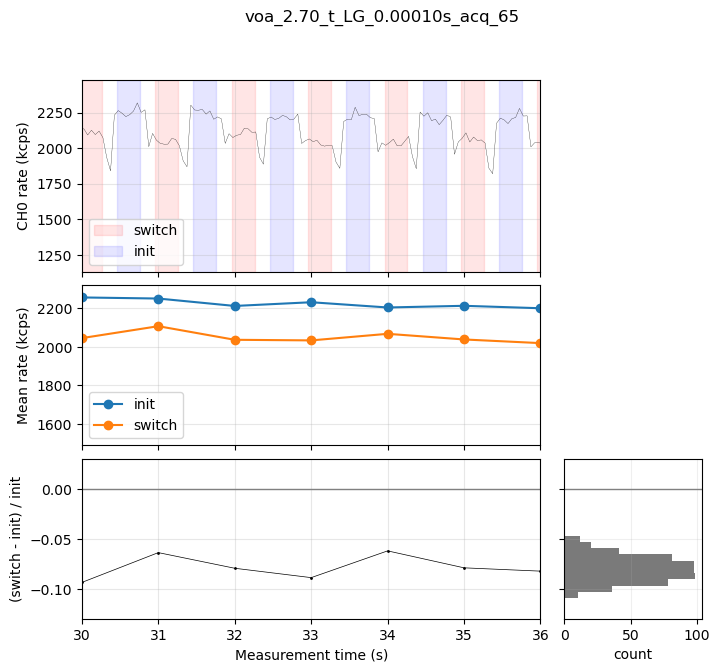

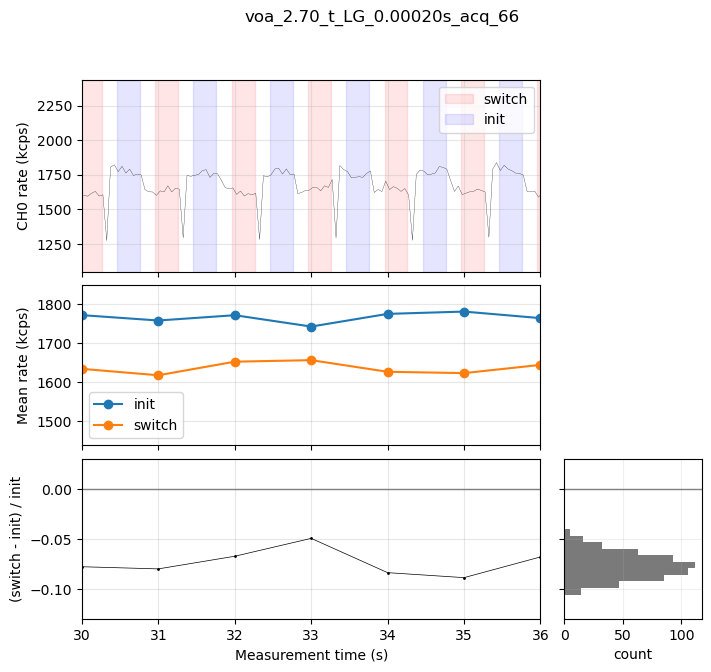

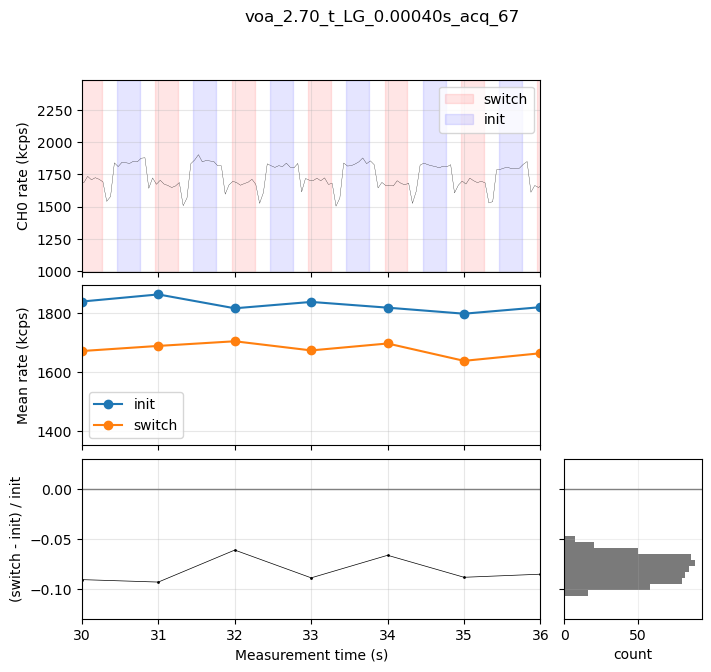

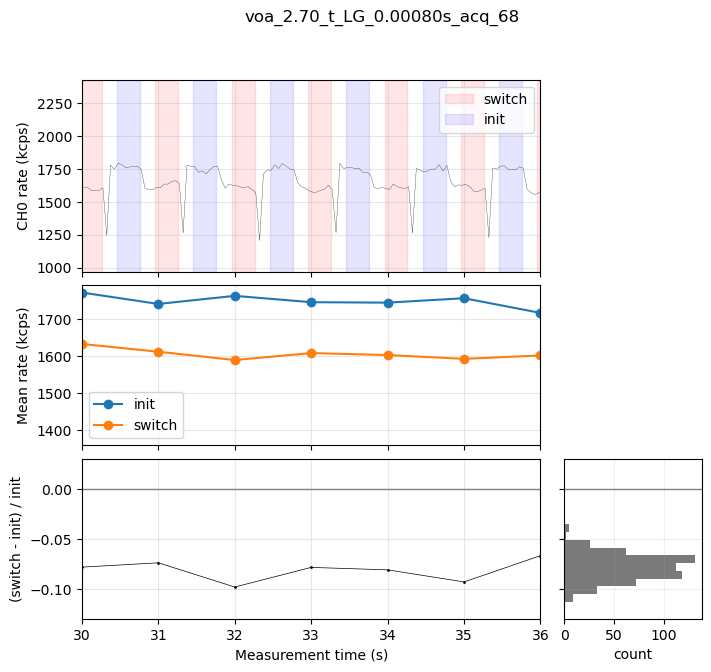

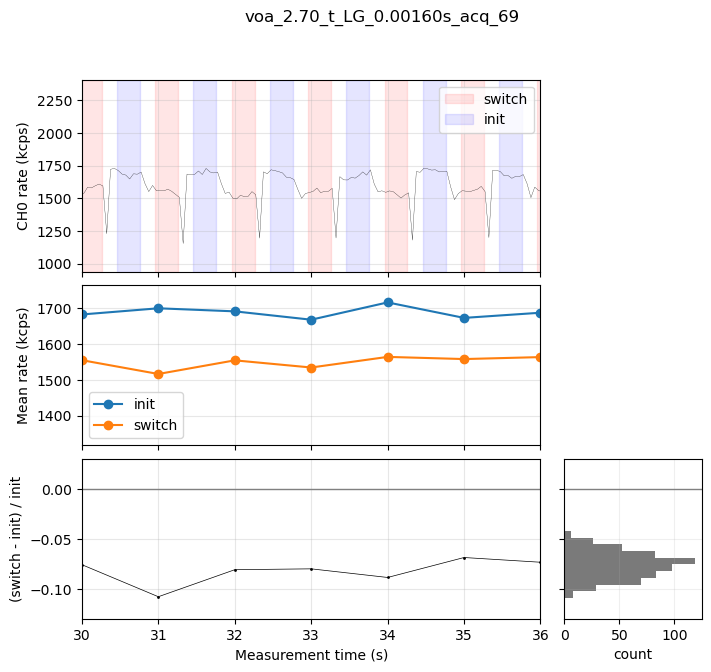

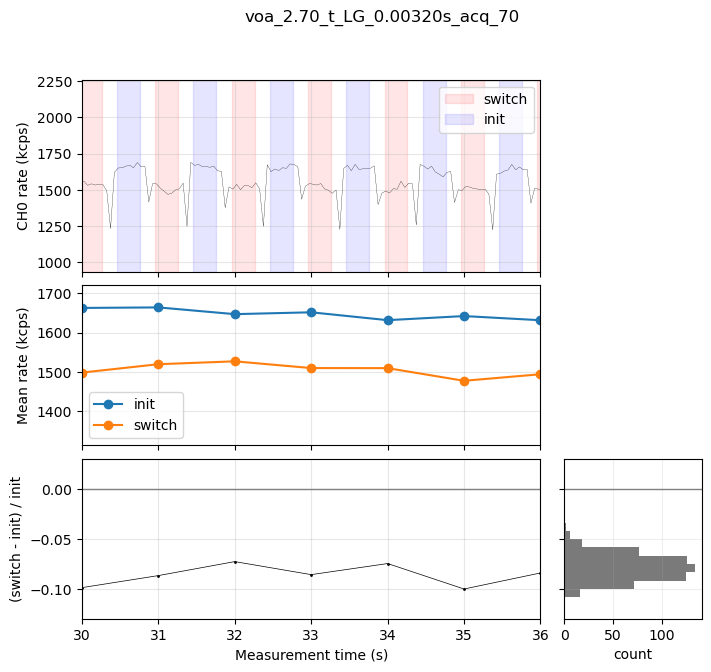

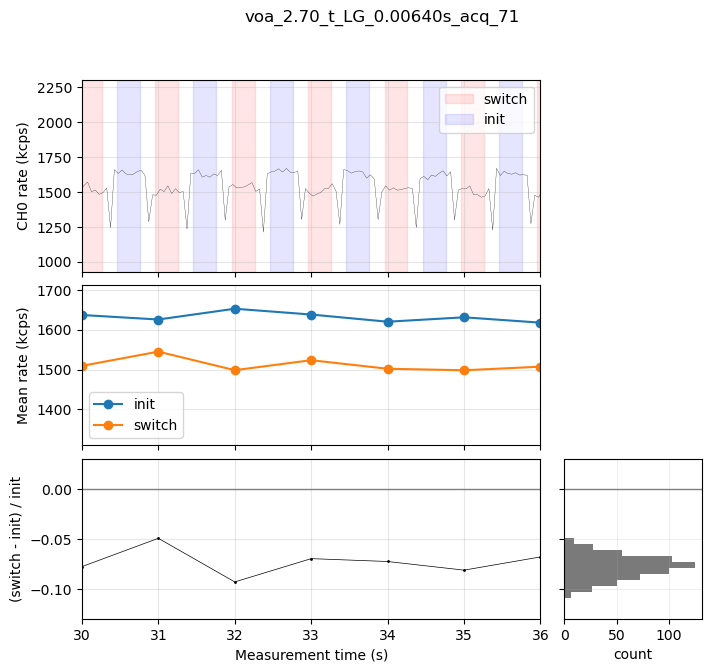

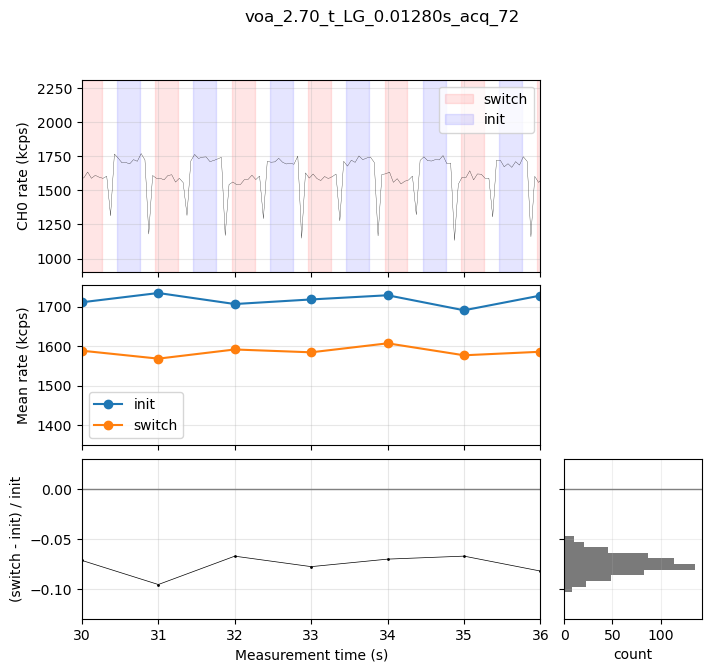

In [143]:
DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260707_vortex_two_excitation_SM_test_single_shot_X7_y36")

# acqs = range(23, 32)  # At VOA 3.5
# acqs = range(32, 41)  # At VOA 3
# acqs = range(41, 50)    # At VOA 3.75
# acqs = [50,51,52]    # At VOA 3.75, long pyulses
acqs = range(53,62)  # At VOA 3.9
acqs = [62,63,64]    # At VOA 3.9, long pyulses
acqs = range(65,73)  # At VOA 2.7



t0s = np.zeros(len(acqs))

for i, acq in enumerate(acqs):
    entries = get_metadata_entries(
        [acq],
        keys=[
            "pulse_parameters.t_x_r1",
            "metadata.voa_requested_initial_voltage",
        ],
        data_root=DATA_ROOT,
    )

    t_x_r1 = entries[0]["pulse_parameters.t_x_r1"]
    voa = entries[0]["metadata.voa_requested_initial_voltage"]

    data, figs = single_shot_CR(
        DATA_ROOT,
        acq=acq,
        t0=t0s[i],
        period=1.0,
        init_width=0.3,
        init_offset=0.46,
        switch_offset=0.96,
        switch_width=0.3,
        # init_width=0.3, ## for the long pulses
        # init_offset=0.46, ## for the long pulses
        # switch_offset=1.15, ## for the long pulses
        # switch_width=0.1, ## for the long pulses
        hist_bins=10,
        bin_s=0.05,
        N_start=25,
        xlim=(30, 36),
        force_recompute=False,
    )

    fig_summary, (ax_rate_raw, ax_rate, ax_contrast, ax_hist) = figs["summary"]

    ax_contrast.set_ylim(-0.13, 0.03)
    ax_hist.set_ylim(-0.13, 0.03)

    cache_dir = DATA_ROOT / f"acq_{acq}_pump_probe_folded"
    cache_dir.mkdir(exist_ok=True)

    title = f"voa_{voa:.2f}_t_LG_{t_x_r1:.5f}s_acq_{acq}"
    contrast_cache_path = cache_dir / f"{title}_contrast_vs_repetition.npz"
    np.savez_compressed(
        contrast_cache_path,
        acq=int(acq),
        voa=float(voa),
        t_x_r1=float(t_x_r1),
        Ns=data["Ns"],
        time_s=data["time_s"],
        init_means=data["init_means"],
        switch_means=data["switch_means"],
        contrasts=data["contrasts"],
        init_windows=data["init_windows"],
        switch_windows=data["switch_windows"],
        t0=float(data["t0"]),
        period=float(data["period"]),
        bin_s=float(data["bin_s"]),
        init_offset=0.46,
        init_width=0.3,
        switch_offset=0.96,
        switch_width=0.3,
    )
    print(f"saved {contrast_cache_path}")

    fig_summary.suptitle(title)
    fig_summary.tight_layout(rect=[0, 0, 1, 0.96])
    fig_summary.savefig(
        DATA_ROOT / f"{title}_contrast_distribution.png",
        dpi=300,
        facecolor="w",
    )
    



using 8 contrast cache files
loaded 8 cached contrast files


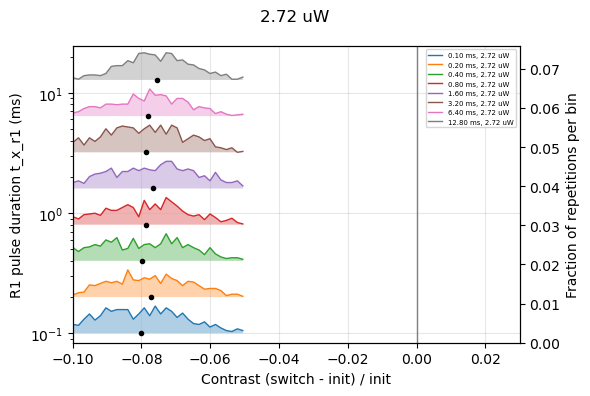

In [144]:
# Load cached contrast-vs-repetition files and plot distributions versus pulse duration.
# all
# acqs = range(65, 73)  # At VOA 2.7
acqs = range(32,41) #voa 3.0
# acqs = range(23,32) #voa 3.5
# acqs = range(41,53) #voa 3.75
acqs = range(53,65) # voa 3.9
acqs = range(65,73) # voa 2.7


contrast_cache_files = []
for acq in acqs:
    cache_dir = DATA_ROOT / f"acq_{acq}_pump_probe_folded"
    matches = sorted(cache_dir.glob("*_contrast_vs_repetition.npz"))
    if len(matches) == 0:
        print(f"missing cache for acq {acq}")
        continue
    contrast_cache_files.append(matches[-1])

print(f"using {len(contrast_cache_files)} contrast cache files")
rows = []
for path in contrast_cache_files:
    z = np.load(path)
    contrasts = z["contrasts"]
    valid = contrasts[np.isfinite(contrasts)]
    if valid.size == 0:
        continue

    rows.append({
        "path": path,
        "acq": int(z["acq"]),
        "voa": float(z["voa"]),
        "t_x_r1": float(z["t_x_r1"]),
        "contrasts": valid,
        "mean": float(np.nanmean(valid)),
        "std": float(np.nanstd(valid)),
    })

rows = sorted(rows, key=lambda d: (d["voa"], d["t_x_r1"], d["acq"]))
print(f"loaded {len(rows)} cached contrast files")

fig, ax = plt.subplots(figsize=(6, 4))

if rows:
    all_contrasts = np.concatenate([r["contrasts"] for r in rows])
    bins = np.linspace(
        np.nanpercentile(all_contrasts, 1),
        np.nanpercentile(all_contrasts, 99),
        35,
    )

    pulse_ms = np.array([r["t_x_r1"] * 1e3 for r in rows])
    positive_pulse_ms = pulse_ms[pulse_ms > 0]
    unique_pulse_ms = np.unique(positive_pulse_ms)

    if unique_pulse_ms.size > 1:
        log_step = np.nanmedian(np.diff(np.log(unique_pulse_ms)))
        log_height = 0.75 * log_step
    else:
        log_height = 0.25

    max_frac = 0.0
    for row in rows:
        y0 = row["t_x_r1"] * 1e3
        if not np.isfinite(y0) or y0 <= 0:
            continue

        counts, edges = np.histogram(row["contrasts"], bins=bins)
        centers = 0.5 * (edges[:-1] + edges[1:])
        frac = counts / counts.sum() if counts.sum() > 0 else counts.astype(float)
        max_frac = max(max_frac, np.nanmax(frac) if frac.size else 0.0)

        # On a log y-axis, a linear-looking histogram height must be a
        # multiplicative offset from the pulse-duration baseline.
        frac_norm = frac / np.nanmax(frac) if np.nanmax(frac) > 0 else frac
        y_hist = y0 * np.exp(log_height * frac_norm)

        ax.fill_between(centers, y0, y_hist, alpha=0.35)
        ax.plot(
            centers,
            y_hist,
            lw=1,
            label=f"{row['t_x_r1']*1e3:.2f} ms, {voa_erf_transmission_norm(row['voa'])*15:.2f} uW",
        )
        ax.plot(row["mean"], y0, "ko", ms=3)
    ax.set_ylim(0.5e-4,1)
    ax.set_xlim(-0.1,0.03)
    ax.set_yscale("log")
    ax.set_ylim(
        np.nanmin(positive_pulse_ms) * np.exp(-0.35 * log_height),
        np.nanmax(positive_pulse_ms) * np.exp(1.25 * log_height),
    )

    # The right axis names the local histogram height. The actual curves are
    # anchored to each pulse-duration baseline on the log-scaled left axis.
    ax_frac = ax.twinx()
    ax_frac.set_ylim(0, max_frac if max_frac > 0 else 1)
    ax_frac.set_ylabel("Fraction of repetitions per bin")
    ax_frac.grid(False)

ax.axvline(0, color="0.5", lw=1)
ax.set_xlabel("Contrast (switch - init) / init")
ax.set_ylabel("R1 pulse duration t_x_r1 (ms)")
ax.grid(alpha=0.3)
ax.legend(fontsize=5, loc="upper right")
fig.suptitle(f"{voa_erf_transmission_norm(row['voa'])*15:.2f} uW")
plt.tight_layout()
plt.savefig(os.path.join(DATA_ROOT,f"pulse_duration_dependence_voa_{row['voa']}.png"),dpi = 300)


# Cursory Vmu scan (9,36) 9-10 July

In [ ]:

#### Long overnight at (9,36)
# DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260710_Vmu_scan_X9_y36")
# xs, ys = 9, 36

# REF_ACQ = 0
# pols = ["SP", "SM"]
# B_targets = [0]#[-2e-3]       # T
# voa_targets = [3.5]#[3.1,3.5,2.7]       # VOA voltage


#### Long overnight at (9,36)
DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260710_Vmu_scan_X14_y36")
xs, ys = 14, 36
REF_ACQ = 0
pols = ["SM"]
B_targets = [-.003]#[-2e-3]       # T
voa_targets = [0]#[3.1,3.5,2.7]       # VOA voltage


ylim = (-0.2, 0.01)

fit_range = (1.35, 13.0)
fit_y_range = (-0.2, 0.02)
trace_ylim = (-0.065, 0.01)
force_recompute = False


MAX_LG_POWER = 24

prepared 52 corrected traces


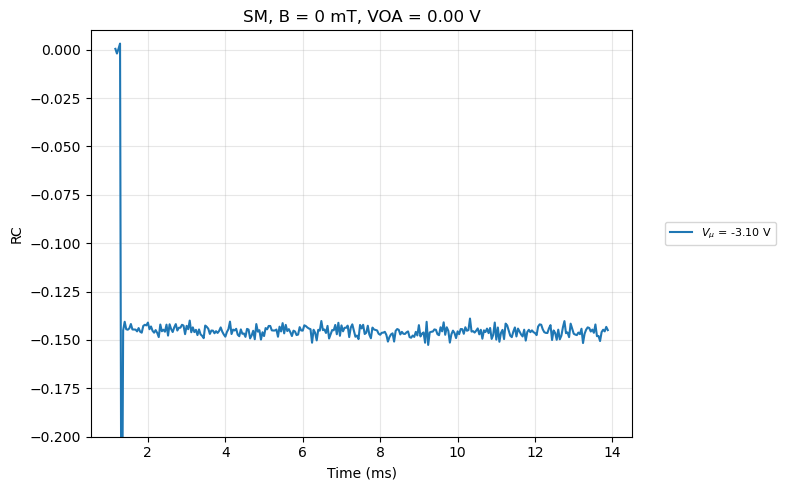

In [476]:

bin_us = 40

t_plot = (1.15, 13.9)
ref_range = [1.15, 1.25]


# --- fixed reference trace ---
fig_ref, ax_ref, ref_traces = plot_sync_traces(
    [REF_ACQ],
    sync_tick_stride=100,
    bin_us=10,
    t0_method="metadata_windows",
    unit="ms",
    data_root=DATA_ROOT,
    y_mode="self_normalized",
    ref_range=ref_range,
    save_fig=True,
    force_recompute=force_recompute,
)
fixed_ref = ref_traces[0]["plot_y"] + 1
t_ref = ref_traces[0]["time_us"] / 1e3
plt.close(fig_ref)


# --- find acqs, compute/save corrected traces if missing ---
all_acqs = matching_acqs_by_parameters(
    metadata_filters={},
    data_root=DATA_ROOT,
    require_raw=False,
    require_analysis=True,
)

rows = []
for sig_acq in all_acqs:
    entries = get_metadata_entries(
        [sig_acq],
        keys=[
            "Vmu",
            "voa_requested_initial_voltage",
            "metadata.B_field",
            "metadata.Exc_pol",
        ],
        data_root=DATA_ROOT,
    )[0]

    vmu = float(entries.get("Vmu", np.nan))
    voa = float(entries.get("voa_requested_initial_voltage", np.nan))
    B = float(entries.get("metadata.B_field", np.nan))
    pol = str(entries.get("metadata.Exc_pol"))

    cache_dir = DATA_ROOT / f"acq_{sig_acq}_pump_probe_folded"
    out_path = cache_dir / f"acq_{sig_acq}_corrected_by_acq_{REF_ACQ}_bin{bin_us}us_metadata_windows.npz"

    if not out_path.exists():
        fig, ax, traces = plot_sync_traces(
            [sig_acq],
            sync_tick_stride=100,
            bin_us=bin_us,
            t0_method="metadata_windows",
            unit="ms",
            data_root=DATA_ROOT,
            y_mode="self_normalized",
            ref_range=ref_range,
            save_fig=True,
            force_recompute=force_recompute,
            legend_metadata={
                r"$V_\mu$": {"key": "metadata.Vmu", "unit": "V", "fmt": ".2f"},
                "VOA": "metadata.voa_requested_initial_voltage",
            },
        )
        plt.close(fig)

        sig = traces[0]["plot_y"] + 1
        t = traces[0]["time_us"] / 1e3
        ref = np.interp(t, t_ref, fixed_ref)

        valid = np.isfinite(sig) & np.isfinite(ref) & (ref != 0)
        corr = np.full_like(sig, np.nan, dtype=float)
        corr[valid] = sig[valid] / ref[valid]

        np.savez_compressed(
            out_path,
            time_ms=t,
            corrected=corr - 1,
            corr_raw=corr,
            signal=sig,
            reference_interp=ref,
            reference_acq=REF_ACQ,
            signal_acq=sig_acq,
            Vmu=vmu,
            B_field=B,
            Exc_pol=pol,
            voa_requested_initial_voltage=voa,
            x_pos=xs,
            y_pos=ys,
            t0_method="metadata_windows",
            bin_us=bin_us,
            ref_range=np.array(ref_range),
        )

    rows.append({
        "acq": sig_acq,
        "vmu": vmu,
        "voa": voa,
        "B": B,
        "pol": pol,
        "path": out_path,
    })

print(f"prepared {len(rows)} corrected traces")


for pol in pols:
    for B_target in B_targets:
        for voa_target in voa_targets:
            use = [
                r for r in rows
                if r["path"].exists()
                and (pol == "" or r["pol"].upper() == pol.upper())
                and np.isclose(r["B"], B_target, atol=1e-4)
                and np.isclose(r["voa"], voa_target, atol=1e-4)
                and np.isfinite(r["vmu"])
            ]
            use = sorted(use, key=lambda r: r["vmu"])

            if not use:
                print(f"no traces for {pol}, B={B_target*1e3:g} mT, VOA={voa_target:.2f} V")
                continue

            fig_corr, ax_corr = plt.subplots(figsize=(8, 5))

            for r in use:
                z = np.load(r["path"])
                t = z["time_ms"]
                y = z["corrected"]

                mask = (
                    (t > t_plot[0])
                    & (t < t_plot[1])
                    & np.isfinite(t)
                    & np.isfinite(y)
                )

                label = rf"$V_\mu$ = {r['vmu']:.2f} V"
                ax_corr.plot(t[mask], y[mask], label=label)

            ax_corr.set_title(f"{pol}, B = {B_target*1e3:g} mT, VOA = {voa_target:.2f} V")
            ax_corr.set_xlabel("Time (ms)")
            ax_corr.set_ylabel("RC")
            ax_corr.set_ylim(*ylim)
            ax_corr.grid(alpha=0.3)
            ax_corr.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.05, 0.5))
            fig_corr.tight_layout()


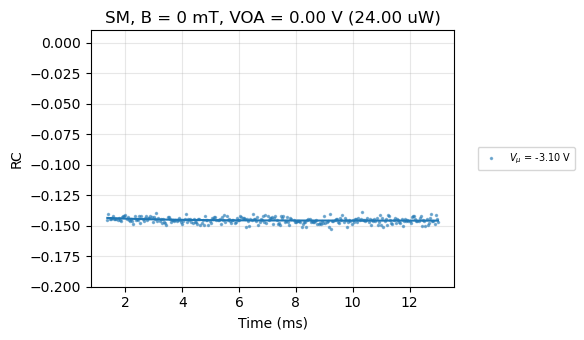

In [477]:
from scipy.optimize import curve_fit

def exp_decay(t, y0, A, tau):
    t0 = np.nanmin(t)
    return y0 + A * np.exp(-(t - t0) / tau)

all_fits_by_setting = {}

all_acqs = matching_acqs_by_parameters(
    metadata_filters={},
    data_root=DATA_ROOT,
    require_raw=False,
    require_analysis=True,
)

for pol in pols:
    for B_target in B_targets:
        for voa_target in voa_targets:
            fits_dict = {}

            matched = []
            for acq in all_acqs:
                e = get_metadata_entries(
                    [acq],
                    keys=[
                        "Vmu",
                        "voa_requested_initial_voltage",
                        "metadata.B_field",
                        "metadata.Exc_pol",
                        "metadata.description",
                    ],
                    data_root=DATA_ROOT,
                )[0]

                vmu = float(e.get("Vmu", np.nan))
                voa = float(e.get("voa_requested_initial_voltage", np.nan))
                B = float(e.get("metadata.B_field", np.nan))
                acq_pol = str(e.get("metadata.Exc_pol"))

                if not (
                    acq_pol.upper() == pol.upper()
                    and np.isclose(B, B_target, atol=1e-4)
                    and np.isclose(voa, voa_target, atol=1e-3)
                    and np.isfinite(vmu)
                ):
                    continue

                cache_dir = DATA_ROOT / f"acq_{acq}_pump_probe_folded"
                out_path = cache_dir / f"acq_{acq}_corrected_by_acq_{REF_ACQ}_bin{bin_us}us_metadata_windows.npz"
                if not out_path.exists():
                    print("missing corrected cache:", out_path)
                    continue

                matched.append((acq, vmu, voa, B, acq_pol, e, out_path))

            matched = sorted(matched, key=lambda x: x[1])  # sort by Vmu

            if not matched:
                print(f"no fit inputs for {pol}, B={B_target*1e3:g} mT, VOA={voa_target:.2f} V")
                continue

            fig_corr, ax_corr = plt.subplots(figsize=(6, 3.5))

            for sig_acq, vmu, voa, B, acq_pol, entries, out_path in matched:
                z = np.load(out_path)
                t_all = z["time_ms"]
                y_all = z["corrected"]

                mask = (
                    (t_all > fit_range[0])
                    & (t_all < fit_range[1])
                    & np.isfinite(t_all)
                    & np.isfinite(y_all)
                    & (y_all > fit_y_range[0])
                    & (y_all < fit_y_range[1])
                )
                t = t_all[mask]
                y = y_all[mask]

                if len(t) < 5:
                    print(f"too few points for acq {sig_acq}")
                    continue

                y0_guess = np.nanmean(y[-max(3, len(y)//10):])
                A_guess = y[0] - y0_guess
                tau_guess = 1.0

                try:
                    popt, pcov = curve_fit(
                        exp_decay,
                        t,
                        y,
                        p0=[y0_guess, A_guess, tau_guess],
                        bounds=([-np.inf, -np.inf, 1e-6], [np.inf, np.inf, np.inf]),
                        maxfev=10000,
                    )
                    perr = np.sqrt(np.diag(pcov))
                except Exception as exc:
                    print(f"Fit failed for acq {sig_acq}: {exc}")
                    continue

                y0_fit, A_fit, tau_fit = popt
                y0_err, A_err, tau_err = perr

                fits_dict[sig_acq] = {
                    "acq": int(sig_acq),
                    "x": float(xs),
                    "y": float(ys),
                    "pol": acq_pol,
                    "B": B,
                    "vmu": vmu,
                    "voa": voa,
                    "power_uW": float(voa_erf_transmission_norm(voa) * 15),
                    "description": entries.get("metadata.description", ""),
                    "popt": popt,
                    "pcov": pcov,
                    "y0": y0_fit,
                    "A": A_fit,
                    "tau": tau_fit,
                    "y0_err": y0_err,
                    "A_err": A_err,
                    "tau_err": tau_err,
                }

                label = rf"$V_\mu$ = {vmu:.2f} V"
                data_scat = ax_corr.plot(t, y, ".", ms=3, label=label, alpha=0.5)

                t_fit = np.linspace(np.nanmin(t), np.nanmax(t), 500)
                ax_corr.plot(
                    t_fit,
                    exp_decay(t_fit, *popt),
                    "-",
                    color=data_scat[0].get_color(),
                )

            fit_rows = sorted(fits_dict.values(), key=lambda d: d["vmu"])
            if not fit_rows:
                plt.close(fig_corr)
                continue

            setting_key = (pol, B_target, voa_target)
            all_fits_by_setting[setting_key] = fit_rows

            power_uW = voa_erf_transmission_norm(voa_target) * MAX_LG_POWER
            ax_corr.set_title(
                f"{pol}, B = {B_target*1e3:g} mT, VOA = {voa_target:.2f} V ({power_uW:.2f} uW)"
            )
            ax_corr.set_xlabel("Time (ms)")
            ax_corr.set_ylabel("RC")
            ax_corr.set_ylim(*ylim)
            ax_corr.grid(alpha=0.3)
            ax_corr.legend(fontsize=7, loc="center left", bbox_to_anchor=(1.05, 0.5))
            fig_corr.tight_layout()

            vmu = np.array([d["vmu"] for d in fit_rows])
            tau = np.array([d["tau"] for d in fit_rows])
            tau_err = np.array([d["tau_err"] for d in fit_rows])
            amp = np.array([d["A"] for d in fit_rows])
            amp_err = np.array([d["A_err"] for d in fit_rows])
            y0 = np.array([d["y0"] for d in fit_rows])
            y0_err = np.array([d["y0_err"] for d in fit_rows])

            fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))

            axes[0].errorbar(vmu, tau, yerr=tau_err, fmt="o-", capsize=3)
            axes[0].set_xlabel(r"$V_\mu$ (V)")
            axes[0].set_ylabel(r"$\tau$ (ms)")
            axes[0].grid(alpha=0.3)
            axes[0].set_ylim(-1,15)

            axes[1].errorbar(vmu, amp, yerr=amp_err, fmt="o-", capsize=3)
            axes[1].axhline(0, color="0.3", ls="--", lw=1)
            axes[1].set_xlabel(r"$V_\mu$ (V)")
            axes[1].set_ylabel("A")
            axes[1].grid(alpha=0.3)
            axes[1].set_ylim(-0.018, 0.002)

            axes[2].errorbar(vmu, y0, yerr=y0_err, fmt="o-", capsize=3, label=r"$R_0$")
            axes[2].errorbar(
                vmu,
                y0 + amp,
                yerr=np.sqrt(y0_err**2 + amp_err**2),
                fmt="s--",
                capsize=3,
                label=r"$R_0 + A$",
            )
            axes[2].axhline(0, color="0.3", ls="--", lw=1)
            axes[2].set_xlabel(r"$V_\mu$ (V)")
            axes[2].set_ylabel("RC level")
            axes[2].grid(alpha=0.3)
            axes[2].set_ylim(*ylim)
            axes[2].legend(fontsize=7)

            fig.suptitle(
                f"{pol}, B = {B_target*1e3:g} mT, VOA = {voa_target:.2f} V ({power_uW:.2f} uW)"
            )
            fig.tight_layout()
            plt.close(fig)

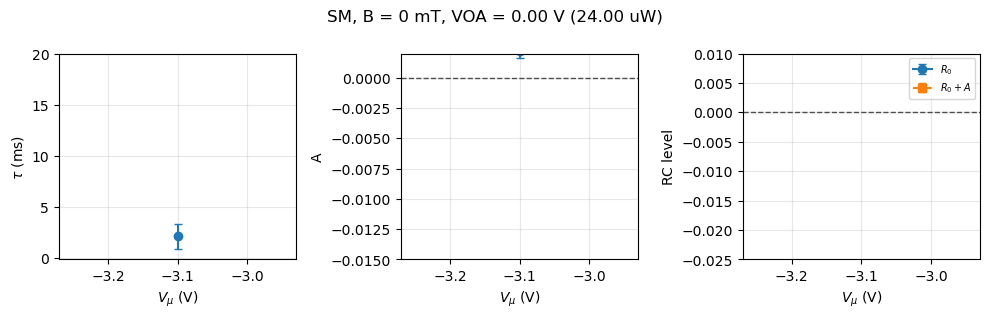

In [474]:
axes[0].set_ylim(-0.1,20)
axes[1].set_ylim(-0.015,0.002)


display(fig)

In [469]:
voa_erf_transmission_norm(3.3)*MAX_LG_POWER

0.7950012000000001